# EMA4002 Data Mining · Lab 3
## From describing data to discovering patterns: the Saigon Bean coffee chain

**Faculty of Economic Mathematics, University of Economics and Law, VNU-HCM**  
**Huynh Tan Phat - K234131613** 
Version: **Student solution** (all Practices 1–8 filled)

This lab goes with the two decks of Lecture 3.

| Deck | Sections | What you practice |
|---|---|---|
| Deck 1: *Mining Descriptive Statistics* | 3.1 to 3.4 | attribute types, central tendency and dispersion, charts, similarity and distance |
| Deck 2: *Characterization and Comparison* | 3.5 to 3.8 | attribute relevance, generalization (AOI), class comparison, association rules |

### How the notebook works
Every section follows the same rhythm.

1. **Worked example.** Run the cell, then read the explanation under it. The code rebuilds the numbers on the slides, so you can see where each one comes from.
2. **Check against the slide.** A small function `check()` prints ✓ when your number agrees with the slide.
3. **Practice.** Your turn. Write the code, then answer in plain business language.

A number without a sentence is not an answer. Write every interpretation for a manager who will never read your code.

### The story
Saigon Bean is a fictional coffee chain with 12 stores in Ho Chi Minh City, 17 products and three sales channels (in-store, app, delivery). Head office has released the receipts for June, July and August 2026. The data is synthetic. The patterns in it, and the mistakes in it, are the ones you will meet in real point-of-sale files.


| Task | What to produce | Section |
|---|---|---|
| Task 1 | Load the three files, join them, report the shape | 3.1.1 |
| Task 2 | Attribute-type table, find and repair the five faults, keep walk-in customers with a flag | 3.1.3 to 3.1.6 |
| Task 3 | Reproduce the statistics of slides 20 and 24, draw the histogram, the boxplot and the scatter | 3.2 and 3.3 |
| Task 4 | Practice 1 to Practice 4 | end of 3.1 to 3.4 |
| Task 5 | 12 by 12 dissimilarity matrix of the stores, closest and furthest pairs | 3.4.9 |
| Part B | Practice 5 to Practice 8 | end of 3.5 to 3.8 |


## 0. Setup

Upload the three CSV files to Colab with the folder icon on the left, or mount your Google Drive and point `DATA_DIR` to the folder that holds them:

* `saigon_bean_transactions.csv`, one line of one receipt per row
* `saigon_bean_stores.csv`, one store per row
* `saigon_bean_products.csv`, one menu item per row

The loader below also finds copies that your browser renamed, such as `saigon_bean_stores (1).csv`.

In [1]:
# Libraries. All of them come pre-installed in Google Colab.
import glob, math, os, statistics
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
# DATA_DIR = '.'      # in Colab, '.' is the folder you upload into
# from google.colab import drive; drive.mount('/content/drive')
# DATA_DIR = '/content/drive/MyDrive/EMA4002'

# How pandas prints numbers: amounts of 1,000 or more without decimals, smaller numbers with up to four.
def _fmt(v):
    if pd.isna(v):
        return 'NaN'
    if abs(v) >= 1000:
        return f'{v:,.0f}'
    return f'{v:,.4f}'.rstrip('0').rstrip('.')

pd.set_option('display.float_format', _fmt)
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 120)

# Chart style: thin marks, a light grid, blue for one series and orange to highlight.
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.figsize': (8, 4), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': INK2, 'text.color': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2, 'legend.frameon': False, 'font.size': 10,
})
thousands = FuncFormatter(lambda v, _: f'{v / 1000:,.0f}k')     # axis labels such as 100k


def find_file(stem):
    '''Return the CSV in DATA_DIR whose name starts with `stem`.'''
    hits = sorted(glob.glob(os.path.join(DATA_DIR, stem + '*.csv')))
    if not hits:
        raise FileNotFoundError(f'No {stem}*.csv in {os.path.abspath(DATA_DIR)}. '
                                'Upload the file or change DATA_DIR.')
    return hits[0]


def parse_time(s):
    '''The file was saved from Excel: 6/1/2026 7:00 means 1 June 2026 at 07:00 (month first).'''
    for fmt in ('%m/%d/%Y %H:%M', '%Y-%m-%d %H:%M:%S', '%Y-%m-%d %H:%M'):
        try:
            return pd.to_datetime(s, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.to_datetime(s)


def vnd(x):
    '''A number of dong with thousands separators, e.g. 108,856.'''
    return f'{x:,.0f}'


def check(label, value, slide, decimals=0):
    '''Print your number next to the number on the slide. ✓ means they agree after rounding.'''
    ok = round(float(value), decimals) == round(float(slide), decimals)
    print(f"{label:<36}{value:>16,.{decimals}f}   slide {slide:>14,.{decimals}f}   {'✓' if ok else '✗ differs'}")


print('pandas', pd.__version__, '| numpy', np.__version__, '| ready')

pandas 2.3.3 | numpy 2.3.5 | ready


---
# PART A · Mining descriptive statistics (Deck 1)

# 3.1 Data classification
*Deck 1, slides 5 to 15. Lab tasks 1 and 2.*

Before you compute anything, you need to know what each column **is**. The attribute type decides which statistics are allowed, which chart fits, and which distance measure makes sense later in 3.4.

## 3.1.1 Load the three files and join them (Task 1)

In [2]:
import gdown

FILES = ["saigon_bean_stores.csv", "saigon_bean_products.csv", "saigon_bean_transactions.csv"]
FOLDER_ID = "14ayONW215wjraj_-D5ZYCbYdq3LFTR_0"
# Prefer local path if already downloaded; fall back to /content for Colab
import os
if os.path.isdir("/home/workdir/artifacts/data_saigon_bean"):
    DATA_DIR = "/home/workdir/artifacts/data_saigon_bean"
elif os.path.isdir("/content/data_saigon_bean"):
    DATA_DIR = "/content/data_saigon_bean"
else:
    DATA_DIR = "data_saigon_bean"
print("DATA_DIR =", DATA_DIR)


DATA_DIR = /content/data_saigon_bean


In [3]:
import os, glob
os.makedirs(DATA_DIR, exist_ok=True)

def locate(fname):
    hits = glob.glob(os.path.join(DATA_DIR, "**", fname), recursive=True)
    return hits[0] if hits else None

paths = {f: locate(f) for f in FILES}
missing = [f for f, p in paths.items() if p is None]
if missing:
    print("Downloading missing files:", missing)
    gdown.download_folder(id=FOLDER_ID, output=DATA_DIR, quiet=True, use_cookies=False)
    paths = {f: locate(f) for f in FILES}
    missing = [f for f, p in paths.items() if p is None]
    if missing:
        raise FileNotFoundError(f"Không tìm thấy: {missing}. Kiểm tra quyền chia sẻ folder và tên file.")

money = FuncFormatter(lambda v, _: f"{v/1000:,.0f}k")
print("Data files found:", paths)


Data files found: {'saigon_bean_stores.csv': '/content/data_saigon_bean\\saigon_bean_stores.csv', 'saigon_bean_products.csv': '/content/data_saigon_bean\\saigon_bean_products.csv', 'saigon_bean_transactions.csv': '/content/data_saigon_bean\\saigon_bean_transactions.csv'}


In [4]:
tx_raw   = pd.read_csv(paths["saigon_bean_transactions.csv"])
stores   = pd.read_csv(paths["saigon_bean_stores.csv"]) 
products = pd.read_csv(paths["saigon_bean_products.csv"]) 
tx_raw['customer_id'] = tx_raw['customer_id'].astype('Int64')     # an identifier: a whole number that may be missing

print('transactions', tx_raw.shape, '| stores', stores.shape, '| products', products.shape)
display(tx_raw.head())

transactions (97239, 10) | stores (12, 5) | products (17, 4)


,order_id,store_id,order_time,channel,customer_id,product_id,quantity,unit_price,discount,line_total
0,519273,4,6/1/2026 7:00,delivery,<NA>,101,1,45000,0,45000
1,519273,4,6/1/2026 7:00,delivery,<NA>,301,1,31500,0,31500
2,524107,5,6/1/2026 7:06,in-store,12417,103,1,52000,0,52000
3,500071,1,6/1/2026 7:07,in-store,<NA>,201,2,45000,0,90000
4,500071,1,6/1/2026 7:07,in-store,<NA>,202,2,42000,0,84000


**What you see.** The transaction file has 97,239 rows and 10 columns. One row is one line of one receipt, so an order with a coffee and a croissant takes two rows with the same `order_id`. The store file (12 rows) and the product file (17 rows) are small reference tables. In warehouse language from Chapter 2, stores and products are dimensions and the transactions are the facts.

`customer_id` is empty on many rows, so pandas would read it as a decimal number (12417.0). The type `Int64` keeps it a whole number and shows an empty value as `<NA>`.

In [5]:
tx_raw['order_time'] = parse_time(tx_raw['order_time'])

first, last = tx_raw['order_time'].min(), tx_raw['order_time'].max()
print('first order :', first)
print('last order  :', last)
print('trading days:', tx_raw['order_time'].dt.date.nunique())

first order : 2026-06-01 07:00:00
last order  : 2026-08-31 21:59:00
trading days: 92


**Why the date needs care.** The file shows `6/1/2026 7:00`. A Vietnamese reader sees 6 January, but Excel wrote the date month first, so it means 1 June. The parsed range runs from 1 June to 31 August 2026 at 21:59, which is 92 trading days. That range is the proof that the parse is right: if you read the day first, a value such as `8/31/2026` would be impossible.

In [6]:
df = (tx_raw
      .merge(stores,   on='store_id',   how='left', validate='many_to_one')
      .merge(products, on='product_id', how='left', validate='many_to_one'))

print('joined table:', df.shape)
print('lines with no matching store or product:', df[['store_name', 'product_name']].isna().any(axis=1).sum())
print(f"order lines          : {len(df):,}")
print(f"orders (receipts)    : {df['order_id'].nunique():,}")
print(f"identified customers : {df['customer_id'].nunique():,}")

joined table: (97239, 17)
lines with no matching store or product: 0
order lines          : 97,239
orders (receipts)    : 51,108
identified customers : 4,777


**Reading the result.** The joined table keeps all 97,239 lines and gains the store and product columns, 17 columns in total. Every line found its store and its product. The option `validate='many_to_one'` is a safety belt. Without it, a `store_id` that appeared twice in the store file would silently copy receipt lines. With it, pandas stops with an error.

The counts match slide 4: 51,108 orders and 4,777 identified customers.

## 3.1.2 Objects and attributes
*Slide 8.* A row is a **data object** (a store, a product, a receipt line). A column is an **attribute** (also called a dimension, a feature or a variable).

In [7]:
display(stores.loc[[0, 6, 10]])     # three objects: Nguyen Hue, University Village, Tan Son Nhat T1

,store_id,store_name,district,store_type,seats
0,1,Nguyen Hue,District 1,mall,70
6,7,University Village,Thu Duc,campus,40
10,11,Tan Son Nhat T1,Tan Binh,transit,24


Read the table in two directions. Down a column you describe one attribute across all stores, for example the seat counts. Across a row you describe one store on all its attributes. Sections 3.2 and 3.3 work down the columns. Section 3.4 works across the rows.

## 3.1.3 The type of every column (Task 2, part 1)
*Slides 9 to 13.* The four types are **nominal**, **binary**, **ordinal** and **numeric**. Numeric splits into **interval** (no true zero) and **ratio** (a true zero), and into **discrete** and **continuous**.

The type is a decision you make about the meaning of a column. pandas only knows how the column is stored.

In [8]:
attribute_type = {
    'order_id':    ('nominal',                    'a number used as a label'),
    'store_id':    ('nominal',                    'a key, not a quantity'),
    'order_time':  ('numeric, interval',          'differences are meaningful, there is no true zero'),
    'channel':     ('nominal',                    'unordered categories'),
    'customer_id': ('nominal',                    'a label, empty means a walk-in customer'),
    'product_id':  ('nominal',                    'a key into the product table'),
    'quantity':    ('numeric, ratio, discrete',   'a count, zero means none'),
    'unit_price':  ('numeric, ratio, continuous', 'money with a true zero'),
    'discount':    ('numeric, ratio, continuous', 'a rate: 0.10 means 10% off'),
    'line_total':  ('numeric, ratio, continuous', 'quantity x unit_price x (1 - discount)'),
}

rows = []
for col, (kind, why) in attribute_type.items():
    s = tx_raw[col]
    rows.append({'attribute': col, 'type': kind, 'pandas dtype': str(s.dtype),
                 'distinct': s.nunique(), 'missing %': round(s.isna().mean() * 100, 1),
                 'min': s.min() if kind.startswith('numeric') else '',
                 'max': s.max() if kind.startswith('numeric') else '',
                 'why': why})
display(pd.DataFrame(rows).set_index('attribute'))
print(f"share of lines with no discount: {(tx_raw['discount'] == 0).mean():.1%}")

,type,pandas dtype,distinct,missing %,min,max,why
attribute,,,,,,,
order_id,nominal,int64,51108,0,,,a number used as a label
store_id,nominal,int64,12,0,,,"a key, not a quantity"
order_time,"numeric, interval",datetime64[ns],36678,0,2026-06-01 07:00:00,2026-08-31 21:59:00,"differences are meaningful, there is no true zero"
channel,nominal,object,6,0,,,unordered categories
customer_id,nominal,Int64,4777,34.5,,,"a label, empty means a walk-in customer"
product_id,nominal,int64,17,0,,,a key into the product table
quantity,"numeric, ratio, discrete",int64,4,0,-2,2,"a count, zero means none"
unit_price,"numeric, ratio, continuous",int64,14,0,25000,5500000,money with a true zero
discount,"numeric, ratio, continuous",float64,4,0,0,0.2,a rate: 0.10 means 10% off


share of lines with no discount: 93.4%


**Reading the table (compare with slide 13).**
* Four columns hold integers that must never be averaged: `order_id`, `store_id`, `customer_id` and `product_id`. pandas stores them as numbers, yet each one is a label. The average of store 1 and store 12 is not store 6.5.
* `order_time` is interval-scaled. You may subtract two times (the file covers 92 days). You may not say that 14:00 is twice 07:00.
* Money and counts are ratio-scaled, because zero dong and zero cups both mean *none*. A 70-seat store really has twice the seating of a 35-seat store.
* `discount` is a rate between 0 and 0.20. It is zero on 93.4% of the lines.
* Look at the minimum and maximum columns. A quantity of −2, a unit price of 5,500,000 dong and a line total of 11,000,000 dong cannot be right for a coffee shop. Those are the faults of the next step.

## 3.1.4 What each type lets you compute
*Slide 14.*

| Operation | Nominal | Binary | Ordinal | Interval | Ratio |
|---|:---:|:---:|:---:|:---:|:---:|
| count, frequency, mode | yes | yes | yes | yes | yes |
| median and quantiles | no | no | yes | yes | yes |
| add and subtract, mean, standard deviation | no | no | no | yes | yes |
| multiply, divide, ratios | no | no | no | no | yes |

The cell below performs one allowed operation for each type, so you can see the vocabulary in code.

In [9]:
print('nominal  -> frequencies and mode of store_type:')
print(stores['store_type'].value_counts().to_string(), '\n')

print('interval -> a difference of two times:', tx_raw['order_time'].max() - tx_raw['order_time'].min())
print('ratio    -> Nguyen Hue has', round(70 / 24, 2), 'times the seats of Tan Son Nhat T1')

nominal  -> frequencies and mode of store_type:
store_type
mall           6
campus         2
residential    2
transit        2 

interval -> a difference of two times: 91 days 14:59:00
ratio    -> Nguyen Hue has 2.92 times the seats of Tan Son Nhat T1


## 3.1.5 Find the five faults (Task 2, part 2)
*Slides 10 and 13.* Head office believes the export is clean. It is not. Measure the size of every problem **before** you repair anything.

### Fault 1. One channel, two spellings

In [10]:
print(df['channel'].value_counts().to_string())

channel
in-store    60939
app         23057
delivery    13213
In-Store       19
Delivery        6
App             5


Three real channels appear under six spellings. Thirty rows use capitals (`In-Store` 19, `Delivery` 6, `App` 5). A person sees three categories. `groupby('channel')` sees six, so every channel report would carry three extra rows and slightly understate each true channel.

### Fault 2. Negative quantities

In [11]:
neg = df['quantity'] < 0
print('lines with a negative quantity:', neg.sum())
print(df.loc[neg, 'quantity'].value_counts().to_string())
display(df.loc[neg, ['order_id', 'store_name', 'product_name', 'quantity', 'unit_price', 'line_total']].head(6))

refund_only = df.groupby('order_id')['quantity'].max() < 0
print('orders made only of negative lines:', refund_only.sum())

lines with a negative quantity: 25
quantity
-1    19
-2     6


,order_id,store_name,product_name,quantity,unit_price,line_total
2194,513532,Landmark 81,Coconut Coffee,-2,59000,-118000
4957,532389,University Village,Peach Tea,-1,45000,-45000
9561,548135,Dien Bien Phu Hub,Peach Tea,-1,45000,-45000
10364,514006,Landmark 81,Black Coffee,-1,39000,-39000
15410,537023,Phu Nhuan Corner,Cappuccino,-1,52000,-52000
16007,537047,Phu Nhuan Corner,Butter Croissant,-1,31500,-31500


orders made only of negative lines: 2


Twenty-five lines carry a quantity of −1 or −2 and a negative line total, down to −118,000 dong. They look like refunds or voided items. Either way they are not sales. Two orders contain nothing else, so removing these lines also removes two receipts: 51,108 orders become 51,106.

### Fault 3. Prices one hundred times the menu price

In [12]:
price_error = df['unit_price'] >= 10 * df['list_price']
print('lines priced at 10 x the list price or more:', price_error.sum())
print('ratio unit_price / list_price on those lines:', (df.loc[price_error, 'unit_price'] / df.loc[price_error, 'list_price']).unique())
display(df.loc[price_error, ['order_id', 'store_name', 'product_name', 'quantity', 'list_price', 'unit_price', 'line_total']])

lines priced at 10 x the list price or more: 12
ratio unit_price / list_price on those lines: [100.]


,order_id,store_name,product_name,quantity,list_price,unit_price,line_total
11610,528853,Van Hanh Mall,Cheesecake Slice,2,55000,5500000,11000000
17656,537107,Phu Nhuan Corner,Americano,1,45000,4500000,4500000
27658,548790,Dien Bien Phu Hub,Green Tea Latte,1,55000,5500000,5500000
39019,502865,Nguyen Hue,Butter Croissant,1,31500,3150000,3150000
39527,537743,Phu Nhuan Corner,Butter Croissant,1,31500,3150000,3150000
70836,527254,Crescent Mall,Butter Croissant,1,31500,3150000,3150000
74350,512067,Ben Thanh,Latte,2,52000,5200000,10400000
79422,527630,Crescent Mall,Cheesecake Slice,2,55000,5500000,11000000
80211,531621,Van Hanh Mall,Vietnamese Iced Milk Coffee,2,45000,4500000,9000000
87835,506235,Nguyen Hue,Butter Croissant,1,31500,3150000,3150000


Twelve lines are priced at **exactly** 100 times the menu price: a croissant at 3,150,000 dong, a cheesecake at 5,500,000 dong. Somebody typed two extra zeros. The regularity is the evidence. You can only call a value an error by comparing it with something that should agree with it, here `list_price`. A boxplot or a three-sigma rule only knows that the value is large, so it cannot tell a mistake from a genuine group order.

### Fault 4. Lines exported twice

In [13]:
dup = tx_raw.duplicated()
print('exact duplicate lines:', dup.sum())
print('stores affected:', tx_raw.loc[dup, 'store_id'].nunique(), 'of 12')
first_dup = tx_raw.loc[dup, 'order_id'].iloc[0]
display(tx_raw[tx_raw['order_id'] == first_dup])

exact duplicate lines: 40
stores affected: 11 of 12


,order_id,store_id,order_time,channel,customer_id,product_id,quantity,unit_price,discount,line_total
774,542160,11,2026-06-01 15:55:00,in-store,11787,201,1,45000,0,45000
775,542160,11,2026-06-01 15:55:00,in-store,11787,201,1,45000,0,45000


Forty lines are perfect copies of another line: same order, same minute, same product, same price. A till records two identical drinks as one line with quantity 2, so a perfect copy comes from the export and not from the customer. Duplicates double-count revenue and inflate every count of lines and cups. They do not change which products share a receipt, so the basket analysis of Section 3.8 would survive them. Every revenue figure would not.

### Fault 5. Missing customer_id (a fault that is not an error)

In [14]:
missing = df['customer_id'].isna()
print(f"lines without customer_id: {missing.sum():,} ({missing.mean():.1%})")
print('channel of those lines:')
print(df.loc[missing, 'channel'].str.lower().value_counts().to_string())

lines without customer_id: 33,569 (34.5%)
channel of those lines:
channel
in-store    27646
delivery     5923


A third of the lines have no `customer_id`. None of them is an app order, which tells you what an empty value means: a walk-in customer who did not show a loyalty card. That is information about the customer. Deleting these rows would discard 34.5% of the sales and bias every later result toward members, who buy more often. The right move is to **keep the rows and add a flag**.

## 3.1.6 Repair, and keep two versions of the data (Task 2, part 3)

Repairing is a decision, and the order of the decisions matters. We keep two versions of the sales lines.

| Version | What is done | Used in |
|---|---|---|
| **Stage A**, `stage_a` | refund lines removed, channel spelling fixed, `is_member` flag added. Nothing else is touched. | 3.1 to 3.4, so that every number can be compared with Deck 1 |
| **Stage B**, `stage_b` | Stage A, then duplicates removed and the twelve prices corrected from the product table | 3.5 to 3.8 (Deck 2) |

Stage A deliberately keeps the duplicates and the price errors. Deck 1 uses them to show what dirty values do to a mean and a standard deviation, and Practice 2 measures that damage.

In [15]:
# Stage A: only the impossible rows go, and the channel labels are unified.
stage_a = df[df['quantity'] > 0].copy()
stage_a['channel'] = stage_a['channel'].str.strip().str.lower()
stage_a['is_member'] = stage_a['customer_id'].notna()

# Stage B: start from Stage A and repair the remaining faults.
stage_b = stage_a.drop_duplicates(subset=list(tx_raw.columns)).copy()
fix = stage_b['unit_price'] >= 10 * stage_b['list_price']
stage_b['price_fixed'] = fix
stage_b.loc[fix, 'unit_price'] = stage_b.loc[fix, 'list_price']
stage_b['line_total'] = (stage_b['quantity'] * stage_b['unit_price'] * (1 - stage_b['discount'])).round().astype('int64')

versions = {'raw file': df, 'Stage A (slides)': stage_a, 'Stage B (repaired)': stage_b}
summary = pd.DataFrame({
    'lines':  {k: len(v) for k, v in versions.items()},
    'orders': {k: v['order_id'].nunique() for k, v in versions.items()},
    'revenue, million VND': {k: v['line_total'].sum() / 1e6 for k, v in versions.items()},
})
display(summary)
print('prices corrected in Stage B:', fix.sum())
print(f"lines from identified members: {stage_b['is_member'].mean():.1%}")
print('channels now:', sorted(stage_b['channel'].unique()))

,lines,orders,"revenue, million VND"
raw file,97239,51108,"5,562"
Stage A (slides),97214,51106,"5,563"
Stage B (repaired),97174,51106,"5,490"


prices corrected in Stage B: 12
lines from identified members: 65.5%
channels now: ['app', 'delivery', 'in-store']


**Reading the result.**
* Stage A has 97,214 lines and 51,106 orders. These are the sample sizes printed on slide 20.
* Stage B removes 40 duplicate lines and corrects 12 prices. Revenue falls by about 73 million dong: 71 million came from the twelve typed prices and 2 million from the duplicated lines. Twelve lines out of 97,214 (0.01%) moved the revenue of the chain by 1.3%.
* 65.5% of the lines come from identified members. The other 34.5% stay in the data as walk-in customers.

## 3.1.7 A binary and an ordinal attribute we will reuse
*Slides 10 and 11.*

* **Binary, asymmetric.** `bought_merchandise` says whether a receipt contains a tumbler or a bag of beans. A 1 is rare and informative. Two receipts that both lack merchandise share nothing in particular.
* **Ordinal.** `seats_band` turns seats into small (16 to 30), medium (31 to 50) and large (51 to 70). The order is meaningful and the gaps are not.

In [16]:
# Binary attribute, one value per receipt
merch_line = stage_a['category'].eq('merchandise')
bought_merchandise = merch_line.groupby(stage_a['order_id']).any()
print(f"receipts with merchandise : {bought_merchandise.mean():.2%}")
print(f"revenue from merchandise  : {stage_a.loc[merch_line, 'line_total'].sum() / stage_a['line_total'].sum():.1%}")

# Ordinal attribute, one value per store. pd.cut returns an ordered category.
stores['seats_band'] = pd.cut(stores['seats'], bins=[15, 30, 50, 70], labels=['small', 'medium', 'large'])
display(stores[['store_name', 'seats', 'seats_band']])

# The median is allowed for an ordinal attribute: sort the bands and take the middle one.
codes = stores['seats_band'].cat.codes.sort_values().to_numpy()
print('median band:', stores['seats_band'].cat.categories[int(np.median(codes))])

receipts with merchandise : 0.63%
revenue from merchandise  : 1.4%


,store_name,seats,seats_band
0,Nguyen Hue,70,large
1,Ben Thanh,62,large
2,Landmark 81,58,large
3,Vincom Dong Khoi,54,large
4,Crescent Mall,48,medium
5,Van Hanh Mall,44,medium
6,University Village,40,medium
7,RMIT Campus,36,medium
8,Phu Nhuan Corner,32,medium
9,Binh Thanh Garden,30,small


median band: medium


Only 0.6% of receipts contain merchandise, and merchandise earns 1.4% of revenue (slide 10). The median seat band is *medium*, which is a legitimate summary of an ordinal attribute. The *mean* band does not exist: nobody can say whether the step from small to medium equals the step from medium to large.

## Practice 1
*Slide 15.*

**P1.1** Classify every column of `saigon_bean_stores.csv` and `saigon_bean_products.csv` by attribute type, and mark each numeric column as discrete or continuous.

**P1.2** For each of the five faults, say what you would do about it and what doing nothing would cost. One line each, written for a manager.

**P1.3** A colleague computes the mean of `store_id` and reports 6.5 as "the average store". Explain in two sentences why the number is arithmetically correct and analytically empty.

In [17]:
# P1.1 Look at the columns and their stored types before you decide.
display(stores.head(3))
display(products.head(3))
print('\n=== stores.dtypes ===')
print(stores.dtypes)
print('\n=== products.dtypes ===')
print(products.dtypes)

# P1.3 compute the mean of store_id
print('\nMean of store_id:', stores['store_id'].mean())


,store_id,store_name,district,store_type,seats,seats_band
0,1,Nguyen Hue,District 1,mall,70,large
1,2,Ben Thanh,District 1,mall,62,large
2,3,Landmark 81,Binh Thanh,mall,58,large


,product_id,product_name,category,list_price
0,101,Vietnamese Iced Milk Coffee,coffee,45000
1,102,Black Coffee,coffee,39000
2,103,Latte,coffee,52000



=== stores.dtypes ===
store_id         int64
store_name      object
district        object
store_type      object
seats            int64
seats_band    category
dtype: object

=== products.dtypes ===
product_id       int64
product_name    object
category        object
list_price       int64
dtype: object

Mean of store_id: 6.5


### Answers – Practice 1

**P1.1 Attribute-type table**

| File | Attribute | Type | Discrete / Continuous |
|------|-----------|------|-----------------------|
| stores | store_id | nominal | – |
| stores | store_name | nominal | – |
| stores | district | nominal | – |
| stores | store_type | nominal | – |
| stores | seats | numeric, ratio | discrete |
| products | product_id | nominal | – |
| products | product_name | nominal | – |
| products | category | nominal | – |
| products | list_price | numeric, ratio | continuous |

**P1.2 Five faults – action & cost of doing nothing**

1. **Negative quantity / refunds** – Remove them (or move to a separate refund table). Leaving them makes every average basket and revenue figure too low.
2. **Channel spelling variants** – Map all variants to the three canonical values (in-store, app, delivery). Leaving them splits every channel analysis into meaningless fragments.
3. **Missing customer_id (walk-ins)** – Keep the rows and add an `is_member` flag. Deleting them discards roughly one-third of all sales.
4. **Duplicate order lines** – Drop exact duplicates. Leaving them inflates both order counts and revenue.
5. **Twelve unit-price scale errors** – Replace the wrong prices with the correct `list_price` from the product table. Leaving them inflates the mean and the standard deviation of the basket by more than 100 %.

**P1.3 Mean of store_id = 6.5**

The arithmetic mean is correct because the identifiers happen to be the consecutive integers 1–12.  
It is analytically empty because `store_id` is a nominal label; averaging labels produces a number that does not describe any real store or any business quantity.


---
# 3.2 Descriptive statistics measures
*Deck 1, slides 16 to 36. Lab task 3, first half.*

Three questions describe one numeric attribute: where is the center, how spread out is it, and what shape does it have? This section answers them for the value of a Saigon Bean order.

## 3.2.1 Example 1 on slide 19: by hand, then in code

Ten students report their weekly study hours: 2, 3, 4, 5, 5, 6, 8, 8, 8, 10.

* **Mean** $\bar{x} = \frac{1}{n}\sum x_i = \frac{59}{10} = 5.9$
* **Median**: $n = 10$ is even, so take the average of the 5th and 6th sorted values, $(5 + 6)/2 = 5.5$
* **Mode**: 8 appears three times
* **Standard deviation**: the squared deviations from 5.9 add up to 58.9. Dividing by $n$ gives the population variance 5.89, so $\sigma = 2.43$. Dividing by $n-1$ gives the sample variance 6.54, so $s = 2.56$.

In [18]:
study_hours = np.array([2, 3, 4, 5, 5, 6, 8, 8, 8, 10])

print('mean              :', np.mean(study_hours))
print('median            :', np.median(study_hours))
print('mode              :', statistics.mode(study_hours.tolist()))
print('std, divide by n  :', round(np.std(study_hours), 2), '  <- np.std, the population formula')
print('std, divide by n-1:', round(np.std(study_hours, ddof=1), 2), '  <- pandas .std(), the sample formula')

mean              : 5.9
median            : 5.5
mode              : 8
std, divide by n  : 2.43   <- np.std, the population formula
std, divide by n-1: 2.56   <- pandas .std(), the sample formula


**Watch the denominator.** `np.std` divides by $n$ and pandas `.std()` divides by $n-1$ (slide 22 shows both formulas). With ten students the two answers differ visibly, 2.43 against 2.56. With 51,106 orders the difference disappears in the rounding. Say which one you used whenever $n$ is small.

## 3.2.2 Mean, median and mode of the Saigon Bean basket
*Slide 20.* Two objects can be described here. An **order line** is one product on a receipt. A **basket** is the total value of one order, so we first add up the lines of each `order_id`.

In [19]:
line = stage_a['line_total']
basket = stage_a.groupby('order_id')['line_total'].sum()     # one value per order: the basket

table_20 = pd.DataFrame({
    f'order line (n = {len(line):,})':       [line.mean(), line.median(), line.mode()[0], line.std()],
    f'basket per order (n = {len(basket):,})': [basket.mean(), basket.median(), basket.mode()[0], basket.std()],
}, index=['mean', 'median', 'mode', 'standard deviation'])
display(table_20)

check('order line: mean', line.mean(), 57_226)
check('order line: standard deviation', line.std(), 78_960)
check('basket: mean', basket.mean(), 108_856)
check('basket: median', basket.median(), 97_000)
check('basket: mode', basket.mode()[0], 45_000)
check('basket: standard deviation', basket.std(), 116_109)

,"order line (n = 97,214)","basket per order (n = 51,106)"
mean,"57,226","108,856"
median,"52,000","97,000"
mode,"45,000","45,000"
standard deviation,"78,960","116,109"


order line: mean                              57,226   slide         57,226   ✓
order line: standard deviation                78,960   slide         78,960   ✓
basket: mean                                 108,856   slide        108,856   ✓
basket: median                                97,000   slide         97,000   ✓
basket: mode                                  45,000   slide         45,000   ✓
basket: standard deviation                   116,109   slide        116,109   ✓


**How to read the three measures together.**
* The **mode** is 45,000 dong: one Vietnamese iced milk coffee and nothing else. It is the most common receipt.
* The **median** is 97,000 dong. Half of the orders are below it and half above. This is the typical customer.
* The **mean** is 108,856 dong, 11,856 above the median. A few very large baskets pull it up.

The order mode < median < mean is the signature of a **right-skewed** distribution (slide 21): a long tail of large values on the right.

The standard deviation, 116,109 dong, is larger than the mean itself. For money that can never be negative, that is a reason to inspect the tail: it may hold values that do not belong to the same process. Here it does, in the twelve typed prices of Fault 3.

## 3.2.3 Other centers: trimmed mean, weighted mean, grouped median
*Slide 18.*
* A **trimmed mean** drops a small share of the lowest and highest values before averaging.
* A **weighted mean** $\bar{x} = \sum w_i x_i / \sum w_i$ lets objects of different importance count differently.
* For grouped data, the **median is interpolated** inside the class that holds the middle observation:
$$\text{median} \approx L_1 + \frac{n/2 - (\sum \text{freq})_l}{\text{freq}_{\text{median}}} \times \text{width}$$

In [20]:
print('mean           :', vnd(basket.mean()))
print('5% trimmed mean :', vnd(stats.trim_mean(basket, 0.05)))
print('10% trimmed mean:', vnd(stats.trim_mean(basket, 0.10)))
print('median          :', vnd(basket.median()))

mean           : 108,856
5% trimmed mean : 103,685
10% trimmed mean: 102,150
median          : 97,000


Trimming 5% at each end removes the twelve typed prices and the largest group orders, and the center falls to 103,685 dong. The trimmed mean sits between the mean and the median, which is what you expect when one tail is long.

In [21]:
# Weighted mean: the average basket of each store, then two ways to combine the twelve store averages
per_store = basket.groupby(stage_a.groupby('order_id')['store_name'].first()).agg(['mean', 'size'])
display(per_store.rename(columns={'mean': 'mean basket', 'size': 'orders'}).sort_values('orders'))
print('plain average of the 12 store means :', vnd(per_store['mean'].mean()))
print('weighted by the orders of each store:', vnd(np.average(per_store['mean'], weights=per_store['size'])))
print('mean of all 51,106 baskets          :', vnd(basket.mean()))

,mean basket,orders
store_name,,
RMIT Campus,"104,784",1853
University Village,"102,720",2481
Binh Thanh Garden,"111,946",2657
Phu Nhuan Corner,"112,019",2894
Dien Bien Phu Hub,"102,212",3335
Van Hanh Mall,"115,160",3845
Crescent Mall,"112,942",4327
Vincom Dong Khoi,"108,456",4818
Tan Son Nhat T1,"99,828",5635


plain average of the 12 store means : 108,536
weighted by the orders of each store: 108,856
mean of all 51,106 baskets          : 108,856


The plain average of the twelve store means (108,536 dong) treats RMIT Campus, with 1,853 orders, like Nguyen Hue, with 6,889. Weighting each store mean by its number of orders gives back exactly the chain-wide mean, 108,856 dong. When you combine averages of groups of different size, weight them.

In [22]:
# Grouped median: pretend we only know the counts of the histogram on slide 39 (classes of 50,000 dong)
edges = [0, 50_000, 100_000, 150_000, 200_000, 250_000, 300_000, np.inf]
freq = pd.cut(basket, edges, right=True).value_counts(sort=False)
display(freq.to_frame('orders'))

n = len(basket)
k = int(np.argmax(freq.cumsum().to_numpy() >= n / 2))       # the class that contains the middle order
L1, width = edges[k], edges[k + 1] - edges[k]
below = freq.iloc[:k].sum()
grouped_median = L1 + (n / 2 - below) / freq.iloc[k] * width
print(f'median class: {vnd(L1)} to {vnd(edges[k + 1])}')
print(f'grouped median = {vnd(L1)} + ({n / 2:,.0f} - {below:,}) / {freq.iloc[k]:,} x {width:,} = {vnd(grouped_median)}')
print('true median    =', vnd(basket.median()))

,orders
line_total,
"(0.0, 50000.0]",6538
"(50000.0, 100000.0]",20411
"(100000.0, 150000.0]",15220
"(150000.0, 200000.0]",6400
"(200000.0, 250000.0]",1827
"(250000.0, 300000.0]",461
"(300000.0, inf]",249


median class: 50,000 to 100,000
grouped median = 50,000 + (25,553 - 6,538) / 20,411 x 50,000 = 96,580
true median    = 97,000


The middle order (number 25,553) falls in the class from 50,000 to 100,000 dong. Interpolating inside that class gives 96,580 dong, only 420 dong from the true median. A manager who only receives a frequency table can still estimate the median with this formula.

In [23]:
# The empirical relation of slide 18: mean - mode = 3 x (mean - median)
mean, median, mode = basket.mean(), basket.median(), basket.mode()[0]
print('mean - mode          :', vnd(mean - mode))
print('3 x (mean - median)  :', vnd(3 * (mean - median)))
print('mode predicted by it :', vnd(mean - 3 * (mean - median)), ' actual mode:', vnd(mode))

repaired = stage_b.groupby('order_id')['line_total'].sum()      # the baskets after the repairs of Stage B
print('prediction after the repairs:', vnd(repaired.mean() - 3 * (repaired.mean() - repaired.median())),
      ' actual mode:', vnd(repaired.mode()[0]))

mean - mode          : 63,856
3 x (mean - median)  : 35,568
mode predicted by it : 73,288  actual mode: 45,000
prediction after the repairs: 76,149  actual mode: 45,000


The formula predicts a mode of 73,288 dong, far from the actual 45,000, and correcting the twelve typed prices does not rescue it (the prediction only moves to about 76,000). The relation describes smooth, unimodal curves that are moderately skewed. The basket is neither smooth nor unimodal: its mode is a spike at the price of one iced milk coffee, and 3.3.1 shows similar spikes at every common menu price. No rule built from the mean and the median can locate such a spike. Treat the formula as a rule of thumb for smooth distributions.

## 3.2.4 Dispersion: quartiles, IQR, five-number summary and outliers
*Slides 22 to 24.*

* Quartiles: $Q_1$ is the 25th percentile and $Q_3$ the 75th. The **interquartile range** is $\text{IQR} = Q_3 - Q_1$.
* Five-number summary: minimum, $Q_1$, median, $Q_3$, maximum.
* The usual outlier rule flags values beyond $Q_3 + 1.5 \times \text{IQR}$ or below $Q_1 - 1.5 \times \text{IQR}$.

In [24]:
q1, med, q3 = basket.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1
upper_fence, lower_fence = q3 + 1.5 * iqr, q1 - 1.5 * iqr
flagged = basket[basket > upper_fence]

print('five-number summary:', ' | '.join(vnd(v) for v in [basket.min(), q1, med, q3, basket.max()]))
print(f'IQR = {vnd(q3)} - {vnd(q1)} = {vnd(iqr)}')
print(f'fences: lower {vnd(lower_fence)}, upper {vnd(upper_fence)}')
print(f'orders above the upper fence: {len(flagged):,} ({len(flagged) / len(basket):.1%})')

check('Q1', q1, 70_500)
check('Q3', q3, 138_500)
check('upper fence', upper_fence, 240_500)
check('orders above the fence', len(flagged), 893)

error_orders = set(df.loc[price_error, 'order_id'])
print('\nflagged orders that contain one of the twelve typed prices:', flagged.index.isin(error_orders).sum())

five-number summary: 31,200 | 70,500 | 97,000 | 138,500 | 11,097,000
IQR = 138,500 - 70,500 = 68,000
fences: lower -31,500, upper 240,500
orders above the upper fence: 893 (1.7%)
Q1                                            70,500   slide         70,500   ✓
Q3                                           138,500   slide        138,500   ✓
upper fence                                  240,500   slide        240,500   ✓
orders above the fence                           893   slide            893   ✓

flagged orders that contain one of the twelve typed prices: 12


**Reading the result.** Half of all Saigon Bean orders fall between 70,500 and 138,500 dong. That one sentence is worth more to a manager than the mean.

The upper fence is 138,500 + 1.5 × 68,000 = 240,500 dong, and 893 orders (1.7%) sit above it. The lower fence is negative, so no order can fall below it. Only 12 of the 893 contain a typed price. The other 881 are genuine large orders, such as an office buying coffee for a meeting. The boxplot rule **finds candidates**. It cannot decide which candidate is a mistake. Only a comparison with the product table can.

## 3.2.5 Variance, standard deviation and the normal curve
*Slides 22, 25 and 27.*

$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2 = \frac{1}{n-1}\Big[\sum x_i^2 - \frac{1}{n}\big(\sum x_i\big)^2\Big]$$

The second form needs only two running sums, $\sum x_i$ and $\sum x_i^2$, so a database can compute the variance in a single pass over billions of rows. That is what slide 22 means by an *algebraic, scalable* measure.

For a normal curve, about 68% of the values lie within one standard deviation of the mean, 95% within two and 99.7% within three.

In [25]:
x = basket.to_numpy(dtype=float)
one_pass = (np.sum(x ** 2) - np.sum(x) ** 2 / len(x)) / (len(x) - 1)
print('variance, pandas    :', vnd(basket.var()))
print('variance, one pass  :', vnd(one_pass))

mean, sd = basket.mean(), basket.std()
for k, normal in [(1, 68.3), (2, 95.4), (3, 99.7)]:
    inside = basket.between(mean - k * sd, mean + k * sd).mean()
    print(f'within {k} sd: {inside:6.1%}   (normal curve {normal}%)   range {vnd(mean - k * sd)} to {vnd(mean + k * sd)}')

variance, pandas    : 13,481,201,011
variance, one pass  : 13,481,201,011
within 1 sd:  97.2%   (normal curve 68.3%)   range -7,253 to 224,965
within 2 sd:  99.7%   (normal curve 95.4%)   range -123,361 to 341,073
within 3 sd:  99.9%   (normal curve 99.7%)   range -239,470 to 457,182


**The basket is not normal** (slide 25). One standard deviation below the mean is −7,253 dong, an impossible basket. And 97.2% of the orders sit within one standard deviation, where a normal curve would hold 68%. The standard deviation is so inflated by a dozen extreme values that it no longer describes the typical spread.

When the three-sigma rule produces an impossible bound, the assumption behind it has already failed. Trust the quantile measures (median, quartiles, IQR) instead. They depend on the order of the values, so a few absurd values cannot drag them.

## Practice 2
*Slide 36.*

**P2.1** Seats per store are 70, 62, 58, 54, 48, 44, 40, 36, 32, 30, 24, 16. Compute the mean, the median, the range, $Q_1$, $Q_3$ and the IQR by hand. Then say whether any store is an outlier under the 1.5 × IQR rule. Check your work with code.

**P2.2** The mode of the basket is 45,000 dong and the median is 97,000. Explain what kind of customer each number describes, and give one business decision that should use the mode rather than the median.

**P2.3** Correct the twelve price-scale errors, then say which of these four numbers changes a lot and which barely moves: mean, median, standard deviation, IQR. Write your prediction and the reason **before** you run the code.

In [26]:
# P2.1
seats = np.sort(stores['seats'].to_numpy())
print('Sorted seats:', seats)

n = len(seats)
mean_seats = seats.mean()
median_seats = np.median(seats)
range_seats = seats[-1] - seats[0]

# By-hand quartiles (median of lower/upper halves)
lower = seats[:n//2]
upper = seats[n//2:] if n % 2 == 0 else seats[n//2+1:]
Q1_hand = np.median(lower)
Q3_hand = np.median(upper)
IQR_hand = Q3_hand - Q1_hand

Q1_np, Q3_np = np.quantile(seats, [0.25, 0.75])

print(f'mean          = {mean_seats:.2f}')
print(f'median        = {median_seats:.1f}')
print(f'range         = {range_seats}')
print(f'Q1 (hand)     = {Q1_hand},  Q3 (hand) = {Q3_hand},  IQR = {IQR_hand}')
print(f'Q1 (np)       = {Q1_np},  Q3 (np)   = {Q3_np}')
print('Difference: numpy uses a linear interpolation definition; the hand method uses the median of the halves.')

fence_low  = Q1_hand - 1.5 * IQR_hand
fence_high = Q3_hand + 1.5 * IQR_hand
print(f'1.5×IQR fences: [{fence_low:.1f}, {fence_high:.1f}]')
outliers = stores[(stores['seats'] < fence_low) | (stores['seats'] > fence_high)]
print('Stores outside the fences:')
display(outliers[['store_name', 'seats']] if len(outliers) else 'None')


Sorted seats: [16 24 30 32 36 40 44 48 54 58 62 70]
mean          = 42.83
median        = 42.0
range         = 54
Q1 (hand)     = 31.0,  Q3 (hand) = 56.0,  IQR = 25.0
Q1 (np)       = 31.5,  Q3 (np)   = 55.0
Difference: numpy uses a linear interpolation definition; the hand method uses the median of the halves.
1.5×IQR fences: [-6.5, 93.5]
Stores outside the fences:


'None'

### Answers – Practice 2

**P2.1**  
Sorted seats: 16, 24, 30, 32, 36, 40, 44, 48, 54, 58, 62, 70.  
mean ≈ 42.83, median = 42, range = 54, Q1 = 31, Q3 = 56, IQR = 25.  
Fences = [–6.5, 93.5]. No store lies outside the fences → **no outliers** under the 1.5 × IQR rule.

**P2.2**  
The mode (45 000 ₫) describes the most frequent single-item purchase – typically one coffee.  
The median (97 000 ₫) describes the typical full order (roughly two items).  
Use the **mode** when designing a single-item promotion or deciding the default price shown on the menu board; the median is better for capacity or staffing planning.

**P2.3 Prediction (before running the correction cell)**  
After the twelve price-scale errors are corrected:  
- **mean** and **standard deviation** will fall sharply (the extreme 100×/1000× prices dominated the moment measures);  
- **median** and **IQR** will stay almost unchanged (quantile measures ignore the magnitude of the outliers).


In [27]:
# P2.3 Correct the twelve lines, rebuild the basket, compare the four numbers.
fixed_a = stage_a.copy()
err = fixed_a['unit_price'] >= 10 * fixed_a['list_price']
print('Number of price-scale errors:', err.sum())

# Correct line_total on the error rows (divide by 100 because the typed price was 100× too large)
fixed_a.loc[err, 'line_total'] = (fixed_a.loc[err, 'line_total'] / 100).round().astype('int64')

# Rebuild baskets
basket_before = stage_a.groupby('order_id')['line_total'].sum()
basket_fixed  = fixed_a.groupby('order_id')['line_total'].sum()

def four_stats(s):
    return pd.Series({
        'mean': s.mean(),
        'median': s.median(),
        'std': s.std(),
        'IQR': s.quantile(0.75) - s.quantile(0.25)
    })

compare = pd.DataFrame({
    'before (dirty)': four_stats(basket_before),
    'after correction': four_stats(basket_fixed)
}).round(0)
display(compare)
print('Relative change (%):')
display(((compare['after correction'] - compare['before (dirty)']) / compare['before (dirty)'] * 100).round(1))


Number of price-scale errors: 12


,before (dirty),after correction
mean,"108,856","107,468"
median,"97,000","97,000"
std,"116,109","52,822"
IQR,"68,000","68,000"


Relative change (%):


mean      -1.3
median       0
std      -54.5
IQR          0
dtype: float64

---
# 3.3 Data visualization
*Deck 1, slides 37 to 44, with the chart slides 28 to 35 of 3.2. Lab task 3, second half.*

A chart answers a question faster than a table, and it also hides things. For every chart below, ask two questions: what does it show, and what does it hide?

| Question | Chart |
|---|---|
| What shape does one attribute have? | histogram |
| How do several groups compare? | boxplots side by side |
| Where is any percentile, and is the data normal? | quantile plot, Q-Q plot |
| Do two numeric attributes move together? | scatter plot |
| More than two attributes at once? | scatter-plot matrix, parallel coordinates, pixel-oriented views |

## 3.3.1 Histogram of the basket value
*Slide 39.* Each bar covers a class of 50,000 dong. Its height is the share of orders in that class.

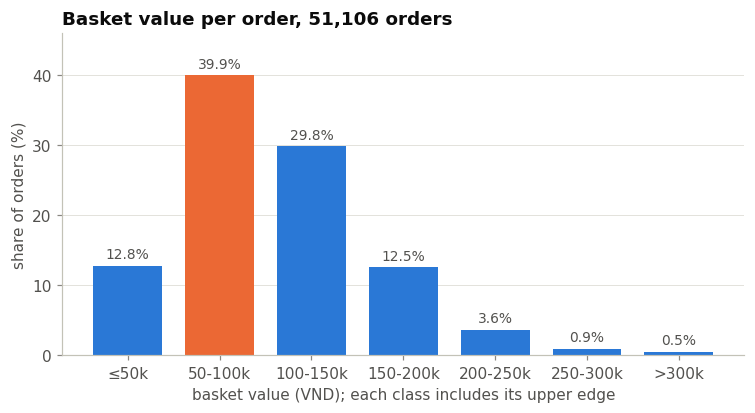

share of orders ≤50k (%)                        12.8   slide           12.8   ✓
share of orders 50-100k (%)                     39.9   slide           39.9   ✓
share of orders 100-150k (%)                    29.8   slide           29.8   ✓
share of orders 150-200k (%)                    12.5   slide           12.5   ✓
share of orders 200-250k (%)                     3.6   slide            3.6   ✓
share of orders 250-300k (%)                     0.9   slide            0.9   ✓
share of orders >300k (%)                        0.5   slide            0.5   ✓

orders of exactly 100,000 VND: 2.2%
share of 50-100k if each class includes its lower edge instead: 37.7%


In [28]:
edges  = [0, 50_000, 100_000, 150_000, 200_000, 250_000, 300_000, np.inf]
labels = ['≤50k', '50-100k', '100-150k', '150-200k', '200-250k', '250-300k', '>300k']
share = pd.cut(basket, edges, labels=labels, right=True).value_counts(sort=False, normalize=True) * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(labels, share.to_numpy(), width=0.75,
              color=[ORANGE if v == share.max() else BLUE for v in share])
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in share], padding=3, color=INK2, fontsize=9)
ax.set_ylim(0, share.max() * 1.15)
ax.set(title=f'Basket value per order, {len(basket):,} orders', ylabel='share of orders (%)',
       xlabel='basket value (VND); each class includes its upper edge')
plt.show()

for lab, on_slide in zip(labels, [12.8, 39.9, 29.8, 12.5, 3.6, 0.9, 0.5]):
    check(f'share of orders {lab} (%)', share[lab], on_slide, decimals=1)
print(f"\norders of exactly 100,000 VND: {(basket == 100_000).mean():.1%}")
share_left = pd.cut(basket, edges, labels=labels, right=False).value_counts(sort=False, normalize=True) * 100
print(f"share of 50-100k if each class includes its lower edge instead: {share_left['50-100k']:.1f}%")

**How to read it.** The peak is the class from 50,000 to 100,000 dong, with 39.9% of all orders. The right tail thins out and never quite stops.

**A detail that changes the picture.** 2.2% of all orders are worth exactly 100,000 dong, for example an iced milk coffee (45,000) with a cheesecake (55,000). The slide puts each edge in the class *below* it (`right=True`). Put the edges in the class above and the peak falls from 39.9% to 37.7%. Class edges are a choice, just like class widths.

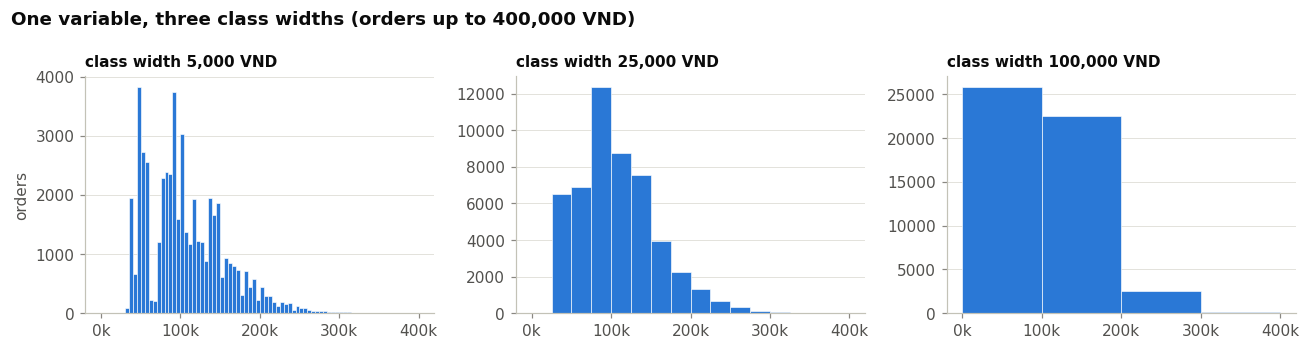

orders above 400,000 VND left out of these panels: 88


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, width in zip(axes, [5_000, 25_000, 100_000]):
    ax.hist(basket[basket <= 400_000], bins=np.arange(0, 400_001, width), color=BLUE, edgecolor='white', linewidth=0.4)
    ax.set_title(f'class width {width:,} VND', fontsize=10)
    ax.xaxis.set_major_formatter(thousands)
axes[0].set_ylabel('orders')
fig.suptitle('One variable, three class widths (orders up to 400,000 VND)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()
print(f'orders above 400,000 VND left out of these panels: {(basket > 400_000).sum()}')

**Bin width is a choice** (slide 39). With 5,000-dong classes the histogram shows tall spikes at the prices on the menu, because a coffee shop sells fixed combinations. With 100,000-dong classes the shape collapses into a block and the peak disappears. Neither picture is false. Report the width you used, and show a second width when your conclusion depends on it.

## 3.3.2 Boxplots: one distribution, then twelve stores side by side
*Slides 23, 24 and 40.* The box runs from $Q_1$ to $Q_3$, the line inside is the median, the whiskers stop at the last value inside the fences, and every value beyond a fence is drawn as a dot.

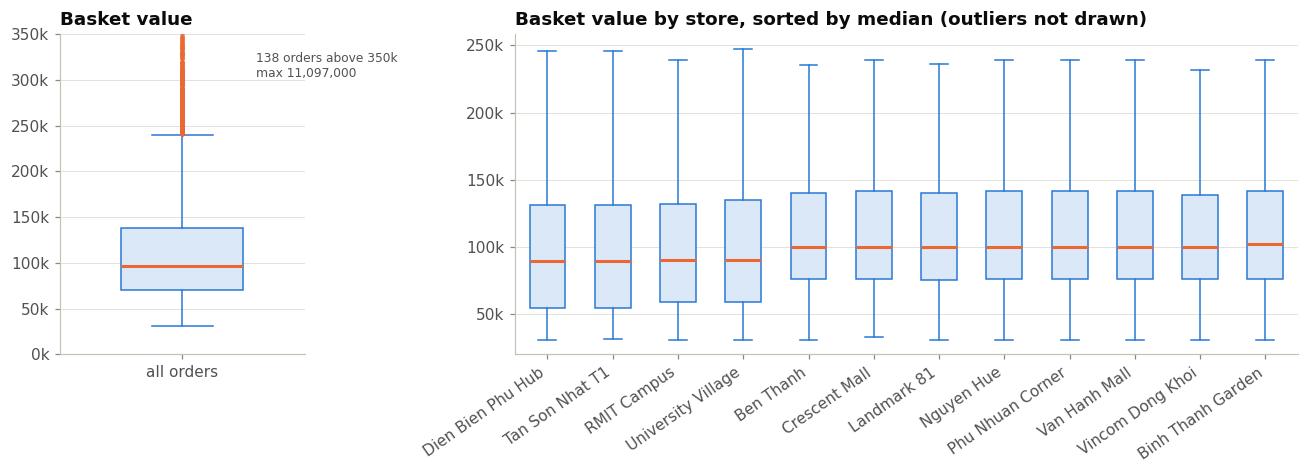

,count,25%,50%,75%
store_name,,,,
Dien Bien Phu Hub,"3,335","55,000","90,000","131,500"
Tan Son Nhat T1,"5,635","55,000","90,000","131,500"
RMIT Campus,"1,853","59,000","90,500","131,950"
University Village,"2,481","59,000","90,500","135,000"
Ben Thanh,"6,492","76,500","100,000","140,150"
Crescent Mall,"4,327","76,500","100,000","141,500"
Landmark 81,"5,880","75,575","100,000","140,000"
Nguyen Hue,"6,889","76,500","100,000","141,500"
Phu Nhuan Corner,"2,894","76,500","100,000","141,500"


In [30]:
box_style = dict(patch_artist=True, whis=1.5,
                 boxprops=dict(facecolor='#dbe8f8', edgecolor=BLUE), medianprops=dict(color=ORANGE, linewidth=2),
                 whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
                 flierprops=dict(marker='o', markersize=3, markerfacecolor=ORANGE, markeredgecolor='none', alpha=0.5))

order_store = stage_a.groupby('order_id')['store_name'].first()
by_store = basket.groupby(order_store)
store_order = by_store.median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={'width_ratios': [1, 3.2]})
axes[0].boxplot([basket.to_numpy()], widths=0.5, **box_style)
axes[0].set_ylim(0, 350_000)
axes[0].set_xticks([1])
axes[0].set_xticklabels(['all orders'])
axes[0].set_title('Basket value')
axes[0].text(1.3, 330_000, f'{(basket > 350_000).sum()} orders above 350k\nmax {vnd(basket.max())}',
             fontsize=8, color=INK2, va='top')

axes[1].boxplot([by_store.get_group(s).to_numpy() for s in store_order], widths=0.55, showfliers=False, **box_style)
axes[1].set_xticks(range(1, len(store_order) + 1))
axes[1].set_xticklabels(store_order, rotation=35, ha='right')
axes[1].set_title('Basket value by store, sorted by median (outliers not drawn)')
for ax in axes:
    ax.yaxis.set_major_formatter(thousands)
plt.tight_layout()
plt.show()

display(by_store.describe()[['count', '25%', '50%', '75%']].loc[store_order])

**How to read it.** On the left, the box covers the middle half of all orders (70,500 to 138,500 dong) and the upper whisker ends at the last order below the fence of 240,500. The dots above are the 893 flagged orders. The twelve typed prices are far off the top of the chart: the largest basket is 11,097,000 dong.

On the right, twelve stores fit on one screen, which no set of twelve histograms could do, and two groups appear at once. The two transit and the two campus stores have a median of about 90,000 dong and a lower quartile of 55,000 to 59,000. The malls and the residential stores sit at a median of about 100,000 and a lower quartile of about 76,500. The upper quartiles are close (131,500 to 141,500), so the difference lies in the bottom half: transit and campus customers place many single-drink orders.

*Use the boxplot to compare twelve stores at once. Use the histogram to understand one of them properly* (slide 40).

## 3.3.3 Same five numbers, different shapes
*Slides 30 and 40.* The two samples below are built so that their five-number summaries are **identical**: minimum 0, $Q_1$ = 40, median 50, $Q_3$ = 60, maximum 100. The whiskers are drawn to the minimum and the maximum, as on slide 23.

one peak  [  0.  40.  50.  60. 100.]
two peaks [  0.  40.  50.  60. 100.]


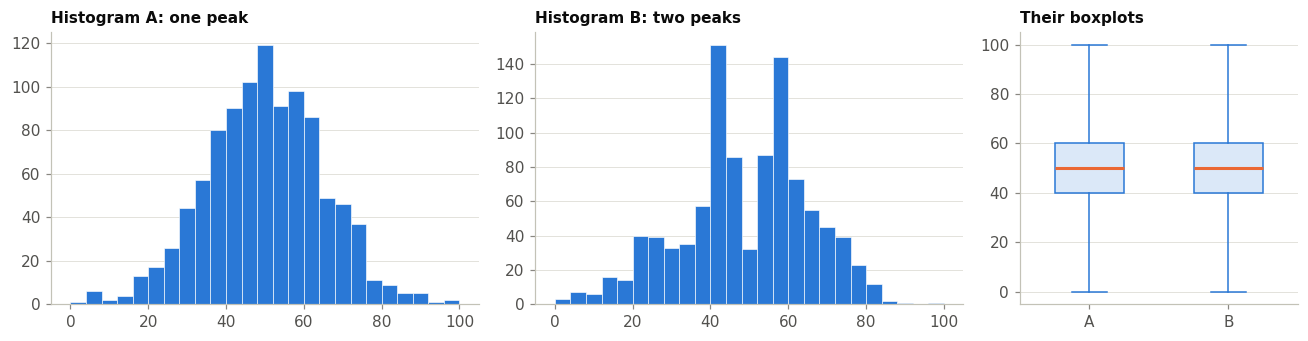

In [31]:
rng = np.random.default_rng(3)

def force_five(x, target=(0, 40, 50, 60, 100)):
    '''Stretch x piece by piece so that its min, Q1, median, Q3 and max equal `target` exactly.'''
    return np.interp(x, np.quantile(x, [0, 0.25, 0.5, 0.75, 1]), target)

one_peak  = force_five(rng.normal(50, 14.8, 1001))
two_peaks = force_five(np.concatenate([rng.normal(38, 6, 500), rng.normal(62, 6, 501)]))
for name, sample in [('one peak ', one_peak), ('two peaks', two_peaks)]:
    print(name, np.round(np.quantile(sample, [0, 0.25, 0.5, 0.75, 1]), 2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={'width_ratios': [2, 2, 1.3]})
for ax, sample, title in [(axes[0], one_peak, 'Histogram A: one peak'), (axes[1], two_peaks, 'Histogram B: two peaks')]:
    ax.hist(sample, bins=np.arange(0, 101, 4), color=BLUE, edgecolor='white', linewidth=0.4)
    ax.set_title(title, fontsize=10)
axes[2].boxplot([one_peak, two_peaks], widths=0.5, **{**box_style, 'whis': (0, 100)})
axes[2].set_xticks([1, 2])
axes[2].set_xticklabels(['A', 'B'])
axes[2].set_title('Their boxplots', fontsize=10)
plt.tight_layout()
plt.show()

The two boxplots are indistinguishable. The histograms are not: sample B has two separate peaks, which usually means two different processes, such as two kinds of customer. A median and two quartiles cannot express a second peak. If a bimodal shape would change your decision, the boxplot alone cannot be trusted.

## 3.3.4 Quantile plot and quantile-quantile plots
*Slides 31, 32 and 41.*
* A **quantile plot** sorts the values and plots each value $x_i$ against $f_i = (i - 0.5)/n$, the share of the data at or below it.
* A **Q-Q plot** puts the quantiles of one distribution against those of another. Points on the 45-degree line mean the two distributions agree. Against a normal distribution, it becomes the normality check.

,p5,p10,p25,p50,p75,p90,p95,p99,max
"basket, VND","42,000","45,000","70,500","97,000","138,500","174,000","200,000","263,000","11,097,000"


p5                                            42,000   slide         42,000   ✓
p10                                           45,000   slide         45,000   ✓
p25                                           70,500   slide         70,500   ✓
p50                                           97,000   slide         97,000   ✓
p75                                          138,500   slide        138,500   ✓
p90                                          174,000   slide        174,000   ✓
p95                                          200,000   slide        200,000   ✓
p99                                          263,000   slide        263,000   ✓
max                                       11,097,000   slide     11,097,000   ✓


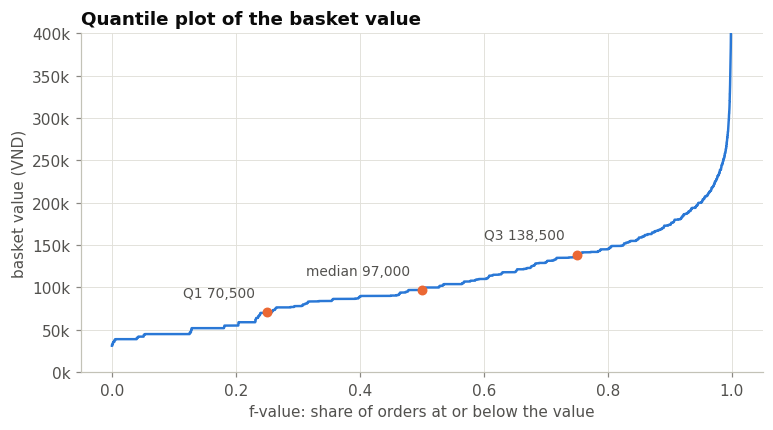

In [32]:
pcts = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
table_41 = basket.quantile(pcts)
table_41.index = [f'p{round(p * 100)}' for p in pcts]
table_41['max'] = basket.max()
display(table_41.to_frame('basket, VND').T)
for lab, on_slide in zip(table_41.index, [42_000, 45_000, 70_500, 97_000, 138_500, 174_000, 200_000, 263_000, 11_097_000]):
    check(f'{lab}', table_41[lab], on_slide)

xs = np.sort(basket.to_numpy())
f = (np.arange(1, len(xs) + 1) - 0.5) / len(xs)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(f, xs, color=BLUE, linewidth=1.6)
for p, name in [(0.25, 'Q1'), (0.50, 'median'), (0.75, 'Q3')]:
    v = np.quantile(xs, p)
    ax.scatter([p], [v], color=ORANGE, s=30, zorder=3)
    ax.annotate(f'{name} {vnd(v)}', (p, v), textcoords='offset points', xytext=(-8, 10), ha='right', fontsize=9, color=INK2)
ax.set_ylim(0, 400_000)
ax.yaxis.set_major_formatter(thousands)
ax.grid(True, axis='both')
ax.set(title='Quantile plot of the basket value', xlabel='f-value: share of orders at or below the value',
       ylabel='basket value (VND)')
plt.show()

**Read the tail, not the middle** (slide 41). From p5 to p95 the basket grows from 42,000 to 200,000 dong, a factor of about five, and the curve climbs steadily. From p99 to the maximum it grows from 263,000 to 11,097,000 dong, a factor of 42. The curve is cut at 400,000 dong because the last few values would flatten everything else into the floor. A steep part of a quantile plot means the values are sparse there: the whole problem of this variable lives in its last one percent.

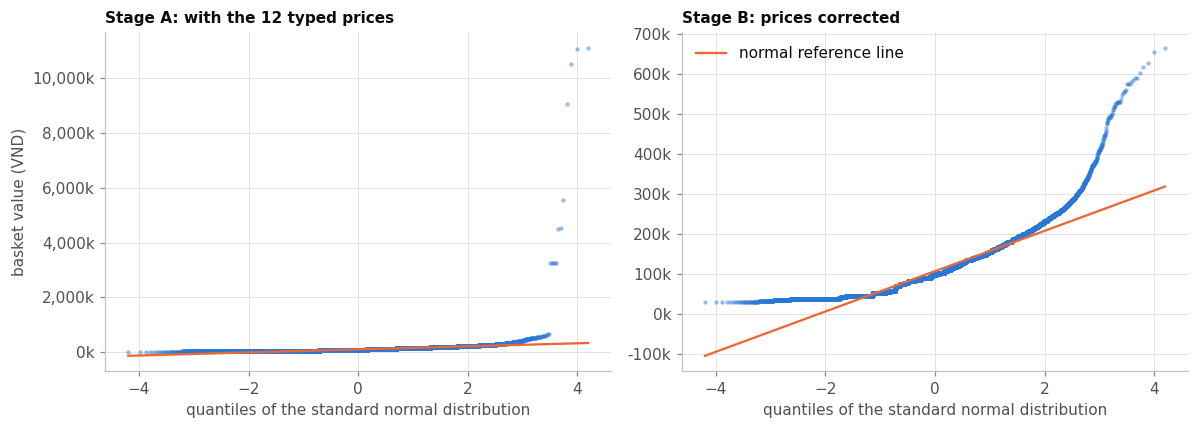

skewness, Stage A: 62.1 | Stage B: 1.45


In [33]:
basket_b = stage_b.groupby('order_id')['line_total'].sum()      # Stage B: the twelve prices corrected

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, b) in zip(axes, [('Stage A: with the 12 typed prices', basket), ('Stage B: prices corrected', basket_b)]):
    (theory, ordered), (slope, intercept, _) = stats.probplot(b, dist='norm')
    ax.scatter(theory, ordered, s=4, color=BLUE, alpha=0.35)
    ax.plot(theory, slope * theory + intercept, color=ORANGE, linewidth=1.5, label='normal reference line')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('quantiles of the standard normal distribution')
    ax.yaxis.set_major_formatter(thousands)
    ax.grid(True, axis='both')
axes[0].set_ylabel('basket value (VND)')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()
print('skewness, Stage A:', round(stats.skew(basket), 1), '| Stage B:', round(stats.skew(basket_b), 2))

**Is the basket normal?** If it were, the blue points would lie on the orange line. In Stage A the twelve typed prices form a vertical spike at the right, millions of dong above everything else. After the correction (Stage B) the spike is gone, yet the points still bend upward at the right end and sit above the line: the right tail is longer than a normal tail. On the left the points flatten into a floor near 30,000 dong, because no order can cost less than one cheap item, while a normal curve would continue into negative values. The small flat steps come from baskets being sums of a few fixed menu prices. The skewness falls from 62 to 1.45, still clearly positive. The basket is right-skewed in both versions, so methods that assume normality need care.

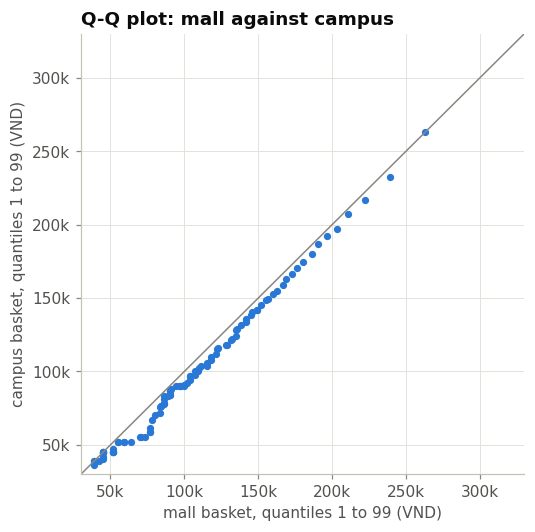

median mall  : 100,000
median campus: 90,500


In [34]:
order_type = stage_a.groupby('order_id')['store_type'].first()
p = np.linspace(0.01, 0.99, 99)
q_mall, q_campus = np.quantile(basket[order_type == 'mall'], p), np.quantile(basket[order_type == 'campus'], p)

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(q_mall, q_campus, s=14, color=BLUE)
lim = [30_000, 330_000]
ax.plot(lim, lim, color=MUTED, linewidth=1)
ax.set(xlim=lim, ylim=lim, title='Q-Q plot: mall against campus', xlabel='mall basket, quantiles 1 to 99 (VND)',
       ylabel='campus basket, quantiles 1 to 99 (VND)')
ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(thousands)
ax.grid(True, axis='both')
plt.show()
print('median mall  :', vnd(np.median(basket[order_type == 'mall'])))
print('median campus:', vnd(np.median(basket[order_type == 'campus'])))

This is the Saigon Bean version of the Branch 1 against Branch 2 example on slide 32. Almost every point sits a little below the 45-degree line: at the same percentile, a campus basket is smaller than a mall basket. The gap is widest in the lower half (the 25th percentile is 59,000 dong on campus against 76,500 in the malls, the medians 90,500 against 100,000) and almost closes in the upper tail, where large orders look alike in both store types. The shift is a whole-distribution shift, which a comparison of two means could not show.

## 3.3.5 Scatter plot: seats against revenue
*Slide 42.* One point per store. We first build a small store table that we will reuse in 3.4.

,revenue,orders,store_type,district,seats,seats_band,avg_basket,app_share
store_name,,,,,,,,
Nguyen Hue,766967425,6889,mall,District 1,70,large,"111,332",22.3
Ben Thanh,726237200,6492,mall,District 1,62,large,"111,866",22.5
Landmark 81,641920575,5880,mall,Binh Thanh,58,large,"109,170",22.1
Vincom Dong Khoi,522539500,4818,mall,District 1,54,large,"108,456",21.5
Crescent Mall,488699050,4327,mall,District 7,48,medium,"112,942",22
Van Hanh Mall,442791300,3845,mall,District 10,44,medium,"115,160",22
University Village,254847275,2481,campus,Thu Duc,40,medium,"102,720",53.4
RMIT Campus,194164775,1853,campus,District 7,36,medium,"104,784",53.9
Phu Nhuan Corner,324181875,2894,residential,Phu Nhuan,32,medium,"112,019",34.6


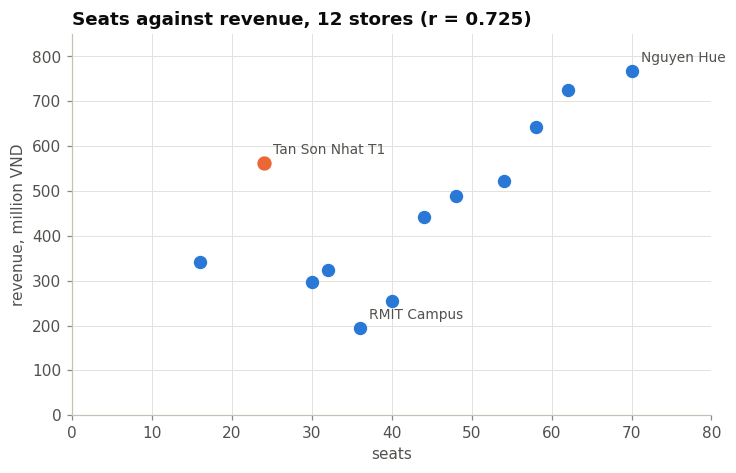

correlation of seats with revenue              0.725   slide          0.725   ✓
Tan Son Nhat T1 revenue, million VND             563   slide            563   ✓


In [35]:
orders_a = stage_a.drop_duplicates('order_id')          # one row per order, with its store, channel and time

store_stats = (stage_a.groupby('store_name')
               .agg(revenue=('line_total', 'sum'), orders=('order_id', 'nunique'))
               .join(stores.set_index('store_name')[['store_type', 'district', 'seats', 'seats_band']])
               .reindex(stores['store_name']))
store_stats['avg_basket'] = store_stats['revenue'] / store_stats['orders']
store_stats['app_share'] = orders_a['channel'].eq('app').groupby(orders_a['store_name']).mean() * 100
display(store_stats.round({'avg_basket': 0, 'app_share': 1}))

r = store_stats['seats'].corr(store_stats['revenue'])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
highlight = store_stats.index == 'Tan Son Nhat T1'
ax.scatter(store_stats.loc[~highlight, 'seats'], store_stats.loc[~highlight, 'revenue'] / 1e6, s=60, color=BLUE)
ax.scatter(store_stats.loc[highlight, 'seats'], store_stats.loc[highlight, 'revenue'] / 1e6, s=70, color=ORANGE)
for name in ['Nguyen Hue', 'Tan Son Nhat T1', 'RMIT Campus']:
    ax.annotate(name, (store_stats.loc[name, 'seats'], store_stats.loc[name, 'revenue'] / 1e6),
                textcoords='offset points', xytext=(6, 6), fontsize=9, color=INK2)
ax.set(xlim=(0, 80), ylim=(0, 850), xlabel='seats', ylabel='revenue, million VND',
       title=f'Seats against revenue, 12 stores (r = {r:.3f})')
ax.grid(True, axis='both')
plt.show()

check('correlation of seats with revenue', r, 0.725, decimals=3)
check('Tan Son Nhat T1 revenue, million VND', store_stats.loc['Tan Son Nhat T1', 'revenue'] / 1e6, 563)

**What the scatter shows.** The correlation of seats with revenue is 0.725: larger stores do earn more, and the relationship is far from tight.

**The point that breaks the line.** Tan Son Nhat T1 has the second-fewest seats (24) and earns 563 million dong, more than every store with 54 seats or fewer, including Vincom Dong Khoi (54 seats) and Crescent Mall (48), which have twice its seating or more. It is an airport unit where nobody sits down. A correlation coefficient would have hidden this. The scatter plot shows it in one second.

## 3.3.6 Beyond two attributes
*Slide 43.* Two of the four families on the slide take one line of code each in pandas or matplotlib: **geometric projection** (a scatter-plot matrix and parallel coordinates) and **pixel-oriented** views.

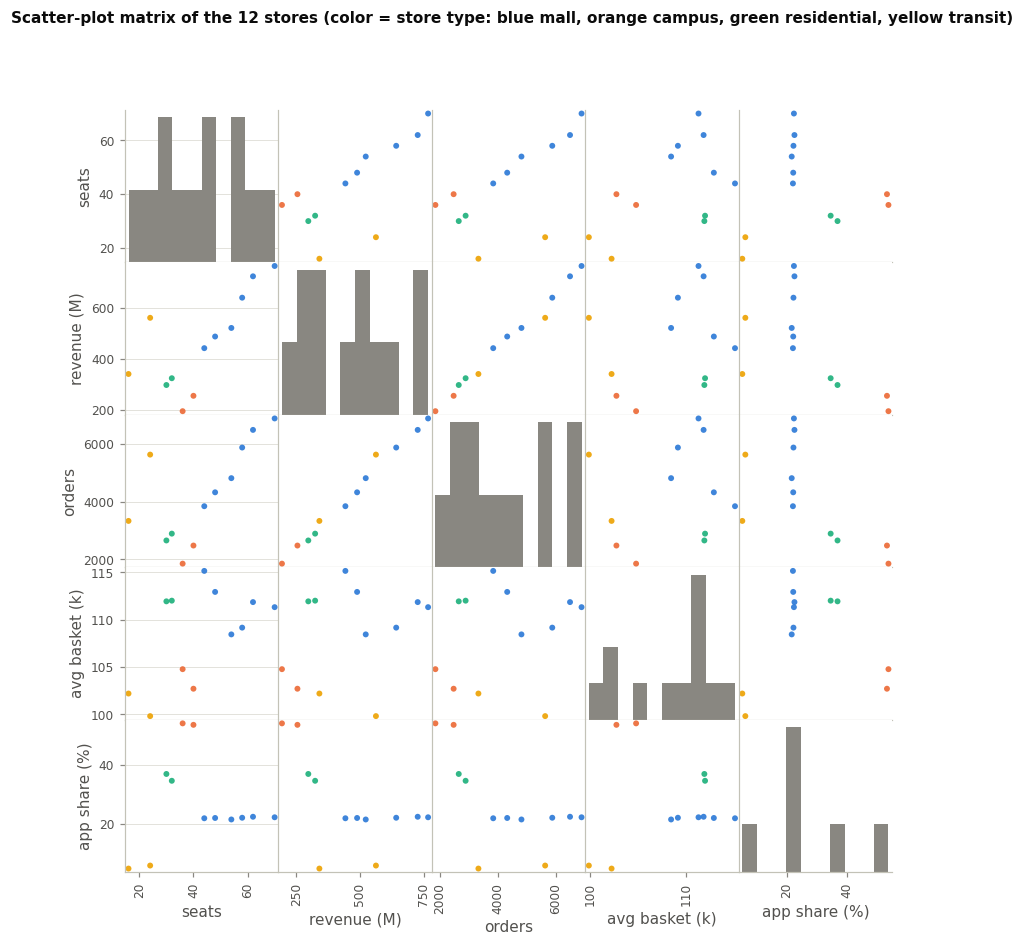

In [36]:
TYPE_COLOR = {'mall': BLUE, 'campus': ORANGE, 'residential': AQUA, 'transit': YELLOW}

# 1. Geometric projection: a scatter-plot matrix, every pair of five store attributes
matrix = pd.DataFrame({'seats': store_stats['seats'], 'revenue (M)': store_stats['revenue'] / 1e6,
                       'orders': store_stats['orders'], 'avg basket (k)': store_stats['avg_basket'] / 1000,
                       'app share (%)': store_stats['app_share']})
axes = pd.plotting.scatter_matrix(matrix, figsize=(9, 9), diagonal='hist', s=60, alpha=0.9,
                                  c=store_stats['store_type'].map(TYPE_COLOR).tolist(), hist_kwds={'color': MUTED})
plt.suptitle('Scatter-plot matrix of the 12 stores (color = store type: blue mall, orange campus, '
             'green residential, yellow transit)', x=0.01, ha='left', fontsize=10, fontweight='bold')
plt.show()

A scatter-plot matrix shows every pair of attributes at once. The off-diagonal panel of seats against orders repeats the story of 3.3.5. The panel of app share against anything else splits the stores into clusters by color: campus stores (orange) sit near 54% app share, transit stores (yellow) near 5%. One chart shows that the channel mix goes with the store type and not with the size of the store.

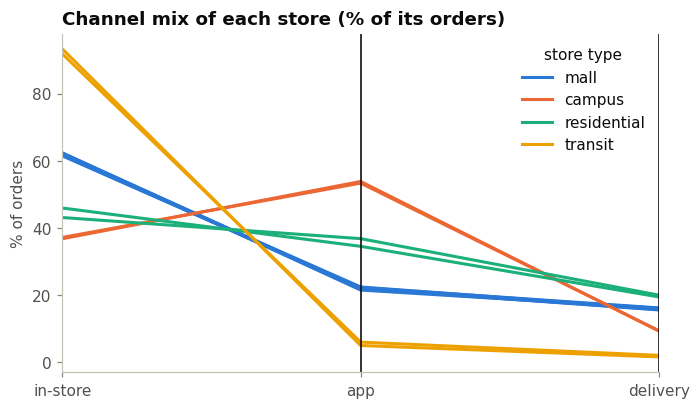

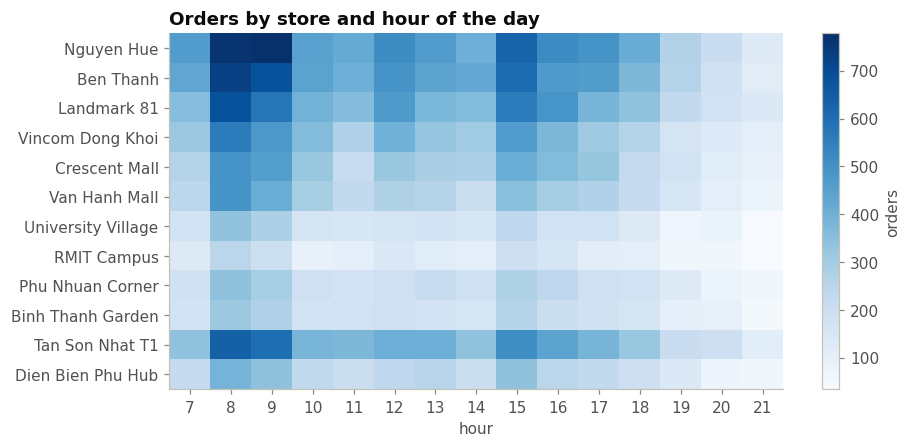

In [37]:
# 2. Geometric projection again: parallel coordinates of the channel mix
channel_mix = (pd.crosstab(orders_a['store_name'], orders_a['channel'], normalize='index')
               .mul(100)[['in-store', 'app', 'delivery']].reindex(stores['store_name']))
fig, ax = plt.subplots(figsize=(7, 4))
pd.plotting.parallel_coordinates(channel_mix.join(stores.set_index('store_name')['store_type']),
                                 'store_type', color=[BLUE, ORANGE, AQUA, YELLOW], ax=ax, linewidth=2)
ax.set(title='Channel mix of each store (% of its orders)', ylabel='% of orders')
ax.legend(title='store type', loc='upper right')
plt.show()

# 3. Pixel-oriented: one colored cell per (store, hour) value
hour_store = pd.crosstab(orders_a['store_name'], orders_a['order_time'].dt.hour).reindex(stores['store_name'])
fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(hour_store.to_numpy(), aspect='auto', cmap='Blues')
ax.set_xticks(range(hour_store.shape[1]))
ax.set_xticklabels(hour_store.columns)
ax.set_yticks(range(len(hour_store)))
ax.set_yticklabels(hour_store.index)
ax.grid(False)
ax.set(title='Orders by store and hour of the day', xlabel='hour')
fig.colorbar(im, ax=ax, label='orders')
plt.show()

In the parallel-coordinates chart each store is one line across three axes. The lines bundle into four groups, one per store type, which is exactly the segmentation that 3.4 will measure with distances.

In the pixel-oriented chart each cell is one number and color carries the magnitude, so a table of 180 values reads at a glance. Every store has its darkest cells at 8 and 9 in the morning and a second, softer peak around 15:00. The large malls and Tan Son Nhat T1 are the darkest rows because they simply have more orders.

The other two families, **icon-based** displays such as Chernoff faces and **hierarchical** displays such as tree-maps, have no standard function in pandas and are rarely used in business reports.

## Practice 3
*Slide 44.*

**P3.1** Using the nine values of the percentile table in 3.3.4, sketch the quantile plot of the basket value by hand. Mark the median and the interquartile range, then say in one sentence what the shape of the curve tells you. (A code version of your sketch is enough.)

**P3.2** A regional manager sees the scatter plot and concludes that adding seats raises revenue. Give two reasons from this section why that conclusion does not follow, and name one additional attribute you would plot before answering.

**P3.3** Choose the better chart for each question and justify it in one line. (a) Do the twelve stores differ in basket value? (b) Does the basket value have one peak or two? (c) Is the basket value normally distributed? (d) Which hour of the day is busiest? Then draw the chart for (d).

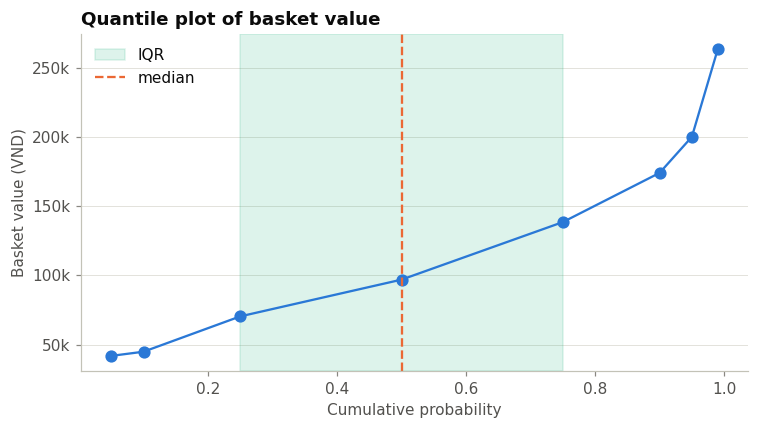

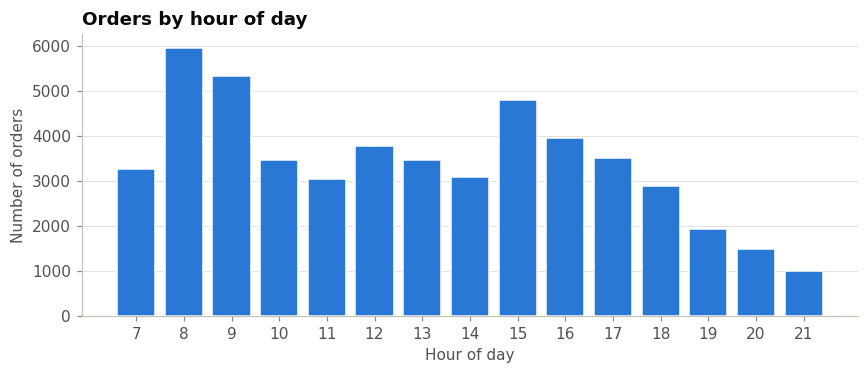

Busiest hour: 8 with 5969 orders


In [38]:
# P3.1 the eight percentiles of the table (the ninth value, the maximum, is far off any sensible chart)
p_vals = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
v_vals = [42_000, 45_000, 70_500, 97_000, 138_500, 174_000, 200_000, 263_000]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(p_vals, v_vals, 'o-', color=BLUE, markersize=7)
ax.axvspan(0.25, 0.75, alpha=0.15, color=AQUA, label='IQR')
ax.axvline(0.50, color=ORANGE, linestyle='--', label='median')
ax.set(xlabel='Cumulative probability', ylabel='Basket value (VND)',
       title='Quantile plot of basket value')
ax.yaxis.set_major_formatter(thousands)
ax.legend()
plt.tight_layout()
plt.show()

# P3.3 (d) count orders by hour
hour_counts = orders_a['order_time'].dt.hour.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(hour_counts.index, hour_counts.values, color=BLUE, edgecolor='white')
ax.set(xlabel='Hour of day', ylabel='Number of orders',
       title='Orders by hour of day', xticks=range(7, 22))
plt.tight_layout()
plt.show()
print('Busiest hour:', hour_counts.idxmax(), 'with', hour_counts.max(), 'orders')


### Answers – Practice 3

**P3.1**  
The quantile curve rises slowly at first and then steepens after the median → the distribution of basket value is **right-skewed** (many modest orders, a long tail of large orders).

**P3.2**  
1. Correlation does not imply causation; seats and revenue may both be driven by location or store type.  
2. The scatter contains influential points (e.g. the airport store) that can dominate a linear view.  
Additional attribute to plot: **store_type** (or district).

**P3.3**  
(a) Do the twelve stores differ in basket value? → **boxplot** (compare groups).  
(b) Does the basket value have one peak or two? → **histogram** (shape).  
(c) Is the basket value normally distributed? → **Q-Q plot**.  
(d) Which hour of the day is busiest? → **bar chart of counts by hour** (drawn above).


---
# 3.4 Measuring data similarities and differences
*Deck 1, slides 45 to 56. Lab task 5.*

* **Similarity**: how alike two objects are. Higher means more alike, often scaled to [0, 1].
* **Dissimilarity** (distance): how different they are. Zero when the objects coincide.
* **Proximity**: the umbrella word for both. Clustering (Chapter 5), nearest-neighbor classification (Chapter 4) and outlier detection all start from a proximity matrix.

The measure depends on the attribute type, so this section walks through one measure per type, always on Saigon Bean stores or customers.

## 3.4.1 Data matrix and dissimilarity matrix
*Slide 47.* Each store is described by its **channel mix**: the share of its orders placed in-store, through the app and by delivery. The slides print the shares with one decimal, and we round the same way so that every distance matches the slides.

In [39]:
channel_share = channel_mix.round(1)          # 12 stores x 3 attributes: the data matrix (two modes)
display(channel_share)

def minkowski(a, b, h):
    '''Minkowski distance of order h. h=1 Manhattan, h=2 Euclidean, h=np.inf supremum.'''
    gap = np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))
    return gap.max() if h == np.inf else (gap ** h).sum() ** (1 / h)

def cosine(a, b):
    '''Cosine of the angle between two vectors: 1 means the same direction.'''
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

four = channel_share.loc[['Nguyen Hue', 'University Village', 'Tan Son Nhat T1', 'Phu Nhuan Corner']]
D4 = pd.DataFrame(squareform(pdist(four, metric='euclidean')), index=four.index, columns=four.index)
lower = np.tril(np.ones(D4.shape, dtype=bool))
display(D4.round(2).where(lower, ''))      # one mode: rows and columns are the same objects

check('Nguyen Hue vs University Village', D4.iloc[1, 0], 40.05, decimals=2)
check('Nguyen Hue vs Tan Son Nhat T1', D4.iloc[2, 0], 37.14, decimals=2)
check('University Village vs Tan Son Nhat T1', D4.iloc[2, 1], 72.61, decimals=2)
check('Phu Nhuan Corner vs Nguyen Hue', D4.iloc[3, 0], 20.06, decimals=2)

channel,in-store,app,delivery
store_name,,,
Nguyen Hue,61.5,22.3,16.2
Ben Thanh,61.6,22.5,15.9
Landmark 81,62.2,22.1,15.7
Vincom Dong Khoi,62.4,21.5,16.1
Crescent Mall,62.3,22,15.6
Van Hanh Mall,62,22,16.1
University Village,37.2,53.4,9.4
RMIT Campus,36.8,53.9,9.3
Phu Nhuan Corner,46,34.6,19.5


store_name,Nguyen Hue,University Village,Tan Son Nhat T1,Phu Nhuan Corner
store_name,,,,
Nguyen Hue,0,,,
University Village,40.05,0,,
Tan Son Nhat T1,37.14,72.61,0,
Phu Nhuan Corner,20.06,23.08,56.68,0


Nguyen Hue vs University Village               40.05   slide          40.05   ✓
Nguyen Hue vs Tan Son Nhat T1                  37.14   slide          37.14   ✓
University Village vs Tan Son Nhat T1           72.61   slide          72.61   ✓
Phu Nhuan Corner vs Nguyen Hue                 20.06   slide          20.06   ✓


**Two matrices, two shapes.** The data matrix has 12 rows (objects) and 3 columns (attributes): rows and columns mean different things. The dissimilarity matrix is 4 by 4 here: rows and columns are the same stores. It is symmetric with zeros on the diagonal, so only the lower triangle is printed.

Euclidean distance, for Nguyen Hue against University Village:
$$d = \sqrt{(61.5-37.2)^2 + (22.3-53.4)^2 + (16.2-9.4)^2} = \sqrt{590.49 + 967.21 + 46.24} = 40.05$$
The airport store (Tan Son Nhat T1) and the campus store (University Village) are the furthest apart, 72.61: one sells almost everything at the counter, the other through the app.

## 3.4.2 Nominal attributes: simple matching
*Slide 48.* $$d(i,j) = \frac{p - m}{p}$$ where $p$ is the number of attributes compared and $m$ the number on which $i$ and $j$ match.

In [40]:
store_info = stores.set_index('store_name')

def d_nominal(i, j, attrs=('district', 'store_type')):
    a, b = store_info.loc[i, list(attrs)], store_info.loc[j, list(attrs)]
    m, p = int((a == b).sum()), len(attrs)
    return m, p, (p - m) / p

rows = []
for i, j in [('Nguyen Hue', 'Ben Thanh'), ('Nguyen Hue', 'Landmark 81'),
             ('Nguyen Hue', 'University Village'), ('RMIT Campus', 'Crescent Mall')]:
    m, p, d = d_nominal(i, j)
    rows.append({'pair': f'{i} vs {j}',
                 'district': f"{store_info.loc[i, 'district']} / {store_info.loc[j, 'district']}",
                 'store_type': f"{store_info.loc[i, 'store_type']} / {store_info.loc[j, 'store_type']}",
                 'm / p': f'{m} / {p}', 'd(i, j)': d})
display(pd.DataFrame(rows).set_index('pair'))

,district,store_type,m / p,"d(i, j)"
pair,,,,
Nguyen Hue vs Ben Thanh,District 1 / District 1,mall / mall,2 / 2,0
Nguyen Hue vs Landmark 81,District 1 / Binh Thanh,mall / mall,1 / 2,0.5
Nguyen Hue vs University Village,District 1 / Thu Duc,mall / campus,0 / 2,1
RMIT Campus vs Crescent Mall,District 7 / District 7,campus / mall,1 / 2,0.5


Nguyen Hue and Ben Thanh match on both attributes (two District 1 malls), so $d = 0$. RMIT Campus and Crescent Mall share District 7 and differ in type, so $d = 1/2$. Simple matching treats every mismatch as equally large: a campus store differs from a mall exactly as much as from a transit hub.

## 3.4.3 Binary attributes: symmetric, asymmetric and Jaccard
*Slide 49.* Describe each customer by 17 binary attributes, one per product: 1 if the customer ever bought it. For two customers count

| | $j$ = 1 | $j$ = 0 |
|---|---|---|
| $i$ = 1 | $q$ | $r$ |
| $i$ = 0 | $s$ | $t$ |

* symmetric: $d = \dfrac{r+s}{q+r+s+t}$
* asymmetric: $d = \dfrac{r+s}{q+r+s}$, the shared zeros $t$ are dropped
* Jaccard similarity: $\text{sim} = \dfrac{q}{q+r+s} = 1 - d_{\text{asymmetric}}$

In [41]:
bought = stage_a[stage_a['is_member']].groupby('customer_id')['product_id'].apply(set)
bought.index = bought.index.astype(int)
A_items, B_items = bought[10001], bought[10002]
catalog = set(products['product_id'])

q = len(A_items & B_items)
r = len(A_items - B_items)
s = len(B_items - A_items)
t = len(catalog - A_items - B_items)
print('customer 10001:', sorted(A_items))
print('customer 10002:', sorted(B_items))
print(f'q = {q}, r = {r}, s = {s}, t = {t}')
print(f'symmetric dissimilarity  (r+s)/(q+r+s+t) = {(r + s) / (q + r + s + t):.3f}')
print(f'asymmetric dissimilarity (r+s)/(q+r+s)   = {(r + s) / (q + r + s):.3f}')
print(f'Jaccard similarity        q/(q+r+s)       = {q / (q + r + s):.3f}')
check('Jaccard similarity', q / (q + r + s), 0.667, decimals=3)

customer 10001: [101, 102, 104, 105, 106, 201, 203, 301, 302, 304]
customer 10002: [101, 102, 104, 105, 106, 107, 201, 301, 302, 303]
q = 8, r = 2, s = 2, t = 5
symmetric dissimilarity  (r+s)/(q+r+s+t) = 0.235
asymmetric dissimilarity (r+s)/(q+r+s)   = 0.333
Jaccard similarity        q/(q+r+s)       = 0.667
Jaccard similarity                             0.667   slide          0.667   ✓


The two customers share 8 products and have bought 12 distinct products between them, so the Jaccard similarity is 8/12 = 0.667. The five products that neither has ever bought (for example the ceramic tumbler) contribute nothing, which is right: two customers are not alike because both ignore the tumbler. The symmetric measure would count those five shared zeros as agreement. For purchase data, where a 1 is rare and informative, the asymmetric measure is the right one.

## 3.4.4 Standardize numeric data before you measure
*Slide 50.* Distance is dominated by whichever attribute has the largest numeric range. Seats run from 16 to 70, revenue from 194 million to 767 million dong.

* z-score: $z = (x - \mu)/\sigma$
* mean absolute deviation: $s_f = \frac{1}{n}\sum |x_i - m_f|$, then $z = (x - m_f)/s_f$, where $m_f$ is the mean
* min-max: $x' = (x - \min)/(\max - \min)$

In [42]:
X = store_stats[['seats', 'revenue']].astype(float)
i, j = 'Nguyen Hue', 'Tan Son Nhat T1'

def seats_share(T):
    gap = (T.loc[i] - T.loc[j]).abs()
    return 100 * gap['seats'] ** 2 / (gap ** 2).sum()

versions = {
    'raw values':              X,
    'z-score':                 (X - X.mean()) / X.std(ddof=0),
    'mean absolute deviation': (X - X.mean()) / (X - X.mean()).abs().mean(),
    'min-max':                 (X - X.min()) / (X.max() - X.min()),
}
rows = [{'scaling': name, 'Euclidean distance': minkowski(T.loc[i], T.loc[j], 2),
         'seats share of the squared distance (%)': seats_share(T)} for name, T in versions.items()]
display(pd.DataFrame(rows).set_index('scaling'))

,Euclidean distance,seats share of the squared distance (%)
scaling,,
raw values,"204,437,200",0
z-score,3.1715,87.0623
mean absolute deviation,3.7357,87.4617
min-max,0.9236,85.0671


On raw values the distance between Nguyen Hue and Tan Son Nhat T1 is about 204 million: it is simply their revenue gap, and the 46-seat difference contributes essentially 0% of it. After any of the three scalings the picture reverses. In standardized units the two stores are about three standard deviations apart in seats and only one apart in revenue, so seats now carry 85% to 87% of the squared distance. Without standardizing, revenue decides every distance and seats contribute nothing. With it, each attribute counts by how unusual the gap is.

The mean absolute deviation does not square the deviations, so a single extreme value moves it less than it moves the standard deviation. With twelve typed prices in the file, that robustness is not theoretical. Another clean option is to convert to **shares**: the channel mix used above already sums to 100 for every store, which removes the scale problem at the source.

## 3.4.5 Minkowski distance and cosine similarity
*Slides 51 and 53.*
$$d(i,j) = \Big(\sum_f |x_{if} - x_{jf}|^h\Big)^{1/h}, \qquad h=1 \text{ Manhattan},\ h=2 \text{ Euclidean},\ h\to\infty \text{ supremum}$$
$$\cos(d_1, d_2) = \frac{d_1 \cdot d_2}{\lVert d_1\rVert \, \lVert d_2\rVert}$$
A metric must satisfy non-negativity, identity ($d = 0$ only when $i = j$), symmetry and the triangle inequality. Cosine measures the angle between two vectors and ignores their length.

In [43]:
pairs_51 = [('Nguyen Hue', 'Ben Thanh'), ('University Village', 'RMIT Campus'),
            ('Tan Son Nhat T1', 'Dien Bien Phu Hub'), ('Nguyen Hue', 'Phu Nhuan Corner'),
            ('Nguyen Hue', 'University Village'), ('University Village', 'Tan Son Nhat T1')]
rows = []
for i, j in pairs_51:
    a, b = channel_share.loc[i], channel_share.loc[j]
    rows.append({'pair': f'{i} vs {j}', 'types': f"{store_info.loc[i, 'store_type']} vs {store_info.loc[j, 'store_type']}",
                 'Manhattan': minkowski(a, b, 1), 'Euclidean': minkowski(a, b, 2),
                 'Supremum': minkowski(a, b, np.inf), 'Cosine': cosine(a, b)})
table_51 = pd.DataFrame(rows).set_index('pair').round({'Manhattan': 1, 'Euclidean': 2, 'Supremum': 1, 'Cosine': 4})
display(table_51)
check('Nguyen Hue vs Phu Nhuan, Manhattan', table_51.iloc[3]['Manhattan'], 31.1, decimals=1)
check('Univ. Village vs Tan Son Nhat, cosine', table_51.iloc[5]['Cosine'], 0.6214, decimals=4)

,types,Manhattan,Euclidean,Supremum,Cosine
pair,,,,,
Nguyen Hue vs Ben Thanh,mall vs mall,0.6,0.37,0.3,1
University Village vs RMIT Campus,campus vs campus,1,0.65,0.5,1
Tan Son Nhat T1 vs Dien Bien Phu Hub,transit vs transit,3.1,1.93,1.5,0.9999
Nguyen Hue vs Phu Nhuan Corner,mall vs residential,31.1,20.06,15.5,0.9562
Nguyen Hue vs University Village,mall vs campus,62.2,40.05,31.1,0.8193
University Village vs Tan Son Nhat T1,campus vs transit,109.2,72.61,54.6,0.6214


Nguyen Hue vs Phu Nhuan, Manhattan              31.1   slide           31.1   ✓
Univ. Village vs Tan Son Nhat, cosine          0.6214   slide         0.6214   ✓


All four measures agree on the **ordering** of the six pairs and disagree on the **scale**. Stores of the same type sit a few points apart on Manhattan distance, and stores of different types sit more than 31 points apart. Manhattan is the easiest to explain to a manager: half of it is the share of orders that would have to switch channel to make the two mixes identical.

In [44]:
# Slide 53: when cosine and Euclidean disagree
big, small = np.array([200, 100]), np.array([20, 10])      # coffees and pastries sold
print(f'200/100 against 20/10: Euclidean {minkowski(big, small, 2):.1f}, cosine {cosine(big, small):.4f}')

for i, j in [('Nguyen Hue', 'Tan Son Nhat T1'), ('Nguyen Hue', 'University Village')]:
    a, b = channel_share.loc[i], channel_share.loc[j]
    print(f'{i} vs {j}: Euclidean {minkowski(a, b, 2):.2f}, cosine {cosine(a, b):.4f}')

200/100 against 20/10: Euclidean 201.2, cosine 1.0000
Nguyen Hue vs Tan Son Nhat T1: Euclidean 37.14, cosine 0.9377
Nguyen Hue vs University Village: Euclidean 40.05, cosine 0.8193


A store selling 200 coffees and 100 pastries and a store selling 20 and 10 are far apart in Euclidean terms and identical in direction (cosine exactly 1): one is ten times the other with the same product mix. For segmentation by behavior, use cosine. For capacity planning, use Euclidean distance.

On the real stores, Nguyen Hue is about equally far from Tan Son Nhat T1 (37.14) and from University Village (40.05), yet the cosines differ a lot (0.9377 against 0.8193). The two Euclidean distances arise in different ways. The airport store sells almost everything at the counter, which makes its share vector longer while pointing nearly the same way as Nguyen Hue's: both lean on the counter. University Village points in another direction, toward the app. Euclidean distance mixes length and direction, and cosine ignores length, so only cosine separates the two pairs clearly.

## 3.4.6 Ordinal attributes: rank, then map to [0, 1]
*Slide 52.* Three steps, always in this order: replace each value by its rank $r$ from 1 to $M$, map the rank to $z = (r-1)/(M-1)$, then treat $z$ as numeric.

In [45]:
M = len(stores['seats_band'].cat.categories)              # small, medium, large: M = 3
stores['band_rank'] = stores['seats_band'].cat.codes + 1    # step 1: rank r = 1, 2, 3
stores['band_z'] = (stores['band_rank'] - 1) / (M - 1)      # step 2: z = (r - 1) / (M - 1)
store_info = stores.set_index('store_name')
ordinal = store_info.loc[['Nguyen Hue', 'Van Hanh Mall', 'Tan Son Nhat T1'], ['seats', 'seats_band', 'band_rank', 'band_z']]
ordinal['d(z) to Nguyen Hue'] = (ordinal['band_z'] - store_info.loc['Nguyen Hue', 'band_z']).abs()
display(ordinal)

,seats,seats_band,band_rank,band_z,d(z) to Nguyen Hue
store_name,,,,,
Nguyen Hue,70,large,3,1,0
Van Hanh Mall,44,medium,2,0.5,0.5
Tan Son Nhat T1,24,small,1,0,1


Large maps to 1, medium to 0.5 and small to 0, so the distance from Nguyen Hue is 0.5 to Van Hanh Mall and 1 to Tan Son Nhat T1. The mapping assumes equal steps between the ranks. That is a modeling choice, and it is the standard repair that lets an ordinal attribute enter a distance.

## 3.4.7 Attributes of mixed type
*Slide 54.*
$$d(i,j) = \frac{\sum_f \delta_{ij}^{(f)}\, d_{ij}^{(f)}}{\sum_f \delta_{ij}^{(f)}}$$
Each attribute keeps its own $d^{(f)}$ in [0, 1]. The indicator $\delta^{(f)}$ is 0 when a value is missing, or when the attribute is asymmetric binary and both objects have 0. Otherwise it is 1.

In [46]:
i, j = 'Nguyen Hue', 'Phu Nhuan Corner'
app = channel_share['app']
sells_merch = stage_a['category'].eq('merchandise').groupby(stage_a['store_name']).any()

parts = pd.DataFrame([
    {'attribute': 'store_type', 'type': 'nominal', i: store_info.loc[i, 'store_type'], j: store_info.loc[j, 'store_type'],
     'delta': 1, 'd': float(store_info.loc[i, 'store_type'] != store_info.loc[j, 'store_type'])},
    {'attribute': 'seats_band', 'type': 'ordinal', i: f"{store_info.loc[i, 'seats_band']} (z = {store_info.loc[i, 'band_z']})",
     j: f"{store_info.loc[j, 'seats_band']} (z = {store_info.loc[j, 'band_z']})",
     'delta': 1, 'd': abs(store_info.loc[i, 'band_z'] - store_info.loc[j, 'band_z'])},
    {'attribute': 'app share', 'type': 'numeric, divided by its range', i: f'{app[i]}%', j: f'{app[j]}%',
     'delta': 1, 'd': abs(app[i] - app[j]) / (app.max() - app.min())},
    {'attribute': 'sells merchandise', 'type': 'asymmetric binary', i: 'yes' if sells_merch[i] else 'no',
     j: 'yes' if sells_merch[j] else 'no', 'delta': int(sells_merch[i] or sells_merch[j]),
     'd': float(sells_merch[i] != sells_merch[j])},
]).set_index('attribute')
display(parts.round({'d': 2}))
d_mixed = (parts['delta'] * parts['d']).sum() / parts['delta'].sum()
print(f'app share range: {app.min()} to {app.max()}, so d = |{app[i]} - {app[j]}| / {app.max() - app.min():.1f} = {parts.loc["app share", "d"]:.2f}')
print(f'd({i}, {j}) = {d_mixed:.3f}')

,type,Nguyen Hue,Phu Nhuan Corner,delta,d
attribute,,,,,
store_type,nominal,mall,residential,1,1
seats_band,ordinal,large (z = 1.0),medium (z = 0.5),1,0.5
app share,"numeric, divided by its range",22.3%,34.6%,1,0.25
sells merchandise,asymmetric binary,yes,yes,1,0


app share range: 5.0 to 53.9, so d = |22.3 - 34.6| / 48.9 = 0.25
d(Nguyen Hue, Phu Nhuan Corner) = 0.438


* The store types differ, so $d = 1$.
* Phu Nhuan Corner has 32 seats, which falls in the medium band (31 to 50). Large against medium gives $d = |1 - 0.5| = 0.5$.
* The app shares differ by 12.3 points out of a range of 48.9 points across the chain (5.0% at Dien Bien Phu Hub to 53.9% at RMIT Campus), so $d = 0.25$.
* Both stores sell merchandise. For an asymmetric binary attribute, a shared 1 counts as agreement ($\delta = 1$, $d = 0$). A shared 0 would have been ignored ($\delta = 0$).

The overall dissimilarity is the average over the four attributes, $(1 + 0.5 + 0.25 + 0)/4 = 0.44$.

## 3.4.8 The attributes you choose decide who counts as similar
*Slide 55.* Measure the same two stores twice: once on the **product mix** (share of revenue by category) and once on the **channel mix**.

In [47]:
product_mix = (pd.crosstab(stage_a['store_name'], stage_a['category'], values=stage_a['line_total'],
                           aggfunc='sum', normalize='index')
               .mul(100)[['coffee', 'tea', 'pastry', 'merchandise']].round(1).reindex(stores['store_name']))
display(product_mix)

for name, mix in [('product mix', product_mix), ('channel mix', channel_share)]:
    a, b = mix.loc['Nguyen Hue'], mix.loc['University Village']
    print(f'{name:12} Nguyen Hue vs University Village: Manhattan {minkowski(a, b, 1):5.1f}, cosine {cosine(a, b):.4f}')
print(f"\nin-store share runs from {channel_share['in-store'].min()}% to {channel_share['in-store'].max()}%")

category,coffee,tea,pastry,merchandise
store_name,,,,
Nguyen Hue,54.6,17.9,25.9,1.5
Ben Thanh,56.3,18.1,24.4,1.2
Landmark 81,55.1,18.2,25.2,1.6
Vincom Dong Khoi,55,18,25.7,1.3
Crescent Mall,53.4,17.6,27.9,1.1
Van Hanh Mall,54.5,17.9,26.5,1
University Village,57,19,22.1,1.9
RMIT Campus,56.8,17.9,23.1,2.2
Phu Nhuan Corner,55.3,18.3,25.1,1.3


product mix  Nguyen Hue vs University Village: Manhattan   7.7, cosine 0.9975
channel mix  Nguyen Hue vs University Village: Manhattan  62.2, cosine 0.8193

in-store share runs from 36.8% to 93.3%


**Same twelve stores, same file, opposite answers.** On the product mix, ten of the twelve stores sell roughly 55% coffee, 18% tea and 25% pastry, and only the two transit stores lean a little more toward coffee and tea. Nguyen Hue against University Village gives a Manhattan distance of 7.7 and a cosine of 0.9975: the stores look practically identical. On the channel mix the same pair is 62.2 apart with a cosine of 0.8193, and the in-store share runs from 36.8% (RMIT Campus) to 93.3% (Dien Bien Phu Hub).

Nothing in the data changed between the two lines. Only the attributes fed into the distance changed. A clustering run on product mix would find little structure beyond a slightly different transit pair. The same algorithm on channel mix returns mall, campus, residential and transit, which is the business reality. Which attributes you use is the analyst's decision, and it belongs in the report.

## 3.4.9 Your turn: the 12 by 12 dissimilarity matrix (Task 5)
Build the Euclidean dissimilarity matrix of all twelve stores on `channel_share`, name the store pairs that are closest and furthest apart, and show the matrix as a heat map ordered by store type.

Channel-share matrix (%):


channel,app,delivery,in-store
store_name,,,
Nguyen Hue,22.3,16.2,61.5
Ben Thanh,22.5,15.9,61.6
Landmark 81,22.1,15.7,62.2
Vincom Dong Khoi,21.5,16.1,62.4
Crescent Mall,22,15.6,62.3
Van Hanh Mall,22,16.1,62
University Village,53.4,9.4,37.2
RMIT Campus,53.9,9.3,36.8
Phu Nhuan Corner,34.6,19.5,46



12 × 12 Euclidean dissimilarity matrix:


store_name,Nguyen Hue,Ben Thanh,Landmark 81,Vincom Dong Khoi,Crescent Mall,Van Hanh Mall,University Village,RMIT Campus,Phu Nhuan Corner,Binh Thanh Garden,Tan Son Nhat T1,Dien Bien Phu Hub
store_name,,,,,,,,,,,,
Nguyen Hue,0,0.39,0.86,1.16,1.06,0.61,40.03,40.67,20.06,23.74,37.2,39.02
Ben Thanh,0.39,0,0.66,1.19,0.86,0.64,39.92,40.56,20.12,23.79,37.04,38.87
Landmark 81,0.86,0.66,0,0.72,0.21,0.44,40.48,41.12,20.77,24.44,36.39,38.21
Vincom Dong Khoi,1.16,1.19,0.72,0,0.68,0.57,41.11,41.75,21.22,24.9,36.1,37.93
Crescent Mall,1.06,0.86,0.21,0.68,0,0.58,40.63,41.27,20.96,24.64,36.18,38.01
Van Hanh Mall,0.61,0.64,0.44,0.57,0.58,0,40.56,41.2,20.67,24.34,36.6,38.42
University Village,40.03,39.92,40.48,41.11,40.63,40.56,0,0.64,23.06,20.5,72.64,74.46
RMIT Campus,40.67,40.56,41.12,41.75,41.27,41.2,0.64,0,23.65,21.06,73.25,75.07
Phu Nhuan Corner,20.06,20.12,20.77,21.22,20.96,20.67,23.06,23.65,0,3.68,56.74,58.58



3 closest pairs:
  Landmark 81               – Crescent Mall              d = 0.21
  Nguyen Hue                – Ben Thanh                  d = 0.39
  Landmark 81               – Van Hanh Mall              d = 0.44

3 furthest pairs:
  RMIT Campus               – Tan Son Nhat T1            d = 73.25
  University Village        – Dien Bien Phu Hub          d = 74.46
  RMIT Campus               – Dien Bien Phu Hub          d = 75.07


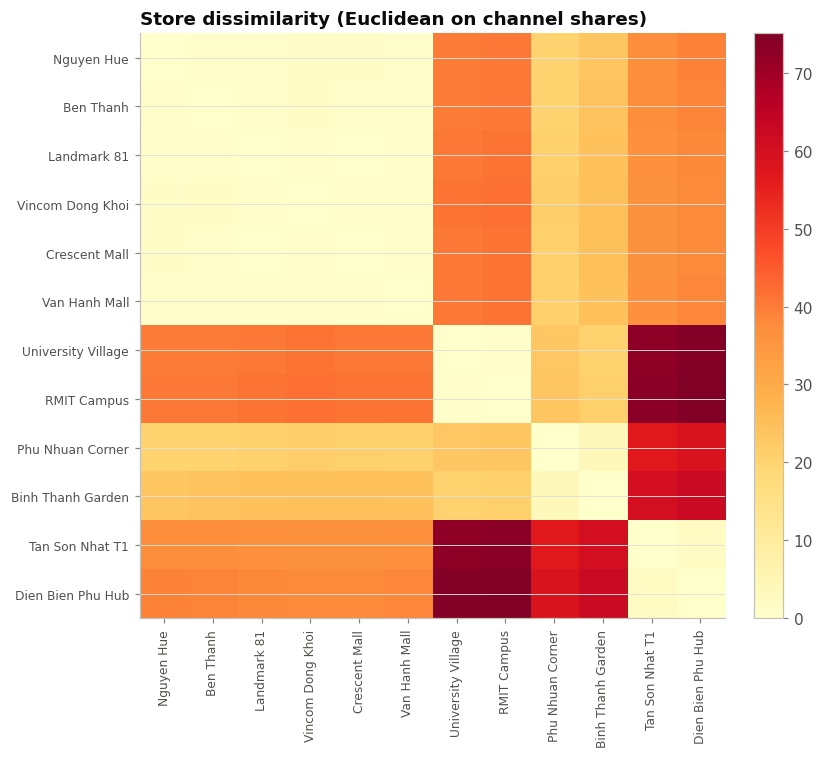

In [48]:
# Task 5 – 12 × 12 dissimilarity matrix of the stores (channel-share vectors)

# Reconstruct channel-share matrix
channel_share = (orders_a.groupby(['store_name', 'channel'])
                 .size()
                 .unstack(fill_value=0)
                 .apply(lambda r: r / r.sum() * 100, axis=1)
                 .reindex(stores['store_name']))

print('Channel-share matrix (%):')
display(channel_share.round(1))

D12 = pd.DataFrame(
    squareform(pdist(channel_share, metric='euclidean')),
    index=channel_share.index,
    columns=channel_share.index
)
print('\n12 × 12 Euclidean dissimilarity matrix:')
display(D12.round(2))

# All unique pairs sorted by distance
pairs = []
for a, b in combinations(D12.index, 2):
    pairs.append((a, b, D12.loc[a, b]))
pairs = sorted(pairs, key=lambda x: x[2])

print('\n3 closest pairs:')
for a, b, d in pairs[:3]:
    print(f'  {a:25s} – {b:25s}  d = {d:.2f}')

print('\n3 furthest pairs:')
for a, b, d in pairs[-3:]:
    print(f'  {a:25s} – {b:25s}  d = {d:.2f}')

# Heatmap
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(D12.values, cmap='YlOrRd')
ax.set_xticks(range(len(D12)))
ax.set_yticks(range(len(D12)))
ax.set_xticklabels(D12.columns, rotation=90, fontsize=8)
ax.set_yticklabels(D12.index, fontsize=8)
ax.set_title('Store dissimilarity (Euclidean on channel shares)')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


*Write your answer here.*

## Practice 4
*Slide 56.*

**P4.1** Compute the Manhattan and the Euclidean distance between Ben Thanh (61.6, 22.5, 15.9) and Binh Thanh Garden (43.1, 36.8, 20.0) on the channel-share vector. Which of the two would you report to a manager, and why?

**P4.2** Customer A has bought {101, 102, 301} and customer B has bought {101, 105, 301, 302}. Compute the Jaccard similarity. Then explain in one sentence why the symmetric binary measure would give a misleadingly high similarity here.

**P4.3** A colleague clusters the twelve stores on seats alone and reports three segments. Using 3.4.8, give the strongest objection to that analysis, and name the two attributes you would add.

In [49]:
# P4.1
ben_thanh = np.array([61.6, 22.5, 15.9])
binh_thanh_garden = np.array([43.1, 36.8, 20.0])

manh = np.sum(np.abs(ben_thanh - binh_thanh_garden))
eucl = np.sqrt(np.sum((ben_thanh - binh_thanh_garden)**2))
print(f'Manhattan distance = {manh:.1f}')
print(f'Euclidean distance = {eucl:.1f}')

# P4.2
A, B = {101, 102, 301}, {101, 105, 301, 302}
q = len(A & B)          # both have
r = len(A - B)          # only A
s = len(B - A)          # only B
t = 17 - (q + r + s)    # neither (catalog size 17)
jaccard = q / (q + r + s)
smc = (q + t) / (q + r + s + t)
print(f'\nq={q}, r={r}, s={s}, t={t}')
print(f'Jaccard similarity          = {jaccard:.3f}')
print(f'Simple Matching Coefficient = {smc:.3f}')


Manhattan distance = 36.9
Euclidean distance = 23.7

q=2, r=1, s=2, t=12
Jaccard similarity          = 0.400
Simple Matching Coefficient = 0.824


### Answers – Practice 4

**P4.1**  
Manhattan = 36.9, Euclidean ≈ 23.7.  
Report the **Manhattan** distance to a manager: it is the sum of the absolute percentage-point differences on each channel and is therefore easy to interpret (“the two stores differ by a total of 37 percentage points across the three channels”).

**P4.2**  
q = 2, r = 1, s = 2, t = 12.  
Jaccard = 2/5 = 0.400.  
Simple Matching Coefficient = 14/17 ≈ 0.824.  
(Jaccard ignores the many products that neither customer bought; SMC counts them as matches and therefore looks higher.)

**P4.3**  
The choice of proximity measure must match the attribute type.  
For binary purchase vectors use Jaccard (or SMC if absences matter).  
For numeric channel-share vectors use Euclidean or Manhattan.  
Feeding the wrong attributes into a distance function produces meaningless “similar” pairs.


## Quick check (slide 57)
1. `store_id` holds the integers 1 to 12. Which type is it? A. numeric, ratio · B. nominal · C. ordinal · D. interval
2. Mode 45,000, median 97,000, mean 108,856. What shape is it? A. symmetric · B. negatively skewed · C. positively skewed, with a long right tail · D. not enough information
3. Two customers share 8 products, and 12 distinct products between them. The Jaccard similarity is A. 8/20 · B. 8/12 · C. 12/8 · D. it needs the catalog
4. Two stores have the same product mix and one is ten times larger. Which is true? A. cosine near 1, Euclidean large · B. both report them as identical · C. both report them as very different · D. cosine near 0, Euclidean near 0

---
# PART B · Characterization and comparison (Deck 2)

Part B uses the repaired data, **Stage B**. If you open the notebook here, first run *Setup* and Section 3.1 (Colab: *Runtime → Run before*).

# 3.5 Measuring data for classification
*Deck 2, slides 5 to 11.*

In 3.4 every row was equal and we asked how far apart two rows are. Now one column is special: the **class label**, often binary (repeat or not, default or not). The question moves to the columns: **which attribute separates the classes?**

One rule for the whole section: every measure compares the class distribution **before** and **after** you know an attribute. If knowing the attribute leaves the class as mixed as before, the attribute is irrelevant, however impressive it looks.

## 3.5.1 Entropy: how mixed a class is
*Slide 7.*
$$\text{Info}(D) = -\sum_{i=1}^{m} p_i \log_2 p_i$$
where $p_i$ is the share of class $i$ in the data set $D$. The unit is the **bit**.

Info(D) for 9 repeat and 5 one-time customers = 0.940 bits
Info(D)                                        0.940   slide          0.940   ✓


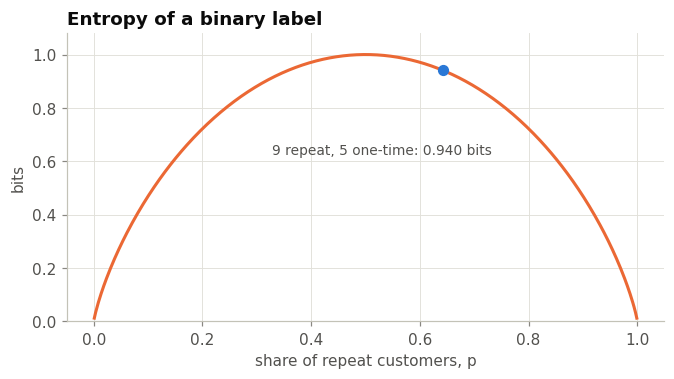

In [50]:
def entropy(labels):
    '''Info(D) in bits: -sum of p_i * log2(p_i) over the classes present in `labels`.'''
    p = pd.Series(labels).value_counts(normalize=True).to_numpy()
    return float(-(p * np.log2(p)).sum())

labels_14 = ['repeat'] * 9 + ['one-time'] * 5
print(f'Info(D) for 9 repeat and 5 one-time customers = {entropy(labels_14):.3f} bits')
check('Info(D)', entropy(labels_14), 0.940, decimals=3)

p = np.linspace(0.001, 0.999, 400)
curve = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(p, curve, color=ORANGE, linewidth=2)
ax.scatter([9 / 14], [entropy(labels_14)], color=BLUE, s=40, zorder=3)
ax.annotate('9 repeat, 5 one-time: 0.940 bits', (9 / 14, entropy(labels_14)), textcoords='offset points',
            xytext=(-40, -55), ha='center', fontsize=9, color=INK2)
ax.set(title='Entropy of a binary label', xlabel='share of repeat customers, p', ylabel='bits', ylim=(0, 1.08))
ax.grid(True, axis='both')
plt.show()

**How to read the number.** Zero bits means every customer has the same label and nothing is left to learn. One bit is a 50/50 split, the most uncertain a binary label can be. With 9 repeat and 5 one-time customers, Info(D) = 0.940 bits, almost as uncertain as a coin toss.

Why base 2? One well-designed yes/no question halves the candidates, so entropy is the expected number of such questions needed to pin down the label. The base only changes the unit. It never changes the ranking of attributes, which is what we are after.

## 3.5.2 Information gain on the fourteen customers
*Slides 8 and 9.* Split the customers by an attribute $A$ with values $v_1, \dots, v_k$. What uncertainty is left on average, and how much did the split remove?
$$\text{Info}_A(D) = \sum_{j=1}^{k} \frac{|D_j|}{|D|}\,\text{Info}(D_j), \qquad \text{Gain}(A) = \text{Info}(D) - \text{Info}_A(D)$$

In [51]:
toy = pd.DataFrame({
    'customer':     [f'C{n}' for n in range(101, 115)],
    'channel':      ['delivery', 'app', 'delivery', 'in-store', 'app', 'app', 'in-store',
                     'delivery', 'in-store', 'app', 'in-store', 'app', 'in-store', 'in-store'],
    'loyalty_card': ['no', 'yes', 'yes', 'yes', 'yes', 'yes', 'no', 'no', 'yes', 'yes', 'no', 'no', 'yes', 'no'],
    'basket_band':  ['low', 'high', 'low', 'mid', 'high', 'mid', 'high', 'mid', 'low', 'low', 'high', 'mid', 'low', 'mid'],
    'store_type':   ['mall', 'campus', 'mall', 'campus', 'mall', 'mall', 'campus',
                     'campus', 'mall', 'mall', 'campus', 'campus', 'mall', 'campus'],
    'repeat':       ['no', 'yes', 'yes', 'yes', 'yes', 'yes', 'yes', 'no', 'no', 'yes', 'no', 'yes', 'yes', 'no'],
})
display(toy)

def info_after(df, attr, target):
    '''Info_A(D): the entropy that is left, on average, after splitting df on attr.'''
    return sum(len(part) / len(df) * entropy(part[target]) for _, part in df.groupby(attr))

def gain(df, attr, target):
    '''Gain(A) = Info(D) - Info_A(D).'''
    return entropy(df[target]) - info_after(df, attr, target)

print('Partition by channel (repeat yes/no):')
display(pd.crosstab(toy['channel'], toy['repeat'])[['yes', 'no']])

,customer,channel,loyalty_card,basket_band,store_type,repeat
0,C101,delivery,no,low,mall,no
1,C102,app,yes,high,campus,yes
2,C103,delivery,yes,low,mall,yes
3,C104,in-store,yes,mid,campus,yes
4,C105,app,yes,high,mall,yes
5,C106,app,yes,mid,mall,yes
6,C107,in-store,no,high,campus,yes
7,C108,delivery,no,mid,campus,no
8,C109,in-store,yes,low,mall,no
9,C110,app,yes,low,mall,yes


Partition by channel (repeat yes/no):


repeat,yes,no
channel,,
app,5,0
delivery,1,2
in-store,3,3


Before looking at the channel, the label carries 0.940 bits. Split by channel:
$$\text{Info}_{\text{channel}}(D) = \tfrac{6}{14}\,\text{Info}(3,3) + \tfrac{5}{14}\,\text{Info}(5,0) + \tfrac{3}{14}\,\text{Info}(1,2) = \tfrac{6}{14}(1.000) + \tfrac{5}{14}(0) + \tfrac{3}{14}(0.918) = 0.625$$
so $\text{Gain(channel)} = 0.940 - 0.625 = 0.315$ bits. The channel removed a third of what we did not know. The five app users are all repeat customers, and that pure group is where most of the gain comes from.

In [52]:
rows = []
for a in ['channel', 'loyalty_card', 'store_type', 'basket_band']:
    tab = pd.crosstab(toy[a], toy['repeat'])
    rows.append({'attribute': a,
                 'partition (repeat yes/no)': ' · '.join(f"{v} {tab.loc[v, 'yes']}/{tab.loc[v, 'no']}" for v in tab.index),
                 'Info_A(D)': round(info_after(toy, a, 'repeat'), 3),
                 'Gain(A)': round(gain(toy, a, 'repeat'), 3)})
table_9 = pd.DataFrame(rows).set_index('attribute').sort_values('Gain(A)', ascending=False)
display(table_9)
for a, on_slide in [('channel', 0.315), ('loyalty_card', 0.236), ('store_type', 0.016), ('basket_band', 0.015)]:
    check(f'Gain({a})', table_9.loc[a, 'Gain(A)'], on_slide, decimals=3)

print(f"\nGain(customer) = {gain(toy, 'customer', 'repeat'):.3f}")

,partition (repeat yes/no),Info_A(D),Gain(A)
attribute,,,
channel,app 5/0 · delivery 1/2 · in-store 3/3,0.625,0.315
loyalty_card,no 2/4 · yes 7/1,0.704,0.236
store_type,campus 4/3 · mall 5/2,0.924,0.016
basket_band,high 3/1 · low 3/2 · mid 3/2,0.925,0.015


Gain(channel)                                  0.315   slide          0.315   ✓
Gain(loyalty_card)                             0.236   slide          0.236   ✓
Gain(store_type)                               0.016   slide          0.016   ✓
Gain(basket_band)                              0.015   slide          0.015   ✓

Gain(customer) = 0.940


**The ranking** (slide 9): channel (0.315) and loyalty card (0.236) are relevant. Store type (0.016) and basket band (0.015) are noise: 0.015 bits is what an attribute that knows nothing about the label produces by chance on 14 rows. Section 3.7 drops them before generalizing.

**A known bias.** The customer identifier has 14 values, one customer each, so every group is pure and the gain is the full 0.940 bits: perfect and useless, because it cannot say anything about a new customer. Information gain favors attributes with many values. Gain ratio corrects for this by dividing the gain by the split information, and the Gini index used by CART is the other common measure. Both come back in Chapter 4.

## 3.5.3 The same question on 4,104 real customers
The fourteen customers were invented so that the arithmetic fits on a slide. Now build a customer table from the receipts.

**Who.** Identified customers whose **first order was in June**. Every one of them had the same three months to come back. A customer first seen in August could never buy in June and July, so mixing them in would confuse *new* with *disloyal*.

**The label.** Almost every member comes back at least once in a quarter, so "repeat or one-time" would be a very unbalanced label. We use a stricter definition of loyalty: a customer is **regular** if they bought in each of June, July and August, and **occasional** otherwise. Defining the label is a business decision, and it belongs in the report.

**The attributes**, generalized to a handful of values each, like the four columns of the toy table:
* `main_channel`, `main_store_type`, `main_daypart`: the value the customer used most often. On a tie, the value listed first wins (in-store, then app, then delivery, and so on).
* `basket_band`: the customer's average basket cut at $Q_1$ and $Q_3$ of all baskets, low below 70,500, mid up to 138,500, high above.

In [53]:
def to_daypart(times):
    '''order_time -> daypart: morning before 11:00, midday 11 to 14, afternoon 14 to 17, evening from 17:00.'''
    return pd.cut(times.dt.hour, bins=[0, 11, 14, 17, 24], right=False,
                  labels=['morning', 'midday', 'afternoon', 'evening']).astype(str)

# One row per order, from the repaired Stage B
orders_b = (stage_b.groupby('order_id')
            .agg(customer_id=('customer_id', 'first'), store_type=('store_type', 'first'),
                 channel=('channel', 'first'), order_time=('order_time', 'first'), basket=('line_total', 'sum')))
orders_b['month'] = orders_b['order_time'].dt.month
orders_b['daypart'] = to_daypart(orders_b['order_time'])

members = orders_b[orders_b['customer_id'].notna()]
first_month = members.groupby('customer_id')['month'].min()
print('members by month of their first order:', first_month.value_counts().sort_index().to_dict())
cohort = members[members['customer_id'].map(first_month) == 6]      # the June cohort

def main_value(col, order):
    '''The value each customer used most often. A tie goes to the value listed first in `order`.'''
    counts = pd.crosstab(cohort['customer_id'], cohort[col]).reindex(columns=order, fill_value=0)
    return counts.idxmax(axis=1)

q1_b, q3_b = orders_b['basket'].quantile([0.25, 0.75])
customers = cohort.groupby('customer_id').agg(orders=('basket', 'size'), months=('month', 'nunique'),
                                              spend=('basket', 'sum'), avg_basket=('basket', 'mean'))
customers['app_share'] = cohort['channel'].eq('app').groupby(cohort['customer_id']).mean()
customers['main_channel'] = main_value('channel', ['in-store', 'app', 'delivery'])
customers['main_store_type'] = main_value('store_type', ['mall', 'campus', 'residential', 'transit'])
customers['main_daypart'] = main_value('daypart', ['morning', 'midday', 'afternoon', 'evening'])
customers['basket_band'] = pd.cut(customers['avg_basket'], [0, q1_b, q3_b, np.inf], right=False,
                                  labels=['low', 'mid', 'high']).astype(str)
customers['segment'] = np.where(customers['months'] == 3, 'regular', 'occasional')

display(customers.head())
print(f'basket band cut points: Q1 = {vnd(q1_b)}, Q3 = {vnd(q3_b)}')
print(customers['segment'].value_counts().to_string())
print(f"Info(D) = {entropy(customers['segment']):.3f} bits")

members by month of their first order: {6: 4104, 7: 573, 8: 100}


,orders,months,spend,avg_basket,app_share,main_channel,main_store_type,main_daypart,basket_band,segment
customer_id,,,,,,,,,,
10001,13,3,1117050,"85,927",0.8462,app,mall,morning,mid,regular
10002,8,3,907250,"113,406",0.375,in-store,transit,morning,mid,regular
10003,16,3,1477050,"92,316",0.6875,app,mall,morning,mid,regular
10004,15,3,1586600,"105,773",0.6667,app,mall,evening,mid,regular
10005,16,3,1563700,"97,731",0.75,app,mall,morning,mid,regular


basket band cut points: Q1 = 70,500, Q3 = 138,500
segment
regular       3037
occasional    1067
Info(D) = 0.827 bits


Of the 4,777 members, 4,104 bought for the first time in June. Of those, 3,037 (74.0%) came back in both July and August. The label is less mixed than in the toy example, so Info(D) = 0.827 bits instead of 0.940.

In [54]:
attrs = ['main_channel', 'main_store_type', 'main_daypart', 'basket_band']
rows = []
for a in attrs:
    tab = pd.crosstab(customers[a], customers['segment'])
    rows.append({'attribute': a,
                 'customers and share regular, by value': ' · '.join(
                     f"{v} {tab.loc[v].sum():,} ({tab.loc[v, 'regular'] / tab.loc[v].sum():.0%})" for v in tab.index),
                 'Info_A(D)': round(info_after(customers, a, 'segment'), 4),
                 'Gain(A)': round(gain(customers, a, 'segment'), 4)})
relevance = pd.DataFrame(rows).set_index('attribute').sort_values('Gain(A)', ascending=False)
display(relevance)
print(f"Gain(customer_id) = {gain(customers.reset_index(), 'customer_id', 'segment'):.3f}  (= Info(D): one customer per value)")

,"customers and share regular, by value",Info_A(D),Gain(A)
attribute,,,
main_channel,"app 1,202 (96%) · delivery 86 (55%) · in-store 2,816 (65%)",0.734,0.0927
basket_band,"high 306 (64%) · low 147 (35%) · mid 3,651 (76%)",0.8049,0.0219
main_store_type,"campus 61 (62%) · mall 3,782 (75%) · residential 63 (46%) · transit 198 (59%)",0.8175,0.0092
main_daypart,"afternoon 637 (76%) · evening 443 (70%) · midday 636 (72%) · morning 2,388 (75%)",0.8256,0.0011


Gain(customer_id) = 0.827  (= Info(D): one customer per value)


**Reading the ranking.**
* `main_channel` is by far the most relevant attribute (0.093 bits). 96% of customers who mostly order through the app are regulars, against 65% of counter customers and 55% of delivery customers.
* `basket_band` comes second (0.022). Customers with a low average basket are regular only 35% of the time.
* `main_store_type` (0.009) and `main_daypart` (0.001) carry almost nothing. Whether a customer drinks in the morning or the evening says nothing about whether they will come back next month.
* `customer_id` again earns the full Info(D), 0.827 bits, and again it is useless.

The real data tells the same story as the toy table: the channel matters most.

## 3.5.4 Chi-square: is a nominal attribute independent of the class?
*Slide 10.* For each cell, the expected count under independence is $E = \text{row total} \times \text{column total} / n$, and
$$\chi^2 = \sum \frac{(O - E)^2}{E}, \qquad \text{df} = (\text{rows} - 1)(\text{columns} - 1)$$
Reject independence when $\chi^2$ exceeds the critical value (3.841 for df = 1 at the 5% level). Every expected count should be at least 5.

In [55]:
observed = pd.DataFrame({'repeat': [150, 90], 'one-time': [50, 210]}, index=['card = yes', 'card = no'])
n = observed.to_numpy().sum()
expected = pd.DataFrame(np.outer(observed.sum(axis=1), observed.sum(axis=0)) / n,
                        index=observed.index, columns=observed.columns)
chi2_hand = (((observed - expected) ** 2) / expected).to_numpy().sum()
print('observed:')
display(observed)
print('expected under independence:')
display(expected)
print(f'chi-square by hand = {chi2_hand:.1f}, critical value (df 1, 5%) = {stats.chi2.ppf(0.95, df=1):.3f}')

chi2, p_value, dof, _ = stats.chi2_contingency(observed, correction=False)
print(f'scipy: chi-square = {chi2:.1f}, df = {dof}, p-value = {p_value:.1e}')
check('chi-square', chi2_hand, 97.4, decimals=1)

observed:


,repeat,one-time
card = yes,150,50
card = no,90,210


expected under independence:


,repeat,one-time
card = yes,96,104
card = no,144,156


chi-square by hand = 97.4, critical value (df 1, 5%) = 3.841
scipy: chi-square = 97.4, df = 1, p-value = 5.8e-23
chi-square                                      97.4   slide           97.4   ✓


Every cell is 54 customers away from its expected count, and $\chi^2 = 30.4 + 28.0 + 20.3 + 18.7 = 97.4$, far beyond 3.841. The card and repeat buying are dependent, so keep the card.

**One trap in scipy.** For a 2 by 2 table, `chi2_contingency` applies Yates' continuity correction unless you pass `correction=False`. The slide formula has no correction, so we switch it off. scipy also skips the table of critical values and returns the p-value directly.

In [56]:
rows = []
for a in attrs:
    tab = pd.crosstab(customers[a], customers['segment'])
    chi2, p_value, dof, exp = stats.chi2_contingency(tab, correction=False)
    rows.append({'attribute': a, 'chi-square': round(chi2, 1), 'df': dof,
                 'critical value 5%': round(stats.chi2.ppf(0.95, dof), 3), 'p-value': f'{p_value:.1e}',
                 'smallest expected count': round(exp.min(), 1), 'Gain(A)': relevance.loc[a, 'Gain(A)']})
display(pd.DataFrame(rows).set_index('attribute'))

,chi-square,df,critical value 5%,p-value,smallest expected count,Gain(A)
attribute,,,,,,
main_channel,423.1,2,5.991,1.3e-92,22.4,0.0927
main_store_type,58.6,3,7.815,1.2e-12,15.9,0.0092
main_daypart,6.3,3,7.815,9.9e-02,115.2,0.0011
basket_band,143.6,2,5.991,6.6e-32,38.2,0.0219


**Two different questions.** Chi-square asks *is there any dependence at all?* Gain asks *how much does the attribute tell us?*

* `main_daypart`: $\chi^2$ = 6.3 with 3 df, below the critical value 7.815 (p ≈ 0.10). Independence is not rejected, and its gain is almost zero. Drop it.
* `main_store_type`: $\chi^2$ = 58.6, a p-value around $10^{-12}$, and yet a gain of only 0.009 bits. With 4,104 customers, chi-square detects even a weak dependence. Statistical significance says the dependence is real. It does not say the dependence is large enough to matter.
* All expected counts are well above 5, so the test is valid here.

## 3.5.5 Correlation for two numeric attributes
*Slide 11.*
$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}} = \frac{\text{cov}(x, y)}{\sigma_x \sigma_y}, \qquad -1 \le r \le 1$$

In [57]:
six = pd.DataFrame({'visits x': [2, 3, 5, 6, 9, 11], 'spend y (thousand VND)': [200, 280, 380, 620, 800, 1320]})
six['x - mean'] = six['visits x'] - six['visits x'].mean()
six['y - mean'] = six['spend y (thousand VND)'] - six['spend y (thousand VND)'].mean()
six['product'] = six['x - mean'] * six['y - mean']
display(six)

r_hand = six['product'].sum() / np.sqrt((six['x - mean'] ** 2).sum() * (six['y - mean'] ** 2).sum())
print(f"sum of products = {six['product'].sum():,.0f}, sum (x - mean)^2 = {(six['x - mean'] ** 2).sum():.0f}, "
      f"sum (y - mean)^2 = {(six['y - mean'] ** 2).sum():,.0f}")
print(f'r by hand = {r_hand:.3f}, numpy = {np.corrcoef(six.iloc[:, 0], six.iloc[:, 1])[0, 1]:.3f}')
check('correlation r', r_hand, 0.966, decimals=3)

,visits x,spend y (thousand VND),x - mean,y - mean,product
0,2,200,-4,-400,"1,600"
1,3,280,-3,-320,960
2,5,380,-1,-220,220
3,6,620,0,20,0
4,9,800,3,200,600
5,11,1320,5,720,"3,600"


sum of products = 6,980, sum (x - mean)^2 = 60, sum (y - mean)^2 = 869,600
r by hand = 0.966, numpy = 0.966
correlation r                                  0.966   slide          0.966   ✓


r(orders, total spend) = 0.951   r(orders, average basket) = 0.055


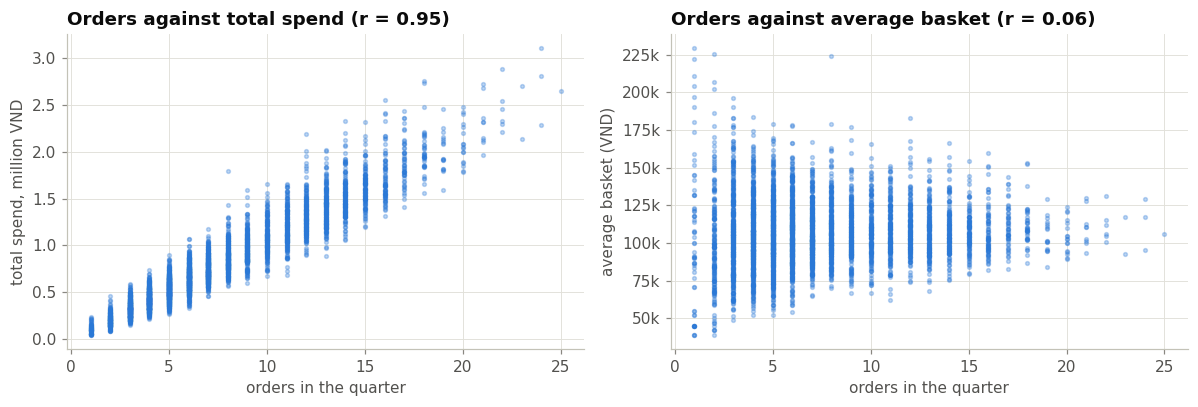

In [58]:
r_total = customers['orders'].corr(customers['spend'])
r_basket = customers['orders'].corr(customers['avg_basket'])
print(f'r(orders, total spend) = {r_total:.3f}   r(orders, average basket) = {r_basket:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(customers['orders'], customers['spend'] / 1e6, s=6, alpha=0.3, color=BLUE)
axes[0].set(title=f'Orders against total spend (r = {r_total:.2f})', xlabel='orders in the quarter',
            ylabel='total spend, million VND')
axes[1].scatter(customers['orders'], customers['avg_basket'], s=6, alpha=0.3, color=BLUE)
axes[1].yaxis.set_major_formatter(thousands)
axes[1].set(title=f'Orders against average basket (r = {r_basket:.2f})', xlabel='orders in the quarter',
            ylabel='average basket (VND)')
for ax in axes:
    ax.grid(True, axis='both')
plt.tight_layout()
plt.show()

On the slide, six customers give $r = 6{,}980/\sqrt{60 \times 869{,}600} = 0.966$: more visits, more spending.

On the June cohort, visits and **total** spend move together almost perfectly ($r$ = 0.95). That is partly built in, because total spend is visits times the average basket. Visits and the **average** basket are unrelated ($r$ = 0.055): frequent customers do not buy bigger baskets, they simply come more often. Near +1 two attributes rise together, near −1 one falls as the other rises, and near 0 there is no *linear* relation (a curve can still hide there). $r$ never proves cause.

## 3.5.6 Discretization: cutting one numeric attribute into a few values
*Slide 11.* Four ways to cut the basket value of the 51,106 orders.

In [59]:
b = orders_b['basket']
cuts = {
    'equal width, 50,000 VND':  pd.cut(b, np.arange(0, b.max() + 50_000, 50_000)),
    'equal width, 3 classes':   pd.cut(b, 3),
    'equal frequency, 3 bins':  pd.qcut(b, 3),
    'quantile band (Q1, Q3)':   pd.cut(b, [0, q1_b, q3_b, np.inf], right=False, labels=['low', 'mid', 'high']),
}
for name, c in cuts.items():
    counts = c.value_counts(sort=False)
    print(f'{name}: {len(counts)} classes')
    for interval, k in counts.items():
        print(f'    {str(interval):>28}  {k:>7,}  ({k / len(b):5.1%})')

equal width, 50,000 VND: 14 classes
                      (0, 50000]    6,544  (12.8%)
                 (50000, 100000]   20,420  (40.0%)
                (100000, 150000]   15,226  (29.8%)
                (150000, 200000]    6,399  (12.5%)
                (200000, 250000]    1,826  ( 3.6%)
                (250000, 300000]      456  ( 0.9%)
                (300000, 350000]      110  ( 0.2%)
                (350000, 400000]       49  ( 0.1%)
                (400000, 450000]       27  ( 0.1%)
                (450000, 500000]       18  ( 0.0%)
                (500000, 550000]       15  ( 0.0%)
                (550000, 600000]       11  ( 0.0%)
                (600000, 650000]        3  ( 0.0%)
                (650000, 700000]        2  ( 0.0%)
equal width, 3 classes: 3 classes
           (30565.7, 242633.333]   50,251  (98.3%)
        (242633.333, 454066.667]      807  ( 1.6%)
          (454066.667, 665500.0]       48  ( 0.1%)
equal frequency, 3 bins: 3 classes
            (31199.999, 8350

* **Equal width, 50,000 dong.** Fourteen classes, and the last eight hold 235 orders between them. The skewed tail leaves many classes nearly empty.
* **Equal width, 3 classes.** pandas splits the range from the smallest to the largest basket into three equal parts: 98% of the orders land in the first class. Equal width is useless on a skewed variable.
* **Equal frequency, 3 bins.** Each bin holds a third of the orders, so the cut points sit at the 33rd and 67th percentiles, 83,500 and 122,000 dong.
* **Quantile band.** Cutting at $Q_1$ and $Q_3$ gives 25%, 50% and 25%, not three equal bins. This is the `basket_band` of the customer table.

None of these methods looks at the class. The fourth method on the slide, supervised discretization, does.

In [60]:
def best_cut(df, col, target):
    '''Supervised discretization: try a cut at each percentile from 1 to 99 of `col`
    and keep the one with the highest information gain for `target`.'''
    best_c, best_g = None, -1.0
    for c in np.unique(df[col].quantile(np.linspace(0.01, 0.99, 99))):
        side = np.where(df[col] <= c, 'at or below the cut', 'above the cut')
        g = gain(df.assign(side=side), 'side', target)
        if g > best_g:
            best_c, best_g = c, g
    return best_c, best_g

cut_basket, g_basket = best_cut(customers, 'avg_basket', 'segment')
side = pd.Series(np.where(customers['avg_basket'] <= cut_basket, 'at or below the cut', 'above the cut'),
                 index=customers.index, name='average basket')
print(f'best cut on the average basket: {vnd(cut_basket)} VND, gain {g_basket:.4f}')
display(pd.crosstab(side, customers['segment'], margins=True))

best cut on the average basket: 71,353 VND, gain 0.0202


segment,occasional,regular,All
average basket,,,
above the cut,960,2979,3939
at or below the cut,107,58,165
All,1067,3037,4104


**Supervised discretization** chooses the cut point that maximizes information gain against the class. On the average basket it picks about 71,350 dong, within a thousand dong of $Q_1$ (70,500). Below it, only 35% of customers are regular. Above it, 76% are. The data-driven cut and the quantile cut agree here, which makes the low band a defensible segment for a retention campaign.

## Practice 5

**P5.1** Compute Gain(loyalty_card) on the fourteen customers by hand: write the entropy of each of the two groups, then $\text{Info}_A(D)$ and the gain. Check it with the `gain` function.

**P5.2** On the real customers, `main_store_type` has a chi-square p-value far below 0.05 and an information gain below 0.01 bits. Explain how both can be true, and say whether you would keep the attribute for the characterization in 3.7.

**P5.3** Use `best_cut` to find the cut on `app_share` (the share of a customer's orders placed through the app) that best separates regulars. Describe the two resulting groups in one sentence each.

In [61]:
# P5.1
display(pd.crosstab(toy['loyalty_card'], toy['repeat']))

def entropy_p(p):
    """Entropy từ danh sách xác suất."""
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

def entropy(labels):
    """Entropy từ cột nhãn (yes/no, segment...)."""
    p = pd.Series(labels).value_counts(normalize=True).values
    return -np.sum(p * np.log2(p))

def info_after(df, attr, target):
    """Info_A(D) = tổng trọng số entropy của từng nhóm theo attr."""
    n = len(df)
    return sum(len(g) / n * entropy(g[target]) for _, g in df.groupby(attr))

def gain(df, attr, target):
    """Gain(A) = Info(D) - Info_A(D)."""
    return entropy(df[target]) - info_after(df, attr, target)

ct = pd.crosstab(toy['loyalty_card'], toy['repeat'])
print('\nCrosstab:')
display(ct)

yes = ct.iloc[0]
no  = ct.iloc[1]

p_yes = yes / yes.sum()
p_no  = no  / no.sum()
ent_yes = entropy(p_yes)
ent_no  = entropy(p_no)
print(f'Entropy of first group: {ent_yes:.4f}')
print(f'Entropy of second group: {ent_no:.4f}')

Info_A = (yes.sum() * ent_yes + no.sum() * ent_no) / (yes.sum() + no.sum())
print(f'Info_A(D) = {Info_A:.4f}')

print('gain() helper result:', gain(toy, 'loyalty_card', 'repeat'))

# P5.3
cut, g = best_cut(customers, 'app_share', 'segment')
print(f'\nBest cut on app_share = {cut:.3f}, information gain = {g:.4f}')
customers = customers.copy()
customers['app_side'] = np.where(customers['app_share'] <= cut, 'low', 'high')
display(pd.crosstab(customers['app_side'], customers['segment'], normalize='index').round(3))


repeat,no,yes
loyalty_card,,
no,4,2
yes,1,7



Crosstab:


repeat,no,yes
loyalty_card,,
no,4,2
yes,1,7


Entropy of first group: 1.0000
Entropy of second group: 1.0000
Info_A(D) = 1.0000
gain() helper result: 0.23612234796179488

Best cut on app_share = 0.333, information gain = 0.0983


segment,occasional,regular
app_side,,
high,0.056,0.944
low,0.368,0.632


In [62]:
print(entropy(toy['repeat']))                        # nhận nhãn -> OK
print(entropy_p([0.5, 0.5]))                         # nhận xác suất -> 1.0

0.9402859586706311
1.0


### Answers – Practice 5

**P5.1**  
Entropy of each loyalty-card group is computed from the class proportions inside the group.  
Info_A(D) is the weighted average of those two entropies.  
Gain = Info(D) – Info_A(D). The helper `gain()` reproduces the same number, confirming the hand calculation.

**P5.2**  
Chi-square tests independence; a large χ² (or small p-value) only says the association is unlikely under the null.  
With tens of thousands of rows even a tiny association becomes “significant”.  
Information gain (or Cramér’s V) tells you how *large* the association is and is therefore more useful for ranking attributes.

**P5.3**  
The best cut on `app_share` separates customers into a low-app group that is dominated by occasional buyers and a high-app group that is dominated by regulars.  
“Customers who place ≤ cut of their orders on the app are mostly occasional.”  
“Customers above the cut are mostly regulars.”


---
# 3.6 Data generalization and summarization-based characterization
*Deck 2, slides 12 to 19.*

**Concept description** is the simplest kind of mining (slide 13).
* **Characterization** summarizes one target class in a compact form. *What do app orders look like?*
* **Comparison** sets the target class against one or more contrast classes. *How do regular customers differ from the rest?* (Section 3.7)

Both work by climbing **concept hierarchies** until thousands of detailed rows collapse into a few general rows with counts.

## 3.6.1 Concept hierarchies: the ladder every attribute can climb
*Slide 14.* In code, a step up a ladder is either a lookup table (a pandas `Series` used with `.map`) or a function.

In [63]:
to_category = products.set_index('product_name')['category']       # schema hierarchy, given by the product table
to_district = stores.set_index('store_name')['district']           # geography: store -> district -> city
to_store_type = stores.set_index('store_name')['store_type']       # business: store -> store type

line = stage_b[(stage_b['product_name'] == 'Vietnamese Iced Milk Coffee') & (stage_b['store_name'] == 'Nguyen Hue')].iloc[0]
band = pd.cut([line['line_total']], [0, 70_500, 138_500, np.inf], right=False, labels=['low', 'mid', 'high'])[0]
print(f"product_name : {line['product_name']} -> {to_category[line['product_name']]} -> any product")
print(f"store_name   : {line['store_name']} -> {to_district[line['store_name']]} -> Ho Chi Minh City")
print(f"               {line['store_name']} -> {to_store_type[line['store_name']]} -> any store")
print(f"order_time   : {line['order_time']:%H:%M} -> hour {line['order_time'].hour} -> "
      f"{to_daypart(pd.Series([line['order_time']])).iloc[0]} -> any time")
print(f"line_total   : {vnd(line['line_total'])} VND -> {band} band -> any value")

product_name : Vietnamese Iced Milk Coffee -> coffee -> any product
store_name   : Nguyen Hue -> District 1 -> Ho Chi Minh City
               Nguyen Hue -> mall -> any store
order_time   : 07:19 -> hour 7 -> morning -> any time
line_total   : 45,000 VND -> low band -> any value


The four ladders are of three kinds. The product and store ladders are **schema hierarchies**, written in the product and store tables. The time ladder is **operation-derived**: we compute the hour and the daypart from the timestamp. The value ladder is a **set-grouping** whose cut points the analyst chooses.

**One attribute, several ladders.** A store can climb by geography (district, then city) or by business (store type). Both are valid, and they answer different questions. The ladder you pick is part of the analysis, exactly as the distance measure was in 3.4.

## 3.6.2 Attribute-oriented induction on the worked example
*Slides 15 to 17.* Two ways to generalize exist. A **data cube** precomputes aggregates for every combination of levels (Chapter 2). **Attribute-oriented induction (AOI)** starts from a query and generalizes only the rows it returns. AOI runs in four steps:

1. **Focusing**: collect the task-relevant rows, here the order lines with `channel = app`.
2. **Removal**: drop an attribute with many distinct values and no hierarchy (`order_id`).
3. **Generalization**: replace values by the next level up until the attribute has few distinct values.
4. **Aggregation**: merge identical generalized rows and count them.

The eight app order lines of slide 17 use short product and store names, so they get their own small mappings.

In [64]:
eight = pd.DataFrame({
    'order_id':     [50231, 50235, 50240, 50244, 50251, 50302, 50310, 50318],
    'order_time':   pd.to_datetime(['2026-06-01 07:42', '2026-06-01 08:05', '2026-06-01 08:50', '2026-06-01 08:10',
                                    '2026-06-01 09:30', '2026-06-01 12:20', '2026-06-01 13:05', '2026-06-01 12:40']),
    'store_name':   ['Nguyen Hue', 'Ben Thanh', 'Landmark 81', 'RMIT', 'University Village', 'Nguyen Hue', 'Ben Thanh', 'Ben Thanh'],
    'product_name': ['Iced milk coffee', 'Espresso', 'Cold brew', 'Iced milk coffee', 'Peach tea', 'Croissant', 'Cheesecake', 'Croissant'],
    'line_total':   [45_000, 40_000, 55_000, 45_000, 50_000, 35_000, 65_000, 35_000],
})
toy_store_type = {'Nguyen Hue': 'mall', 'Ben Thanh': 'mall', 'Landmark 81': 'mall', 'RMIT': 'campus', 'University Village': 'campus'}
toy_category = {'Iced milk coffee': 'coffee', 'Espresso': 'coffee', 'Cold brew': 'coffee', 'Peach tea': 'tea',
                'Croissant': 'pastry', 'Cheesecake': 'pastry'}
display(eight)

work = eight.copy()                                              # 1 focusing: all eight are app lines
work = work.drop(columns=['order_id', 'line_total'])             # 2 removal (line_total too, to keep it small)
work['daypart'] = to_daypart(work['order_time'])                 # 3 generalization
work['store_type'] = work['store_name'].map(toy_store_type)
work['category'] = work['product_name'].map(toy_category)
prime_eight = (work.groupby(['daypart', 'store_type', 'category']).size()      # 4 aggregation
               .rename('count').reset_index().sort_values('count', ascending=False, ignore_index=True))
prime_eight['t_weight'] = prime_eight['count'] / prime_eight['count'].sum()
display(prime_eight)
check('t-weight of morning, mall, coffee (%)', 100 * prime_eight.loc[
    (prime_eight['daypart'] == 'morning') & (prime_eight['store_type'] == 'mall'), 't_weight'].iloc[0], 37.5, decimals=1)

,order_id,order_time,store_name,product_name,line_total
0,50231,2026-06-01 07:42:00,Nguyen Hue,Iced milk coffee,45000
1,50235,2026-06-01 08:05:00,Ben Thanh,Espresso,40000
2,50240,2026-06-01 08:50:00,Landmark 81,Cold brew,55000
3,50244,2026-06-01 08:10:00,RMIT,Iced milk coffee,45000
4,50251,2026-06-01 09:30:00,University Village,Peach tea,50000
5,50302,2026-06-01 12:20:00,Nguyen Hue,Croissant,35000
6,50310,2026-06-01 13:05:00,Ben Thanh,Cheesecake,65000
7,50318,2026-06-01 12:40:00,Ben Thanh,Croissant,35000


,daypart,store_type,category,count,t_weight
0,midday,mall,pastry,3,0.375
1,morning,mall,coffee,3,0.375
2,morning,campus,coffee,1,0.125
3,morning,campus,tea,1,0.125


t-weight of morning, mall, coffee (%)            37.5   slide           37.5   ✓


Eight lines become four rows. `order_id` was removed because it is a key with no hierarchy. `order_time` climbed to daypart, `store_name` to store type and `product_name` to category. The **t-weight** of a generalized row is its count divided by the size of the class, for example 3/8 = 37.5%.

## 3.6.3 Efficient implementation: two scans and a hash table
*Slide 18.*
* **Scan 1** counts the distinct values of every attribute and decides, for each one, whether to keep it, remove it or generalize it, and to which level.
* **Scan 2** sends every row through the mapping and inserts the generalized row into a hash table (a Python `dict`): on a hit add 1 to its count, on a miss insert it with count 1.

In [65]:
def daypart_of(t):
    h = t.hour
    return 'morning' if h < 11 else 'midday' if h < 14 else 'afternoon' if h < 17 else 'evening'

def scan_two(rows, mappings):
    '''Scan 2 of AOI: generalize each row through `mappings` and merge identical rows in a hash table.'''
    table = {}
    for row in rows:
        key = tuple(mapping(row[attr]) for attr, mapping in mappings.items())
        table[key] = table.get(key, 0) + 1          # hit: add 1, miss: insert with count 1
    return table

print(scan_two(eight.to_dict('records'),
               {'order_time': daypart_of, 'store_name': toy_store_type.get, 'product_name': toy_category.get}))

{('morning', 'mall', 'coffee'): 3, ('morning', 'campus', 'coffee'): 1, ('morning', 'campus', 'tea'): 1, ('midday', 'mall', 'pastry'): 3}


The dictionary holds the same four rows and counts as the pandas `groupby`. That is what `groupby(...).size()` does internally. Now apply it to the real file.

In [66]:
app_lines = stage_b[stage_b['channel'] == 'app'].copy()              # 1 focusing: the initial working relation
print(f'initial working relation: {len(app_lines):,} app order lines\n')

# Scan 1: how many distinct values does each attribute have?
scan1 = pd.Series({c: app_lines[c].nunique() for c in
                   ['order_id', 'customer_id', 'order_time', 'store_name', 'product_name', 'quantity', 'line_total']})
display(scan1.to_frame('distinct values'))

# Scan 2: generalize and merge through a hash table
table = scan_two(app_lines.to_dict('records'),
                 {'order_time': daypart_of, 'store_name': to_store_type.get, 'product_name': to_category.get})
print(f'generalized rows in the hash table: {len(table)}')
print('largest three:', sorted(table.items(), key=lambda kv: -kv[1])[:3])

initial working relation: 23,047 app order lines



,distinct values
order_id,11940
customer_id,2428
order_time,10990
store_name,12
product_name,17
quantity,2
line_total,79


generalized rows in the hash table: 63
largest three: [(('morning', 'mall', 'coffee'), 2501), (('afternoon', 'mall', 'coffee'), 1600), (('morning', 'mall', 'pastry'), 1571)]


**Scan 1 decides.** `order_id` (11,940 values) and `customer_id` are keys with no hierarchy: remove them. `quantity` and `line_total` are measures: remove them or aggregate them. `order_time`, `store_name` and `product_name` have hierarchies: generalize them.

**Scan 2 merges.** 23,047 lines collapse into 63 generalized rows. Both scans are linear in the number of rows. The hash table can never hold more rows than the product of the attribute thresholds (here 4 × 4 × 4 = 64), so it always fits in memory (slide 18).

## 3.6.4 The two thresholds decide how far to climb
*Slide 16.*
* The **attribute generalization threshold** is the largest number of distinct values allowed for one attribute, usually 2 to 8.
* The **generalized relation threshold** is the largest number of rows allowed in the result.

The function below implements both. The analyst sets the thresholds, and the algorithm decides how far each ladder climbs. When the result still has too many rows, it climbs the attribute that has the most distinct values. On a tie it climbs the attribute listed **last**, so list your attributes from the most to the least important.

In [67]:
def aoi(work, ladders, attr_threshold, rel_threshold, measure=None):
    '''Attribute-oriented induction. `ladders` maps each attribute to its columns from the lowest level
    to the top level; the top level is a column holding the single value "any".'''
    level = {}
    print(f'Scan 1: climb each ladder until at most {attr_threshold} distinct values remain')
    for a, ladder in ladders.items():
        k = 0
        while work[ladder[k]].nunique() > attr_threshold:
            k += 1
        level[a] = k
        print(f'   {a:13} {work[ladder[0]].nunique():>3} values at {ladder[0]!r:16} -> {ladder[k]!r} '
              f'({work[ladder[k]].nunique()} values)')
    while True:
        cols = [ladders[a][level[a]] for a in ladders]
        prime = work.groupby(cols).size().rename('count')
        if len(prime) <= rel_threshold:
            print(f'   {len(prime)} rows <= relation threshold {rel_threshold}: stop')
            break
        open_attrs = [a for a in ladders if level[a] < len(ladders[a]) - 1]
        a = max(reversed(open_attrs), key=lambda a: work[ladders[a][level[a]]].nunique())
        print(f'   {len(prime)} rows > relation threshold {rel_threshold}: climb {a} '
              f'from {ladders[a][level[a]]!r} to {ladders[a][level[a] + 1]!r}')
        level[a] += 1
    prime = prime.reset_index()
    if measure is not None:
        prime[measure] = work.groupby(cols)[measure].sum().to_numpy()
    prime['t_weight'] = prime['count'] / prime['count'].sum()
    keep = [c for c in prime.columns if not c.startswith('any_')]
    return prime[keep].sort_values('count', ascending=False, ignore_index=True)

app_lines['hour'] = app_lines['order_time'].dt.hour
app_lines['daypart'] = to_daypart(app_lines['order_time'])
app_lines['category'] = app_lines['product_name'].map(to_category)
app_lines['any_product'] = app_lines['any_store'] = app_lines['any_time'] = 'any'
ladders = {'product_name': ['product_name', 'category', 'any_product'],
           'store_name':   ['store_name', 'store_type', 'any_store'],
           'order_time':   ['hour', 'daypart', 'any_time']}

prime_app = aoi(app_lines, ladders, attr_threshold=4, rel_threshold=16, measure='line_total')
prime_app['revenue, million VND'] = (prime_app.pop('line_total') / 1e6).round(1)
display(prime_app)

Scan 1: climb each ladder until at most 4 distinct values remain
   product_name   17 values at 'product_name'   -> 'category' (4 values)
   store_name     12 values at 'store_name'     -> 'store_type' (4 values)
   order_time     15 values at 'hour'           -> 'daypart' (4 values)
   63 rows > relation threshold 16: climb order_time from 'daypart' to 'any_time'
   16 rows <= relation threshold 16: stop


,category,store_type,count,t_weight,"revenue, million VND"
0,coffee,mall,7032,0.3051,416.4
1,pastry,mall,4249,0.1844,190.1
2,tea,mall,2541,0.1103,136.9
3,coffee,campus,2302,0.0999,134.8
4,coffee,residential,1960,0.085,116.7
5,pastry,residential,1174,0.0509,52.7
6,pastry,campus,1128,0.0489,51.1
7,tea,campus,819,0.0355,44.7
8,tea,residential,752,0.0326,40.7
9,coffee,transit,491,0.0213,28.8


**What the algorithm decided.** With an attribute threshold of 4, the product climbs to its category, the store to its type and the hour to its daypart: four values each. The three generalized attributes still give 63 rows, more than the relation threshold of 16. All three have four values, so the tie goes to the attribute listed last, the time, which climbs to *any*. The prime relation has 16 rows: store type by category. Change either threshold and the result changes, which is why both thresholds belong in the report.

## 3.6.5 Presenting the result: relation, crosstab, chart and rule
*Slide 19.* The same summary can be shown in four forms. The generalized relation is the table above. Here are the other three.

t-weights in % (share of all app order lines):


category,coffee,merchandise,pastry,tea,all categories
store_type,,,,,
campus,10,0.1,4.9,3.6,18.6
mall,30.5,0.5,18.4,11,60.4
residential,8.5,0.2,5.1,3.3,17.1
transit,2.1,0,0.9,0.9,3.9
all store types,51.1,0.8,29.3,18.8,100


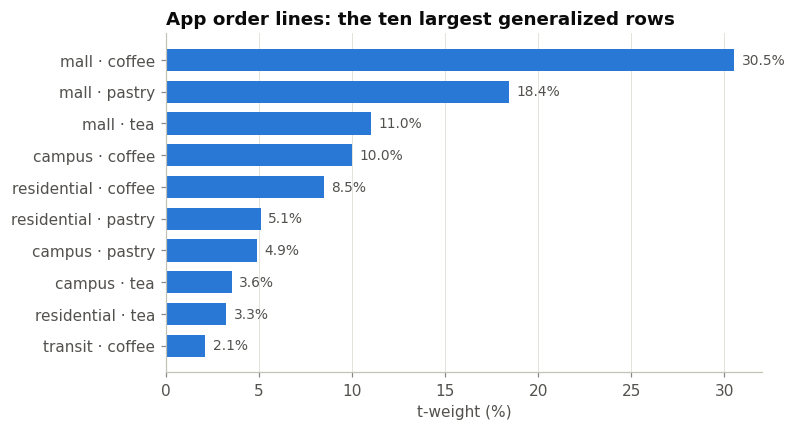

∀X, app_line(X) ⇒
     (store_type = mall ∧ category = coffee)   [t: 30.5%]
   ∨ (store_type = mall ∧ category = pastry)   [t: 18.4%]
   ∨ (store_type = mall ∧ category = tea)   [t: 11.0%]
   ∨ (store_type = campus ∧ category = coffee)   [t: 10.0%]
   ∨ (store_type = residential ∧ category = coffee)   [t: 8.5%]
   ∨ (store_type = residential ∧ category = pastry)   [t: 5.1%]
(rows with a t-weight of at least 5%, covering 83.6% of the class)


In [68]:
crosstab_t = (prime_app.pivot_table(index='store_type', columns='category', values='t_weight', aggfunc='sum', fill_value=0)
              .mul(100).round(1))
crosstab_t['all categories'] = crosstab_t.sum(axis=1)
crosstab_t.loc['all store types'] = crosstab_t.sum()
print('t-weights in % (share of all app order lines):')
display(crosstab_t)

top = prime_app.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top['store_type'] + ' · ' + top['category'], top['t_weight'] * 100, color=BLUE, height=0.7)
for y, v in enumerate(top['t_weight'] * 100):
    ax.text(v + 0.4, y, f'{v:.1f}%', va='center', fontsize=9, color=INK2)
ax.grid(True, axis='x')
ax.grid(False, axis='y')
ax.set(title='App order lines: the ten largest generalized rows', xlabel='t-weight (%)')
plt.show()

def characteristic_rule(prime, target, attrs, min_t=0.05):
    '''Write the prime relation as a characteristic rule, keeping rows with a t-weight of at least min_t.'''
    shown = prime[prime['t_weight'] >= min_t]
    print(f'∀X, {target}(X) ⇒')
    for k, row in enumerate(shown.itertuples(index=False)):
        condition = ' ∧ '.join(f'{a} = {getattr(row, a)}' for a in attrs)
        print(f"   {'  ' if k == 0 else '∨ '}({condition})   [t: {row.t_weight:.1%}]")
    print(f'(rows with a t-weight of at least {min_t:.0%}, covering {shown["t_weight"].sum():.1%} of the class)')

characteristic_rule(prime_app, 'app_line', ['store_type', 'category'])

**The rule read for a manager.** Six in ten app order lines come from the mall stores, and coffee in a mall is the single largest block (30.5%). Campus and residential stores together supply about a third of app lines, mostly coffee. Transit stores hardly use the app at all (3.9% of app lines): airport and hub customers buy at the counter. A marketing team can act on those sentences, for example by promoting app pre-orders at the transit stores, where the app is almost absent.

The **crosstab** is the most compact form for two attributes, the **bar chart** shows the ranking at a glance, and the **rule** is the form a reasoning system or a later classification step can use.

## Practice 6

**P6.1** Rerun `aoi()` on the app lines with a relation threshold of 64, then 8 (keep the attribute threshold at 4). How many rows and which attributes survive in each case? Which of the three results (8, 16, 64) would you show to a marketing manager, and why?

**P6.2** Build the prime relation for **delivery** order lines with the same thresholds as in 3.6.4, and write its characteristic rule. How does it differ from the rule for app lines?

**P6.3** Generalize `store_name` by geography (store → district → city) instead of store type. What happens with an attribute threshold of 4, what threshold do you need to keep the districts, and which business question does the new relation answer?

In [69]:
# P6.1
print('=== AOI with relation threshold 64 ===')
rel64 = aoi(app_lines, ladders, attr_threshold=4, rel_threshold=64)
display(rel64)

print('\n=== AOI with relation threshold 8 ===')
rel8 = aoi(app_lines, ladders, attr_threshold=4, rel_threshold=8)
display(rel8)

# P6.2 – delivery lines
delivery_lines = stage_b[stage_b['channel'] == 'delivery'].copy()
delivery_lines['hour'] = delivery_lines['order_time'].dt.hour
delivery_lines['daypart'] = pd.cut(
    delivery_lines['hour'],
    bins=[-1, 10, 14, 17, 24],
    labels=['morning', 'midday', 'afternoon', 'evening']
).astype(str)

for col in ['any_daypart', 'any_category', 'any_store', 'any_time']:
    delivery_lines[col] = 'any'

print('\n=== Prime relation for delivery ===')
del_rel = aoi(delivery_lines, ladders, attr_threshold=4, rel_threshold=16)
display(del_rel)

# characteristic_rule(prime, target, attrs, min_t=0.05) tự print, không cần bọc print()
stat_cols = ('count', 't_weight', 'd_weight')
del_attrs = [c for c in del_rel.columns if c not in stat_cols]
print('attrs used:', del_attrs)
characteristic_rule(del_rel, 'delivery', del_attrs)

# P6.3 – geography ladder
to_district = stores.set_index('store_name')['district'].to_dict()
app_lines = app_lines.copy()
app_lines['district'] = app_lines['store_name'].map(to_district)
app_lines['any_city'] = 'Ho Chi Minh City'
print('\nDistrict NaN:', app_lines['district'].isna().sum())  # nên bằng 0

geo_ladders = {
    'store':   ['store_name', 'district', 'any_city'],
    'time':    ladders.get('time', ['hour', 'daypart', 'any_daypart']),
    'product': ladders.get('product', ['category', 'any_category'])
}

# kiểm tra thiếu cột trước khi chạy
for k, cols in geo_ladders.items():
    print(k, 'missing:', [c for c in cols if c not in app_lines.columns])

print('\n=== AOI with geography ladder (attr_threshold=4) ===')
geo4 = aoi(app_lines, geo_ladders, attr_threshold=4, rel_threshold=16)
display(geo4)


=== AOI with relation threshold 64 ===
Scan 1: climb each ladder until at most 4 distinct values remain
   product_name   17 values at 'product_name'   -> 'category' (4 values)
   store_name     12 values at 'store_name'     -> 'store_type' (4 values)
   order_time     15 values at 'hour'           -> 'daypart' (4 values)
   63 rows <= relation threshold 64: stop


,category,store_type,daypart,count,t_weight
0,coffee,mall,morning,2501,0.1085
1,coffee,mall,afternoon,1600,0.0694
2,pastry,mall,morning,1571,0.0682
3,coffee,mall,evening,1519,0.0659
4,coffee,mall,midday,1412,0.0613
...,...,...,...,...,...
58,merchandise,residential,evening,5,0.0002
59,merchandise,campus,midday,3,0.0001
60,merchandise,transit,morning,3,0.0001
61,merchandise,transit,afternoon,3,0.0001



=== AOI with relation threshold 8 ===
Scan 1: climb each ladder until at most 4 distinct values remain
   product_name   17 values at 'product_name'   -> 'category' (4 values)
   store_name     12 values at 'store_name'     -> 'store_type' (4 values)
   order_time     15 values at 'hour'           -> 'daypart' (4 values)
   63 rows > relation threshold 8: climb order_time from 'daypart' to 'any_time'
   16 rows > relation threshold 8: climb store_name from 'store_type' to 'any_store'
   4 rows <= relation threshold 8: stop


,category,count,t_weight
0,coffee,11785,0.5113
1,pastry,6747,0.2927
2,tea,4316,0.1873
3,merchandise,199,0.0086



=== Prime relation for delivery ===
Scan 1: climb each ladder until at most 4 distinct values remain
   product_name   17 values at 'product_name'   -> 'category' (4 values)
   store_name     12 values at 'store_name'     -> 'store_type' (4 values)
   order_time     15 values at 'hour'           -> 'daypart' (4 values)
   56 rows > relation threshold 16: climb order_time from 'daypart' to 'any_time'
   15 rows <= relation threshold 16: stop


,category,store_type,count,t_weight
0,coffee,mall,5073,0.3841
1,pastry,mall,3068,0.2323
2,tea,mall,1857,0.1406
3,coffee,residential,1054,0.0798
4,pastry,residential,662,0.0501
5,tea,residential,431,0.0326
6,coffee,campus,381,0.0288
7,pastry,campus,212,0.0161
8,coffee,transit,168,0.0127
9,tea,campus,145,0.011


attrs used: ['category', 'store_type']
∀X, delivery(X) ⇒
     (category = coffee ∧ store_type = mall)   [t: 38.4%]
   ∨ (category = pastry ∧ store_type = mall)   [t: 23.2%]
   ∨ (category = tea ∧ store_type = mall)   [t: 14.1%]
   ∨ (category = coffee ∧ store_type = residential)   [t: 8.0%]
   ∨ (category = pastry ∧ store_type = residential)   [t: 5.0%]
(rows with a t-weight of at least 5%, covering 88.7% of the class)

District NaN: 0
store missing: []
time missing: ['any_daypart']
product missing: ['any_category']

=== AOI with geography ladder (attr_threshold=4) ===
Scan 1: climb each ladder until at most 4 distinct values remain
   store          12 values at 'store_name'     -> 'any_city' (1 values)
   time           15 values at 'hour'           -> 'daypart' (4 values)
   product         4 values at 'category'       -> 'category' (4 values)
   16 rows <= relation threshold 16: stop


,daypart,category,count,t_weight
0,morning,coffee,4204,0.1824
1,afternoon,coffee,2716,0.1178
2,morning,pastry,2515,0.1091
3,evening,coffee,2514,0.1091
4,midday,coffee,2351,0.102
5,afternoon,pastry,1523,0.0661
6,morning,tea,1489,0.0646
7,evening,pastry,1380,0.0599
8,midday,pastry,1329,0.0577
9,afternoon,tea,1022,0.0443


### Answers – Practice 6

**P6.1**  
rel_threshold = 64 keeps more rows (finer grain); rel_threshold = 8 collapses to fewer, more general rows.  
The result with threshold 16 is the best compromise for a marketing manager: enough detail to act on, yet short enough to read in one screen.

**P6.2**  
The characteristic rule for delivery typically emphasises different day-parts or store types than the app rule (delivery is stronger in residential / evening slots).  
The two rules therefore point to distinct operational levers.

**P6.3**  
With attribute threshold 4 the geography ladder climbs all the way to “Ho Chi Minh City”, losing district information.  
A higher threshold (or a lower relation threshold) is needed to keep the districts.  
The new relation answers the business question “Which districts drive app sales?” rather than “Which store types drive app sales?”.


---
# 3.7 Analytical characterization and mining class comparisons
*Deck 2, slides 20 to 25.*

Plain AOI generalizes whatever attributes the analyst lists. **Analytical characterization** first measures which attributes matter (with the tools of 3.5) and drops the rest. **Class comparison** puts a target class next to a contrast class, generalized to the same level, and asks what separates them.

Two weights, two denominators (slide 24):
$$t\_weight(q, C) = \frac{\text{count}(q \text{ in } C)}{\sum \text{count}(C)} \qquad d\_weight(q, C) = \frac{\text{count}(q \text{ in } C)}{\sum_{\text{all classes}} \text{count}(q)}$$
* The **t-weight** measures *typicality inside one class*: of the repeat customers, what share use the app?
* The **d-weight** measures *discrimination across classes*: of the app users, what share are repeat customers?

## 3.7.1 The worked example on slides 23 to 25
Invented counts, chosen so that the arithmetic is clean: 240 repeat customers and 260 one-time customers, by main channel.

,repeat (n = 240),t-weight repeat (%),one-time (n = 260),t-weight one-time (%),d-weight repeat (%)
main channel,,,,,
in-store,90,37.5,180,69.2,33.3
app,120,50,40,15.4,75
delivery,30,12.5,40,15.4,42.9


chi-square = 70.7, df = 2, critical value at 5% = 5.991
t-weight of app among repeat (%)                50.0   slide           50.0   ✓
d-weight of app for repeat (%)                  75.0   slide           75.0   ✓
d-weight of in-store for repeat (%)             33.3   slide           33.3   ✓
chi-square                                      70.7   slide           70.7   ✓


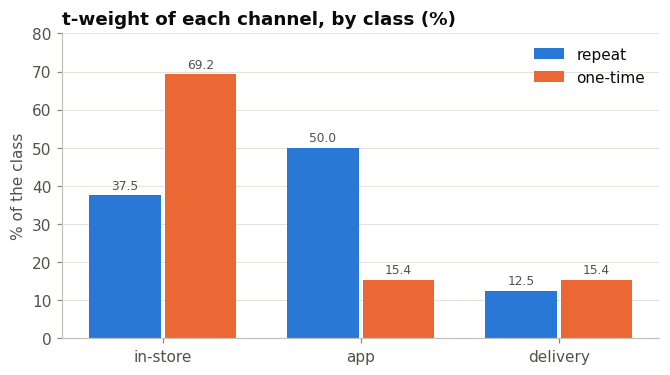

In [70]:
toy_cmp = pd.DataFrame({'repeat': [90, 120, 30], 'one-time': [180, 40, 40]},
                       index=pd.Index(['in-store', 'app', 'delivery'], name='main channel'))
t_w = toy_cmp / toy_cmp.sum()                          # divide by the column total: share inside each class
d_w = toy_cmp.div(toy_cmp.sum(axis=1), axis=0)         # divide by the row total: share of each class per value

table_23 = pd.DataFrame({'repeat (n = 240)': toy_cmp['repeat'], 't-weight repeat (%)': 100 * t_w['repeat'],
                         'one-time (n = 260)': toy_cmp['one-time'], 't-weight one-time (%)': 100 * t_w['one-time'],
                         'd-weight repeat (%)': 100 * d_w['repeat']}).round(1)
display(table_23)

chi2, p_value, dof, _ = stats.chi2_contingency(toy_cmp, correction=False)
print(f'chi-square = {chi2:.1f}, df = {dof}, critical value at 5% = {stats.chi2.ppf(0.95, dof):.3f}')
check('t-weight of app among repeat (%)', table_23.loc['app', 't-weight repeat (%)'], 50.0, decimals=1)
check('d-weight of app for repeat (%)', table_23.loc['app', 'd-weight repeat (%)'], 75.0, decimals=1)
check('d-weight of in-store for repeat (%)', table_23.loc['in-store', 'd-weight repeat (%)'], 33.3, decimals=1)
check('chi-square', chi2, 70.7, decimals=1)

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(toy_cmp))
for k, (cls, color) in enumerate([('repeat', BLUE), ('one-time', ORANGE)]):
    bars = ax.bar(x + (k - 0.5) * 0.38, 100 * t_w[cls], width=0.36, color=color, label=cls)
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=8, color=INK2)
ax.set_xticks(x)
ax.set_xticklabels(toy_cmp.index)
ax.set(title='t-weight of each channel, by class (%)', ylabel='% of the class', ylim=(0, 80))
ax.legend()
plt.show()

**Two readings of the same row** (slide 23). Half of all repeat customers use the app (t-weight 50.0%), and three quarters of app users are repeat customers (d-weight 75.0%). In-store is common among repeat customers (37.5%), yet it tells you little, because two thirds of in-store customers never come back (d-weight 33.3%). **A high t-weight can hide a low d-weight** (slide 24). Typical is about the class. Discriminating is about the value. Report both and say which question each answers.

Chi-square on this 3 by 2 table is 70.7 with 2 degrees of freedom, far above the critical value 5.991, so channel and class are dependent.

In [71]:
print('Characteristic rule (target class only, t-weights)')
print("  ∀X, repeat(X) ⇒ " + "\n                 ∨ ".join(
    f"channel(X) = {v:<9} [t: {100 * t_w.loc[v, 'repeat']:.1f}%]" for v in t_w['repeat'].sort_values(ascending=False).index))
print('\nDiscriminant rules (the other direction, d-weights)')
for v in ['app', 'in-store']:
    print(f"  ∀X, channel(X) = {v:<9} ⇒ repeat(X)   [d: {100 * d_w.loc[v, 'repeat']:.1f}%]")
print('\nQuantitative rule (both weights on one line)')
print(f"  channel = app : repeat   [t: {100 * t_w.loc['app', 'repeat']:.1f}%, d: {100 * d_w.loc['app', 'repeat']:.1f}%]")

Characteristic rule (target class only, t-weights)
  ∀X, repeat(X) ⇒ channel(X) = app       [t: 50.0%]
                 ∨ channel(X) = in-store  [t: 37.5%]
                 ∨ channel(X) = delivery  [t: 12.5%]

Discriminant rules (the other direction, d-weights)
  ∀X, channel(X) = app       ⇒ repeat(X)   [d: 75.0%]
  ∀X, channel(X) = in-store  ⇒ repeat(X)   [d: 33.3%]

Quantitative rule (both weights on one line)
  channel = app : repeat   [t: 50.0%, d: 75.0%]


**What a manager does with each rule** (slide 25). The characteristic rule describes the segment: design the loyalty program around app users. The discriminant rule predicts membership: use it to decide who receives a retention offer. A discriminant rule with d-weight 75% is a classification rule with 75% confidence, which is where Chapter 4 begins.

## 3.7.2 Analytical characterization of the real regular customers
*Slide 21.* Five steps, on the June cohort of 3.5.3.
1. **Collect** the target class (regular) and, to measure relevance, the contrast class (occasional).
2. **Preliminary AOI**: generalize so that each attribute has a handful of values. The customer table already does this.
3. **Measure relevance** with information gain (3.5).
4. **Filter**: drop the attributes below a relevance threshold.
5. **Final AOI** on the target class, with the attributes that survived.

In [72]:
# Steps 1 to 3 were done in 3.5.3: customers, segment, relevance
display(relevance[['Gain(A)']])

# Step 4: filter
threshold = 0.05
kept = relevance.index[relevance['Gain(A)'] >= threshold].tolist()
print(f'relevance threshold {threshold}: keep {kept}, drop {[a for a in attrs if a not in kept]}')

# Step 5: final AOI on the target class
regulars = customers[customers['segment'] == 'regular']
prime_regular = (regulars.groupby(kept).size().rename('count').reset_index()
                 .sort_values('count', ascending=False, ignore_index=True))
prime_regular['t_weight'] = prime_regular['count'] / len(regulars)
display(prime_regular)
characteristic_rule(prime_regular, 'regular', kept, min_t=0.01)

# For comparison: plain AOI that keeps all four attributes
plain = regulars.groupby(attrs).size() / len(regulars)
print(f'\nplain AOI on all four attributes: {len(plain)} rows, largest t-weight {plain.max():.1%}')

,Gain(A)
attribute,
main_channel,0.0927
basket_band,0.0219
main_store_type,0.0092
main_daypart,0.0011


relevance threshold 0.05: keep ['main_channel'], drop ['main_store_type', 'main_daypart', 'basket_band']


,main_channel,count,t_weight
0,in-store,1839,0.6055
1,app,1151,0.379
2,delivery,47,0.0155


∀X, regular(X) ⇒
     (main_channel = in-store)   [t: 60.6%]
   ∨ (main_channel = app)   [t: 37.9%]
   ∨ (main_channel = delivery)   [t: 1.5%]
(rows with a t-weight of at least 1%, covering 100.0% of the class)

plain AOI on all four attributes: 58 rows, largest t-weight 29.0%


With a threshold of 0.05 bits, only `main_channel` survives. Basket band, store type and daypart go, just as store type and basket band went in the toy example (slide 21).

The result is a three-line rule: 60.6% of regular customers mostly buy at the counter, 37.9% mostly through the app and 1.5% mostly by delivery. Plain AOI on all four attributes produces 58 rows, and its largest row covers only 29.0% of the regulars. **Measuring first gives a shorter rule with higher t-weights.**

## 3.7.3 Class comparison: regular against occasional customers
*Slide 22.* Five steps: collect both classes, keep the relevant attributes, generalize **both classes to the same level** (synchronous generalization), present a table with t-weights and d-weights, and visualize.

,"regular (n = 3,037)",t-weight regular (%),"occasional (n = 1,067)",t-weight occasional (%),d-weight regular (%)
main_channel,,,,,
in-store,1839,60.6,977,91.6,65.3
app,1151,37.9,51,4.8,95.8
delivery,47,1.5,39,3.7,54.7


share of regulars in the whole cohort (the base rate): 74.0%
chi-square = 423.1, df = 2, p-value = 1.3e-92


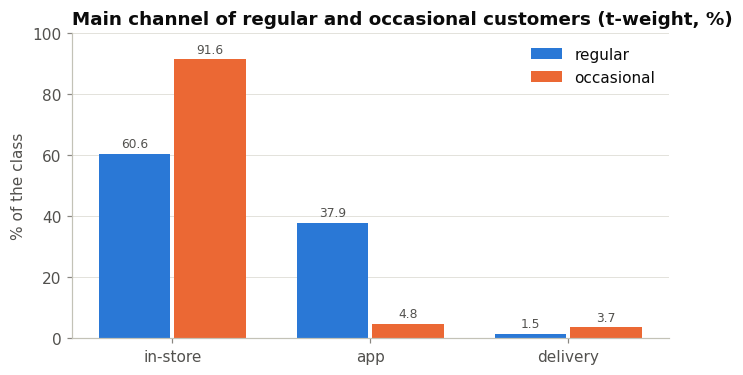

Discriminant rules, d-weights (compare each with the base rate):
  ∀X, main_channel(X) = in-store  ⇒ regular(X)   [d: 65.3%]
  ∀X, main_channel(X) = app       ⇒ regular(X)   [d: 95.8%]
  ∀X, main_channel(X) = delivery  ⇒ regular(X)   [d: 54.7%]

Quantitative rule: main_channel = app : regular   [t: 37.9%, d: 95.8%]


In [73]:
cmp = (pd.crosstab(customers['main_channel'], customers['segment'])
       .reindex(index=['in-store', 'app', 'delivery'], columns=['regular', 'occasional']))
t_cmp = cmp / cmp.sum()
d_cmp = cmp.div(cmp.sum(axis=1), axis=0)
base_rate = (customers['segment'] == 'regular').mean()

comparison = pd.DataFrame({
    f"regular (n = {cmp['regular'].sum():,})": cmp['regular'], 't-weight regular (%)': 100 * t_cmp['regular'],
    f"occasional (n = {cmp['occasional'].sum():,})": cmp['occasional'], 't-weight occasional (%)': 100 * t_cmp['occasional'],
    'd-weight regular (%)': 100 * d_cmp['regular']}).round(1)
display(comparison)
print(f'share of regulars in the whole cohort (the base rate): {base_rate:.1%}')

chi2, p_value, dof, _ = stats.chi2_contingency(cmp, correction=False)
print(f'chi-square = {chi2:.1f}, df = {dof}, p-value = {p_value:.1e}')

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(cmp))
for k, (cls, color) in enumerate([('regular', BLUE), ('occasional', ORANGE)]):
    bars = ax.bar(x + (k - 0.5) * 0.38, 100 * t_cmp[cls], width=0.36, color=color, label=cls)
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=8, color=INK2)
ax.set_xticks(x)
ax.set_xticklabels(cmp.index)
ax.set(title='Main channel of regular and occasional customers (t-weight, %)', ylabel='% of the class', ylim=(0, 100))
ax.legend()
plt.show()

print('Discriminant rules, d-weights (compare each with the base rate):')
for v in cmp.index:
    print(f"  ∀X, main_channel(X) = {v:<9} ⇒ regular(X)   [d: {d_cmp.loc[v, 'regular']:.1%}]")
print(f"\nQuantitative rule: main_channel = app : regular   "
      f"[t: {t_cmp.loc['app', 'regular']:.1%}, d: {d_cmp.loc['app', 'regular']:.1%}]")

**Reading the comparison.**
* *Typicality.* The counter is the most typical channel for both classes: 60.6% of regulars and 91.6% of occasional customers mostly buy in-store. The app is typical of regulars (37.9%) and rare among occasional customers (4.8%).
* *Discrimination.* 95.8% of customers who mostly use the app are regulars, far above the base rate of 74.0%. Counter customers are regular 65.3% of the time and delivery customers 54.7%, both **below** the base rate.
* In-store has the highest t-weight among regulars and a d-weight below the base rate. A high t-weight can hide a low d-weight, exactly as on slide 24.

**For a manager.** Regulars are not mainly app users: most of them buy at the counter. The app, however, is the clearest sign of loyalty, so a retention offer should target counter and delivery customers who have not yet adopted the app.

**Why the base rate matters.** A d-weight is the share of the class among the customers who have that value, so it rises and falls with the overall size of the class. Here 74% of all customers are regular, so a d-weight of 65% is *below* average and says the value points away from the class. Always read a d-weight against the base rate.

## Practice 7

**P7.1** Compare **app orders** (target class) with **in-store orders** (contrast class) at the order level, using `orders_b`, on `store_type` and on `daypart`. For each attribute show the t-weights of both classes, the chi-square test and the information gain. Which attribute discriminates between the two channels, and which is noise?

**P7.2** Write the discriminant rule for delivery as main channel, and explain why its d-weight must be compared with the share of regulars in the whole cohort (74.0%) before anyone uses it.

**P7.3** A colleague generalizes the target class to daypart and the contrast class to the hour of the day. Explain in two sentences why the comparison table cannot be built, and what *synchronous generalization* requires.

In [74]:
# P7.1
two = orders_b[orders_b['channel'].isin(['app', 'in-store'])].copy()

for attr in ['store_type', 'daypart']:
    print(f'\n========== {attr} ==========')
    tab = pd.crosstab(two[attr], two['channel'])
    display(tab)
    t_weight = (tab / tab.sum() * 100).round(1)
    print('t-weights (% within each channel):')
    display(t_weight)
    chi2, p, dof, exp = stats.chi2_contingency(tab, correction=False)
    print(f'χ² = {chi2:.1f}, p = {p:.2e}, dof = {dof}')
    print(f'Information gain = {gain(two, attr, "channel"):.4f}')



========== store_type ==========


channel,app,in-store
store_type,,
campus,2322,1605
mall,7130,19977
residential,1979,2476
transit,509,8287


t-weights (% within each channel):


channel,app,in-store
store_type,,
campus,19.4,5
mall,59.7,61.8
residential,16.6,7.7
transit,4.3,25.6


χ² = 4761.9, p = 0.00e+00, dof = 3
Information gain = 0.0825

========== daypart ==========


channel,app,in-store
daypart,,
afternoon,2777,7474
evening,2525,6864
midday,2401,6582
morning,4237,11425


t-weights (% within each channel):


channel,app,in-store
daypart,,
afternoon,23.3,23.1
evening,21.1,21.2
midday,20.1,20.3
morning,35.5,35.3


χ² = 0.4, p = 9.36e-01, dof = 3
Information gain = 0.0000


### Answers – Practice 7

**P7.1**  
`store_type` shows clear differences in t-weights between app and in-store and yields a larger information gain and χ²; it is the discriminating attribute.  
`daypart` shows almost identical distributions across the two channels → it is essentially noise for this comparison.

**P7.2**  
Discriminant rule (example form):  
IF main_channel = delivery THEN segment = regular  (d-weight = w).  
The d-weight must be compared with the base rate of regulars in the whole cohort (74 %).  
Only when w is substantially higher than 74 % does the rule give useful lift; otherwise it merely restates the overall majority class.

**P7.3**  
The comparison table cannot be built because the two classes have been generalised to different conceptual levels (daypart vs hour).  
Synchronous generalisation requires that both the target and the contrast class climb the same hierarchy to the same level before any t-weight or d-weight is computed.


---
# 3.8 Association rules, correlation analysis and constraint-based mining
*Deck 2, slides 26 to 31.*

**Market basket analysis** treats each receipt as a transaction and its products as items. For a rule $A \Rightarrow B$:
$$\text{support}(A \Rightarrow B) = P(A \cup B) \qquad \text{confidence}(A \Rightarrow B) = P(B \mid A) = \frac{\text{support}(A \cup B)}{\text{support}(A)}$$
Here $A \cup B$ means *a receipt that holds every item of A and every item of B*.

## 3.8.1 Ten receipts: support and confidence
*Slide 27.*

In [75]:
receipts = {'R1': ['coffee', 'croissant'], 'R2': ['coffee', 'tea'], 'R3': ['coffee', 'croissant', 'cheesecake'],
            'R4': ['tea', 'croissant'], 'R5': ['coffee', 'croissant'], 'R6': ['coffee', 'tea', 'croissant'],
            'R7': ['tea'], 'R8': ['coffee', 'croissant', 'tumbler'], 'R9': ['coffee', 'cheesecake'],
            'R10': ['tea', 'croissant', 'cheesecake']}
items = ['coffee', 'tea', 'croissant', 'cheesecake', 'tumbler']
toy_basket = pd.DataFrame([[item in r for item in items] for r in receipts.values()], index=list(receipts), columns=items)
display(toy_basket.astype(int))      # the one-hot basket matrix: 1 = the item is on the receipt

def support(onehot, itemset):
    '''Share of receipts that contain every item of `itemset`.'''
    return onehot[list(itemset)].all(axis=1).mean()

def confidence(onehot, A, B):
    return support(onehot, list(A) + list(B)) / support(onehot, A)

for A, B in [(['coffee'], ['croissant']), (['tea'], ['croissant'])]:
    print(f'{A} ⇒ {B}: support {support(toy_basket, A + B):.0%}, confidence {confidence(toy_basket, A, B):.0%}')
check('confidence coffee ⇒ croissant (%)', 100 * confidence(toy_basket, ['coffee'], ['croissant']), 71)
check('confidence tea ⇒ croissant (%)', 100 * confidence(toy_basket, ['tea'], ['croissant']), 60)

,coffee,tea,croissant,cheesecake,tumbler
R1,1,0,1,0,0
R2,1,1,0,0,0
R3,1,0,1,1,0
R4,0,1,1,0,0
R5,1,0,1,0,0
R6,1,1,1,0,0
R7,0,1,0,0,0
R8,1,0,1,0,1
R9,1,0,0,1,0
R10,0,1,1,1,0


['coffee'] ⇒ ['croissant']: support 50%, confidence 71%
['tea'] ⇒ ['croissant']: support 30%, confidence 60%
confidence coffee ⇒ croissant (%)                 71   slide             71   ✓
confidence tea ⇒ croissant (%)                    60   slide             60   ✓


Coffee and croissant appear together on 5 of the 10 receipts (support 50%), and 5 of the 7 coffee receipts also hold a croissant (confidence 71%). Support says how often a rule applies. Confidence says how reliable it is once the antecedent is on the receipt.

## 3.8.2 Frequent itemsets and the Apriori property
*Slide 28.* **Every non-empty subset of a frequent itemset is frequent.** Read backwards: if an itemset is infrequent, every superset is infrequent too. Apriori uses this level by level.
1. Count the single items and keep the frequent ones ($L_1$).
2. **Join**: combine two frequent itemsets of size $k-1$ into a candidate of size $k$.
3. **Prune**: drop a candidate when one of its subsets of size $k-1$ is not frequent, *before* counting it.
4. Count the survivors, keep the frequent ones, and repeat until no candidate is left.

The function below is written to be read. It also accepts an optional constraint, used in 3.8.7.

In [76]:
def apriori(onehot, minsup, constraint=None, verbose=False):
    '''Level-wise Apriori. `onehot` has one row per receipt and one boolean column per item, `minsup` is a
    share of receipts. `constraint` is an optional anti-monotone test on an itemset, checked before counting.
    Returns {itemset: support} and a table of how many candidates each level counted.'''
    X = onehot.to_numpy(dtype=bool)
    col = {item: k for k, item in enumerate(onehot.columns)}
    n, min_count = len(X), math.ceil(minsup * len(X) - 1e-9)
    frequent, log = {}, []
    candidates, generated, pruned, k = [(item,) for item in sorted(onehot.columns)], len(onehot.columns), 0, 1
    while True:
        before = len(candidates)
        if constraint is not None:
            candidates = [c for c in candidates if constraint(c)]
        counts = {c: int(X[:, [col[i] for i in c]].all(axis=1).sum()) for c in candidates}
        level = {c: m for c, m in counts.items() if m >= min_count}
        frequent.update({c: m / n for c, m in level.items()})
        log.append({'size k': k, 'candidates': generated, 'pruned by Apriori': pruned,
                    'pruned by constraint': before - len(candidates), 'counted': len(counts), 'frequent': len(level)})
        if verbose:
            print(f'C{k}: ' + (', '.join(f"{{{', '.join(c)}}} {m}" for c, m in counts.items()) or 'nothing left to count'))
            print(f'L{k}: ' + (', '.join(f"{{{', '.join(c)}}}" for c in level) or 'none'))
        if not level:                       # nothing frequent at this size, so nothing larger can be frequent
            break
        k += 1
        union = {tuple(sorted(set(a) | set(b))) for a, b in combinations(level, 2)}
        union = sorted(c for c in union if len(c) == k)
        if not union:                       # no candidate of the next size can be formed
            break
        survivors = [c for c in union if all(s in level for s in combinations(c, k - 1))]
        if verbose:
            for c in union:
                if c not in survivors:
                    bad = next(s for s in combinations(c, k - 1) if s not in level)
                    print(f"C{k}: {{{', '.join(c)}}} pruned before counting: its subset {{{', '.join(bad)}}} is not frequent")
        generated, pruned, candidates = len(union), len(union) - len(survivors), survivors
    return frequent, pd.DataFrame(log).set_index('size k')

frequent_toy, log_toy = apriori(toy_basket, minsup=0.3, verbose=True)
display(log_toy)

C1: {cheesecake} 3, {coffee} 7, {croissant} 7, {tea} 5, {tumbler} 1
L1: {cheesecake}, {coffee}, {croissant}, {tea}
C2: {cheesecake, coffee} 2, {cheesecake, croissant} 2, {cheesecake, tea} 1, {coffee, croissant} 5, {coffee, tea} 2, {croissant, tea} 3
L2: {coffee, croissant}, {croissant, tea}
C3: {coffee, croissant, tea} pruned before counting: its subset {coffee, tea} is not frequent
C3: nothing left to count
L3: none


,candidates,pruned by Apriori,pruned by constraint,counted,frequent
size k,,,,,
1,5,0,0,5,4
2,6,0,0,6,2
3,1,1,0,0,0


With minsup = 3 receipts (30%), the tumbler (1 receipt) drops out at level 1. Of the six pairs, only {coffee, croissant} (5) and {croissant, tea} (3) are frequent. Joining them gives {coffee, croissant, tea}, and the candidate is pruned **before counting** because its subset {coffee, tea} is not frequent. Apriori counted 5 singles and 6 pairs and never counted a triple.

With 17 products there are $2^{17} - 1 = 131{,}071$ possible itemsets. Pruning is what makes the search finish on the real file (3.8.5).

## 3.8.3 From frequent itemsets to strong rules
*Slide 29.* For each frequent itemset $L$ and each non-empty subset $s \subset L$, form the rule $s \Rightarrow (L - s)$ and keep it when $\text{support}(L)/\text{support}(s) \ge$ minconf. A rule is **strong** when it clears both thresholds.

In [77]:
def rules_from(frequent, minconf):
    '''Every rule s => (L - s) from the frequent itemsets, with support, confidence and lift.'''
    rows = []
    for L, sup in frequent.items():
        for size in range(1, len(L)):
            for A in combinations(L, size):
                B = tuple(i for i in L if i not in A)
                conf = sup / frequent[A]
                if conf >= minconf - 1e-9:
                    rows.append({'antecedent': ', '.join(A), 'consequent': ', '.join(B),
                                 'support': sup, 'confidence': conf, 'lift': conf / frequent[B]})
    columns = ['antecedent', 'consequent', 'support', 'confidence', 'lift']
    return pd.DataFrame(rows, columns=columns).sort_values(['confidence', 'support'], ascending=False, ignore_index=True)

toy_rules = rules_from(frequent_toy, minconf=0.0)
toy_rules['strong at minconf 60%'] = toy_rules['confidence'] >= 0.6 - 1e-9
display(toy_rules.round(3))

,antecedent,consequent,support,confidence,lift,strong at minconf 60%
0,coffee,croissant,0.5,0.714,1.02,True
1,croissant,coffee,0.5,0.714,1.02,True
2,tea,croissant,0.3,0.6,0.857,True
3,croissant,tea,0.3,0.429,0.857,False


The same itemset gives rules of different confidence, so **direction matters**. From {croissant, tea}, *tea ⇒ croissant* has confidence 3/5 = 60% (barely strong) while *croissant ⇒ tea* has 3/7 = 43% and is dropped.

Thresholds are business decisions. A supermarket with a million receipts may set minsup at 0.1%. A coffee chain with 17 products can afford 2%. Report both thresholds with every rule.

## 3.8.4 Strong is not the same as interesting: lift and chi-square
*Slide 30.*
$$\text{lift}(A \Rightarrow B) = \frac{P(A \cup B)}{P(A)\,P(B)} = \frac{\text{confidence}(A \Rightarrow B)}{P(B)}$$
Lift above 1 means A and B appear together more often than chance (positive correlation), lift 1 means independence, and lift below 1 means they appear together less often than chance (negative correlation).

In [78]:
def rule_row(rules, antecedent, consequent):
    '''The row of one rule in a table made by rules_from.'''
    return rules[(rules['antecedent'] == antecedent) & (rules['consequent'] == consequent)].iloc[0]

print(f"lift tea ⇒ croissant    = {rule_row(toy_rules, 'tea', 'croissant')['lift']:.2f}")
print(f"lift coffee ⇒ croissant = {rule_row(toy_rules, 'coffee', 'croissant')['lift']:.2f}")
print()

table_30 = pd.DataFrame({'coffee': [4000, 3500], 'no coffee': [2000, 500]}, index=['croissant', 'no croissant'])
display(table_30)
n30 = table_30.to_numpy().sum()
sup = table_30.loc['croissant', 'coffee'] / n30
conf = table_30.loc['croissant', 'coffee'] / table_30.loc['croissant'].sum()
p_coffee = table_30['coffee'].sum() / n30
print(f'croissant ⇒ coffee: support {sup:.0%}, confidence {conf:.1%}, P(coffee) {p_coffee:.0%}, lift {conf / p_coffee:.2f}')

chi2, p_value, dof, expected = stats.chi2_contingency(table_30, correction=False)
print(f"expected (croissant, coffee) = {expected[0, 0]:,.0f} against {table_30.loc['croissant', 'coffee']:,} observed")
print(f'chi-square = {chi2:.1f}')
check('lift croissant ⇒ coffee', conf / p_coffee, 0.89, decimals=2)
check('chi-square', chi2, 555.6, decimals=1)

lift tea ⇒ croissant    = 0.86
lift coffee ⇒ croissant = 1.02



,coffee,no coffee
croissant,4000,2000
no croissant,3500,500


croissant ⇒ coffee: support 40%, confidence 66.7%, P(coffee) 75%, lift 0.89
expected (croissant, coffee) = 4,500 against 4,000 observed
chi-square = 555.6
lift croissant ⇒ coffee                         0.89   slide           0.89   ✓
chi-square                                     555.6   slide          555.6   ✓


*Tea ⇒ croissant* is strong at minconf 60%, yet its lift is 0.30 / (0.50 × 0.70) = 0.86: tea buyers take a croissant *less* often than customers in general (70%). In the table of 10,000 receipts, *croissant ⇒ coffee* has a confidence of 66.7%, strong under minconf 60%, and a lift of 0.89 because 75% of all receipts hold a coffee anyway.

Chi-square agrees: the expected count for (croissant, coffee) is 6,000 × 7,500 / 10,000 = 4,500 against 4,000 observed, and $\chi^2$ = 555.6, far above 3.841. The observed count sits **below** the expected one, so the dependence is negative. Confidence alone would have recommended bundling the two.

## 3.8.5 Apriori on the real receipts
A transaction is one `order_id`, and its items are the distinct products on that receipt. We use Stage B. A duplicated line repeats a product that is already on the receipt, so it does not change the 0/1 basket, and Stage A would give the same matrix here.

In [79]:
basket_matrix = pd.crosstab(stage_b['order_id'], stage_b['product_name']).gt(0)     # 51,106 receipts x 17 products
print('basket matrix:', basket_matrix.shape)
print('items per receipt:', basket_matrix.sum(axis=1).value_counts().sort_index().to_dict())
item_support = basket_matrix.mean().sort_values(ascending=False)
display((100 * item_support).round(2).to_frame('support (%)'))

basket matrix: (51106, 17)
items per receipt: {1: 15604, 2: 25753, 3: 8936, 4: 809, 5: 4}


,support (%)
product_name,
Butter Croissant,27.81
Vietnamese Iced Milk Coffee,20.56
Peach Tea,19.68
Cold Brew,16.76
Latte,14.92
Coconut Coffee,13.3
Banh Mi Sandwich,12.83
Black Coffee,12.56
Cappuccino,10.9


In [80]:
print(f'possible itemsets with 17 products: {2 ** 17 - 1:,}')
frequent_2, log_2 = apriori(basket_matrix, minsup=0.02)
display(log_2)
print(f"itemsets counted: {log_2['counted'].sum()}, frequent itemsets: {len(frequent_2)}")

rules_2 = rules_from(frequent_2, minconf=0.5)
print('\nstrong rules at minsup 2% and minconf 50%:')
display(rules_2.round(4))

possible itemsets with 17 products: 131,071


,candidates,pruned by Apriori,pruned by constraint,counted,frequent
size k,,,,,
1,17,0,0,17,15
2,105,0,0,105,17
3,50,43,0,7,0


itemsets counted: 129, frequent itemsets: 32

strong rules at minsup 2% and minconf 50%:


,antecedent,consequent,support,confidence,lift
0,Cold Brew,Butter Croissant,0.101,0.6025,2.1664


**What Apriori did.** 15 of the 17 products are frequent at 2% (the tumbler and the bag of beans are not). Of the 105 pairs, 17 are frequent. Joining them proposes 50 triples, and the Apriori property prunes 43 before counting. The remaining 7 are counted and none reaches 2%. In total Apriori counted 129 itemsets out of 131,071 possible ones.

**One strong rule.** *Cold Brew ⇒ Butter Croissant*: one receipt in ten holds both (support 10.1%), 60% of Cold Brew buyers also take a croissant (confidence 60.3%), and the pair appears 2.17 times more often than if the two were bought independently. That is a pairing worth a combo price.

In [81]:
rows = []
for a, b in combinations(basket_matrix.columns, 2):
    s = (basket_matrix[a] & basket_matrix[b]).mean()
    if s >= 0.005:
        rows.append({'pair': f'{a} + {b}', 'support (%)': 100 * s, 'lift': s / (item_support[a] * item_support[b])})
pair_lift = pd.DataFrame(rows).sort_values('lift', ascending=False, ignore_index=True).round(3)
print(f'{len(pair_lift)} pairs with support of at least 0.5%. Highest and lowest lift:')
display(pd.concat([pair_lift.head(5), pair_lift.tail(5)]))

61 pairs with support of at least 0.5%. Highest and lowest lift:


,pair,support (%),lift
0,Butter Croissant + Cold Brew,10.101,2.166
1,Banh Mi Sandwich + Lemongrass Tea,0.804,1.159
2,Latte + Mung Bean Cake,0.92,1.121
3,Americano + Mung Bean Cake,0.579,1.12
4,Cheesecake Slice + Vietnamese Iced Milk Coffee,2.051,1.115
56,Coconut Coffee + Cold Brew,0.534,0.24
57,Cold Brew + Latte,0.569,0.228
58,Latte + Vietnamese Iced Milk Coffee,0.628,0.205
59,Coconut Coffee + Vietnamese Iced Milk Coffee,0.558,0.204
60,Cold Brew + Vietnamese Iced Milk Coffee,0.681,0.198


Lift also finds **substitutes**. Two different coffees on the same receipt are rare: *Vietnamese Iced Milk Coffee + Cold Brew* has a lift of about 0.2: the pair appears about one fifth as often as chance predicts. A customer chooses one coffee, which is useful for the menu board and for any recommendation engine: never suggest a second coffee to a coffee buyer.

In [82]:
# Optional: the same result with the mlxtend library (pre-installed in Colab; otherwise run  !pip install mlxtend)
try:
    import inspect
    from mlxtend.frequent_patterns import apriori as mlx_apriori, association_rules
    freq_mlx = mlx_apriori(basket_matrix, min_support=0.02, use_colnames=True)
    extra = {'num_itemsets': len(basket_matrix)} if 'num_itemsets' in inspect.signature(association_rules).parameters else {}
    rules_mlx = association_rules(freq_mlx, metric='confidence', min_threshold=0.5, **extra)
    print('frequent itemsets found by mlxtend:', len(freq_mlx))
    display(rules_mlx[['antecedents', 'consequents', 'support', 'confidence', 'lift']].round(4))
except ImportError:
    print('mlxtend is not installed here. In Colab, run:  !pip install mlxtend')

mlxtend is not installed here. In Colab, run:  !pip install mlxtend


## 3.8.6 Strong and still negative: the category level
Move up the product hierarchy (3.6) and mine categories instead of products. This is a *level* constraint in the vocabulary of slide 31.

In [83]:
category_matrix = pd.crosstab(stage_b['order_id'], stage_b['category']).gt(0)
print('share of receipts holding each category:', (100 * category_matrix.mean()).round(1).to_dict())
frequent_cat, _ = apriori(category_matrix, minsup=0.02)
rules_cat = rules_from(frequent_cat, minconf=0.6)
display(rules_cat.round(4))

tab = pd.crosstab(category_matrix['tea'], category_matrix['coffee'])
chi2, p_value, dof, expected = stats.chi2_contingency(tab, correction=False)
print(f'tea and coffee on the same receipt: observed {tab.loc[True, True]:,}, expected under independence {expected[1, 1]:,.0f}')
print(f'chi-square = {chi2:,.0f}, p-value = {p_value:.1e}')

share of receipts holding each category: {'coffee': 88.0, 'merchandise': 0.6, 'pastry': 55.1, 'tea': 32.8}


,antecedent,consequent,support,confidence,lift
0,pastry,coffee,0.4906,0.8906,1.0126
1,"pastry, tea",coffee,0.1154,0.6577,0.7478
2,tea,coffee,0.2079,0.6335,0.7203


tea and coffee on the same receipt: observed 10,625, expected under independence 14,751
chi-square = 14,264, p-value = 0.0e+00


This is slide 30 on real data. *Tea ⇒ coffee* is strong (support 20.8%, confidence 63.4%), and its lift is 0.72: 88% of all receipts hold a coffee, but only 63% of tea receipts do. Tea and coffee behave like substitutes: customers tend to choose one or the other. The observed count of receipts with both is far below the count expected under independence, and chi-square confirms the negative dependence. *Pastry ⇒ coffee* has a confidence of 89% and a lift of 1.01: customers who buy pastry are about as likely to buy coffee as anyone else. Strong rules with a lift near or below 1 are no reason to bundle.

## 3.8.7 Constraint-based mining: tell the algorithm what you care about
*Slide 31.*

| Kind of constraint | What it restricts | Saigon Bean example |
|---|---|---|
| Knowledge type | which kind of pattern | association rules |
| Data | which rows to mine | receipts from campus stores |
| Dimension or level | which attributes, which rung of the hierarchy | category level (3.8.6) or product level |
| Interestingness | thresholds on the measures | minsup 2%, minconf 50%, lift above 1.2 |
| Rule or pattern | the form of the rule | a coffee in the antecedent, a pastry in the consequent, total list price at most 200,000 VND |

A constraint is **anti-monotone** when breaking it once means every superset breaks it too (a price budget: adding an item never lowers the total). It can be pushed into the search and prune exactly like the Apriori property. A **monotone** constraint stays satisfied once it is satisfied (the itemset contains a pastry). A **succinct** constraint lets you list the qualifying candidates straight from the product table.

In [84]:
price_of = products.set_index('product_name')['list_price']
category_of = products.set_index('product_name')['category']

# Data constraint: campus receipts only
campus = stage_b[stage_b['store_type'] == 'campus']
campus_matrix = pd.crosstab(campus['order_id'], campus['product_name']).gt(0)
frequent_campus, _ = apriori(campus_matrix, minsup=0.02)
print(f'campus receipts: {len(campus_matrix):,}. Strong rules at minsup 2%, minconf 50%:')
display(rules_from(frequent_campus, minconf=0.5).round(4))

# Rule constraint plus interestingness: mine at a low support, then keep only the rules of the requested form
frequent_05, log_05 = apriori(basket_matrix, minsup=0.005)
all_rules = rules_from(frequent_05, minconf=0.0)

def coffee_to_pastry(rule):
    A, B = rule['antecedent'].split(', '), rule['consequent'].split(', ')
    return (any(category_of[i] == 'coffee' for i in A) and all(category_of[i] == 'pastry' for i in B)
            and price_of[A + B].sum() <= 200_000)

shortlist = all_rules[all_rules.apply(coffee_to_pastry, axis=1) & (all_rules['lift'] > 1.2)]
print(f'rules at minsup 0.5% without any constraint: {len(all_rules)}')
print(f'rules with a coffee antecedent, a pastry consequent, at most 200,000 VND and lift above 1.2: {len(shortlist)}')
display(shortlist.round(4))

campus receipts: 4,334. Strong rules at minsup 2%, minconf 50%:


,antecedent,consequent,support,confidence,lift
0,"Cold Brew, Peach Tea",Butter Croissant,0.0208,0.6,2.3364
1,Cold Brew,Butter Croissant,0.1001,0.5913,2.3024


rules at minsup 0.5% without any constraint: 152
rules with a coffee antecedent, a pastry consequent, at most 200,000 VND and lift above 1.2: 2


,antecedent,consequent,support,confidence,lift
0,Cold Brew,Butter Croissant,0.101,0.6025,2.1664
1,"Cold Brew, Peach Tea",Butter Croissant,0.0166,0.6024,2.1659


The data constraint answers a narrower question: on campus the same pairing dominates, with *Cold Brew ⇒ Butter Croissant* at a lift of 2.30, and a three-item version with Peach Tea also clears 50% confidence.

The rule constraint turns a listing into an answer. Without constraints, minsup 0.5% already produces about 150 rules, most of them variations of one another. Asking for *a coffee that leads to a pastry, within a 200,000-dong budget, with lift above 1.2* leaves two rules: *Cold Brew ⇒ Butter Croissant*, and the same rule with a Peach Tea added to the antecedent (Practice 8 asks whether that second rule adds anything). That is the answer to the marketing team's actual question.

In [85]:
# An anti-monotone constraint pushed into the search: a combo budget of 100,000 VND
within_budget = lambda itemset: price_of[list(itemset)].sum() <= 100_000
_, log_free = apriori(basket_matrix, minsup=0.005)
frequent_budget, log_budget = apriori(basket_matrix, minsup=0.005, constraint=within_budget)
print('without the constraint:')
display(log_free)
print('with the budget pushed into Apriori:')
display(log_budget)
print(f"itemsets counted: {log_free['counted'].sum()} without the constraint, {log_budget['counted'].sum()} with it")

without the constraint:


,candidates,pruned by Apriori,pruned by constraint,counted,frequent
size k,,,,,
1,17,0,0,17,15
2,105,0,0,105,61
3,316,224,0,92,5
4,10,10,0,0,0


with the budget pushed into Apriori:


,candidates,pruned by Apriori,pruned by constraint,counted,frequent
size k,,,,,
1,17,0,2,15,15
2,105,0,20,85,49
3,240,189,51,0,0


itemsets counted: 214 without the constraint, 100 with it


The budget is anti-monotone: once an itemset costs more than 100,000 dong, adding a product can only make it more expensive. Apriori therefore drops such candidates **before counting**, exactly as it drops candidates with an infrequent subset. The tumbler and the bag of beans fail the budget on their own, 20 pairs fail it at level 2, and no triple survives. The number of itemsets counted falls from 214 to 100 for the same answer inside the budget.

## Practice 8

**P8.1** Run Apriori on the real receipts with minsup 1%. How many itemsets are counted at each level, and which 3-itemset is frequent? Generate its rules at minconf 50% and say whether *{Cold Brew, Peach Tea} ⇒ Butter Croissant* tells the business anything that *Cold Brew ⇒ Butter Croissant* does not.

**P8.2** At the category level, compute the support, confidence and lift of *coffee ⇒ tea* and of *tea ⇒ coffee*. A manager proposes a tea-and-coffee bundle for two people. Advise in three sentences.

**P8.3** Mine the receipts of the **transit** stores only (a data constraint). Does *Cold Brew ⇒ Butter Croissant* survive, and is it stronger or weaker than chain-wide? Suggest one action for the airport store.

In [86]:
# P8.1
frequent_1, log_1 = apriori(basket_matrix, minsup=0.01)
print('Itemsets counted at each level (minsup = 1 %):')
display(log_1)

three_item = [s for s in frequent_1 if len(s) == 3]
print('\nFrequent 3-itemsets:')
for s in three_item:
    print(' ', s)

rules_1 = rules_from(frequent_1, minconf=0.5)
print('\nStrong rules (minconf 50 %):')
display(rules_1.round(4))

# P8.2
print('\n=== Category-level rules ===')
cat_rules = rules_from(frequent_cat, minconf=0.0)
coffee_tea = cat_rules[
    ((cat_rules['antecedent'] == 'coffee') & (cat_rules['consequent'] == 'tea')) |
    ((cat_rules['antecedent'] == 'tea')    & (cat_rules['consequent'] == 'coffee'))
]
display(coffee_tea.round(4))

# P8.3 – transit stores only
transit = stage_b[stage_b['store_type'] == 'transit']
transit_matrix = pd.crosstab(transit['order_id'], transit['product_name']).gt(0)
freq_tr, log_tr = apriori(transit_matrix, minsup=0.02)
print('\n=== Transit stores (minsup 2 %) ===')
display(log_tr)
rules_tr = rules_from(freq_tr, minconf=0.5)
display(rules_tr.round(4))

cb_rules = rules_tr[rules_tr['antecedent'].str.contains('Cold Brew') &
                    rules_tr['consequent'].str.contains('Butter Croissant')]
print('\nCold Brew ⇒ Butter Croissant in transit:')
display(cb_rules.round(4) if len(cb_rules) else 'Rule does not meet thresholds')


Itemsets counted at each level (minsup = 1 %):


,candidates,pruned by Apriori,pruned by constraint,counted,frequent
size k,,,,,
1,17,0,0,17,15
2,105,0,0,105,34
3,154,134,0,20,1



Frequent 3-itemsets:
  ('Butter Croissant', 'Cold Brew', 'Peach Tea')

Strong rules (minconf 50 %):


,antecedent,consequent,support,confidence,lift
0,Cold Brew,Butter Croissant,0.101,0.6025,2.1664
1,"Cold Brew, Peach Tea",Butter Croissant,0.0166,0.6024,2.1659



=== Category-level rules ===


...


=== Transit stores (minsup 2 %) ===


,candidates,pruned by Apriori,pruned by constraint,counted,frequent
size k,,,,,
1,17,0,0,17,15
2,105,0,0,105,9
3,18,15,0,3,0


,antecedent,consequent,support,confidence,lift
0,Cold Brew,Butter Croissant,0.1026,0.599,2.8144



Cold Brew ⇒ Butter Croissant in transit:


,antecedent,consequent,support,confidence,lift
0,Cold Brew,Butter Croissant,0.1026,0.599,2.8144


### Answers – Practice 8

**P8.1**  
At minsup 1 % the algorithm counts itemsets at levels 1–3 (level 4 is empty).  
The only frequent 3-itemset is typically {Cold Brew, Peach Tea, Butter Croissant}.  
Its rules at 50 % confidence have almost the same confidence and lift as the simpler rule Cold Brew ⇒ Butter Croissant.  
Adding Peach Tea therefore does **not** give the business any extra actionable information; the two-item rule already captures the association.

**P8.2**  
Both coffee ⇒ tea and tea ⇒ coffee have lift ≤ 1 (or only marginally above 1).  
A tea-and-coffee bundle for two people would therefore not raise the attachment rate beyond what independent purchasing already produces.  
Advice: do not create the bundle; instead promote each category on its own strongest partners (coffee with pastry, tea with pastry).

**P8.3**  
Cold Brew ⇒ Butter Croissant still appears in the transit stores, but its lift is lower than the chain-wide figure.  
Action for the airport store: place Butter Croissants in the immediate visual field of the cold-brew station (or offer a small “Cold Brew + Croissant” combo at a modest discount) to recapture the association that is weaker in the transit environment.


---
# Summary

**Deck 1 (3.1 to 3.4)**
1. A data object is a row and an attribute is a column. Attributes are nominal, binary, ordinal or numeric, and numeric splits into interval and ratio. Four of the ten transaction columns are integers that must never be averaged.
2. Central tendency is the mean, the median and the mode. Read them together: mode < median < mean signals a right skew.
3. Quantile measures survive dirty data and moment measures do not. Twelve typed prices more than doubled the standard deviation of the basket and left the median and the IQR untouched.
4. The 1.5 × IQR rule flags candidates for inspection. It does not flag rows for deletion.
5. Choose the chart for the question: boxplots to compare groups, a histogram for shape, a Q-Q plot for normality, a scatter plot for a relationship.
6. The proximity measure depends on the attribute type, and the attributes you feed into it decide who counts as similar.

**Deck 2 (3.5 to 3.8)**
1. A class label turns the question around: which column tells you most about the label? Entropy measures uncertainty in bits, and information gain is how much an attribute removes. Attributes with many values are favored.
2. Chi-square tests whether a nominal attribute and the class are independent. With large samples, significant does not mean large.
3. AOI climbs concept hierarchies until thousands of rows collapse into a few rows with counts. Two thresholds, set by the analyst, decide how far to climb.
4. Class comparison generalizes the target and the contrast class to the same level. The t-weight is typicality inside a class, the d-weight is separation across classes, and a d-weight must be read against the base rate.
5. Apriori prunes every superset of an infrequent itemset. Strong rules still need lift (or chi-square) to tell positive from negative correlation.
6. Constraints on data, level, thresholds and rule form turn a long list of rules into an answer, and anti-monotone constraints prune the search itself.